In [1]:
!pip install nibabel numpy scikit-learn matplotlib tifffile tqdm torch torchvision split-folders


Train: 180 | Val: 78 | Test: 111


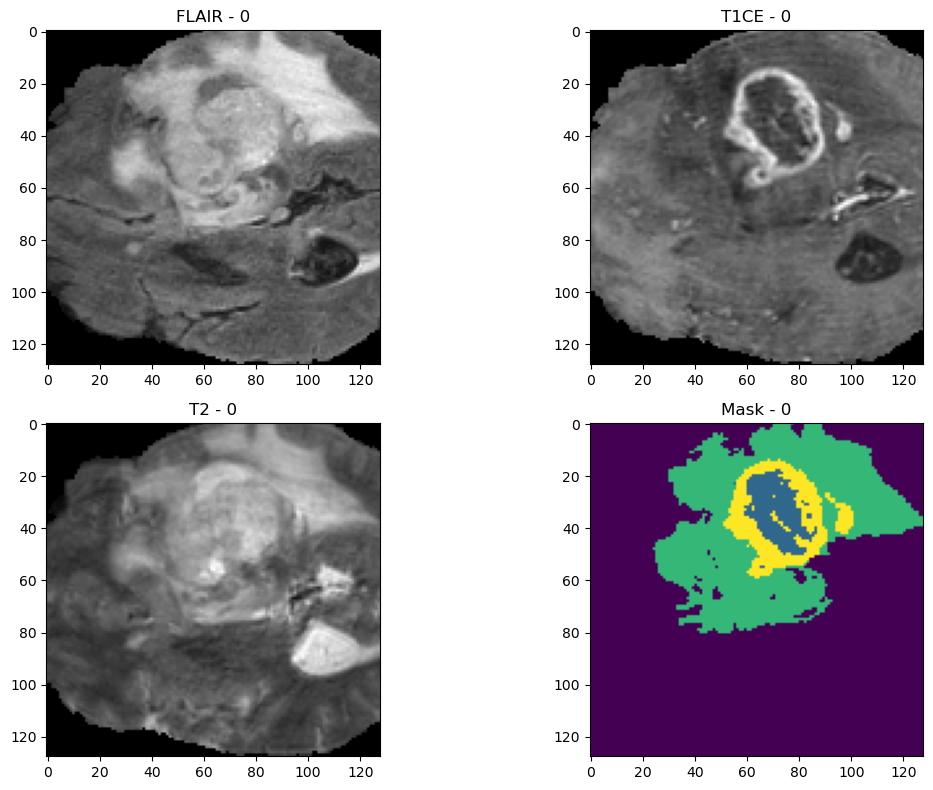

✅ Saved test/image_0.npy


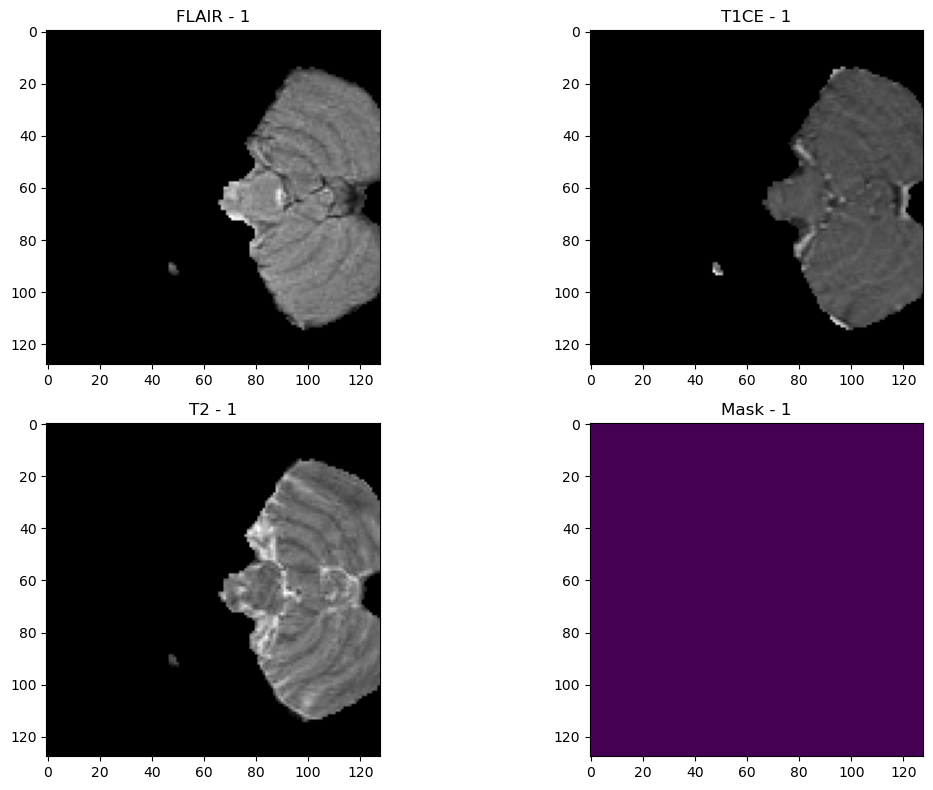

✅ Saved train/image_1.npy


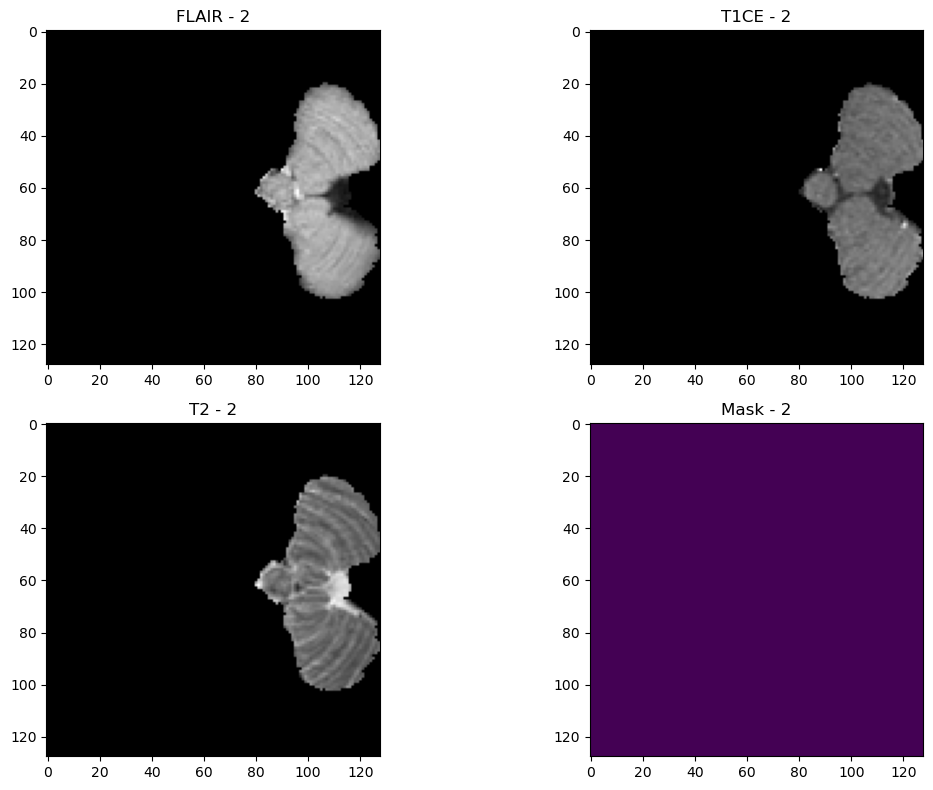

✅ Saved val/image_2.npy
✅ Saved test/image_3.npy
✅ Saved test/image_5.npy
✅ Saved val/image_6.npy
✅ Saved test/image_7.npy
✅ Saved train/image_8.npy
✅ Saved test/image_9.npy
✅ Saved train/image_10.npy
✅ Saved train/image_11.npy
✅ Saved train/image_12.npy
✅ Saved val/image_13.npy
✅ Saved train/image_14.npy
✅ Saved test/image_15.npy
✅ Saved test/image_16.npy
✅ Saved test/image_17.npy
✅ Saved val/image_18.npy
✅ Saved val/image_19.npy
✅ Saved val/image_20.npy
✅ Saved train/image_21.npy
✅ Saved test/image_22.npy
✅ Saved train/image_23.npy
✅ Saved test/image_24.npy
✅ Saved test/image_25.npy
✅ Saved val/image_26.npy
✅ Saved train/image_28.npy
✅ Saved train/image_29.npy
✅ Saved test/image_30.npy
✅ Saved train/image_31.npy
✅ Saved train/image_32.npy
✅ Saved test/image_33.npy
✅ Saved val/image_34.npy
✅ Saved train/image_36.npy
✅ Saved train/image_37.npy
✅ Saved train/image_38.npy
✅ Saved test/image_39.npy
✅ Saved train/image_40.npy
✅ Saved val/image_41.npy
✅ Saved test/image_42.npy
✅ Saved train

In [2]:
import os
import numpy as np
import nibabel as nib
import torch
import glob
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import random
from sklearn.model_selection import train_test_split
from tifffile import imwrite

# ---------------- Setup ----------------
scaler = MinMaxScaler()

RAW_DATASET = r"C:/Users/STUDENT/Downloads/BRATS DATASET/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
OUTPUT_DIR = "BraTS2020_TrainingData"
INPUT_3CH_DIR = os.path.join(OUTPUT_DIR, "input_data_128")

# Final output folders
SPLITS = ["train", "val", "test"]
for split in SPLITS:
    os.makedirs(os.path.join(INPUT_3CH_DIR, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(INPUT_3CH_DIR, split, "masks"), exist_ok=True)

def normalize(img):
    return scaler.fit_transform(img.reshape(-1, 1)).reshape(img.shape)

def one_hot_encode_mask(mask, num_classes=4):
    return np.eye(num_classes)[mask.astype(np.uint8)]

# ---------------- Gather File Lists ----------------
t2_list = sorted(glob.glob(f"{RAW_DATASET}/*/*t2.nii"))
t1ce_list = sorted(glob.glob(f"{RAW_DATASET}/*/*t1ce.nii"))
flair_list = sorted(glob.glob(f"{RAW_DATASET}/*/*flair.nii"))
mask_list = sorted(glob.glob(f"{RAW_DATASET}/*/*seg.nii"))

# ---------------- Split into 70% trainval, 30% test ----------------
full_indices = list(range(len(t2_list)))
trainval_indices, test_indices = train_test_split(full_indices, test_size=0.3, random_state=42)
train_indices, val_indices = train_test_split(trainval_indices, test_size=0.3, random_state=42)

print(f"Train: {len(train_indices)} | Val: {len(val_indices)} | Test: {len(test_indices)}")

# ---------------- Process and Save ----------------
for idx in range(len(t2_list)):
    try:
        # Load modalities
        flair = normalize(nib.load(flair_list[idx]).get_fdata())
        t1ce = normalize(nib.load(t1ce_list[idx]).get_fdata())
        t2 = normalize(nib.load(t2_list[idx]).get_fdata())
        mask = nib.load(mask_list[idx]).get_fdata().astype(np.uint8)
        mask[mask == 4] = 3

        # Stack and crop
        combined = np.stack([flair, t1ce, t2], axis=-1)
        combined = combined[56:184, 56:184, 13:141]
        mask = mask[56:184, 56:184, 13:141]

        non_zero_ratio = 1 - (np.count_nonzero(mask == 0) / mask.size)
        if non_zero_ratio <= 0.01:
            continue

        # Choose split
        if idx in train_indices:
            split = "train"
        elif idx in val_indices:
            split = "val"
        elif idx in test_indices:
            split = "test"
        else:
            continue  # skip if index not found

        # Save to respective folder
        out_img = os.path.join(INPUT_3CH_DIR, split, "images", f"image_{idx}.npy")
        out_mask = os.path.join(INPUT_3CH_DIR, split, "masks", f"mask_{idx}.npy")

        np.save(out_img, combined)
        np.save(out_mask, one_hot_encode_mask(mask, num_classes=4))

        # Optionally visualize
        if idx < 3:
            slice_id = random.randint(0, mask.shape[2] - 1)
            plt.figure(figsize=(12, 8))
            plt.subplot(221); plt.imshow(combined[:, :, slice_id, 0], cmap='gray'); plt.title(f'FLAIR - {idx}')
            plt.subplot(222); plt.imshow(combined[:, :, slice_id, 1], cmap='gray'); plt.title(f'T1CE - {idx}')
            plt.subplot(223); plt.imshow(combined[:, :, slice_id, 2], cmap='gray'); plt.title(f'T2 - {idx}')
            plt.subplot(224); plt.imshow(mask[:, :, slice_id]); plt.title(f'Mask - {idx}')
            plt.tight_layout(); plt.show()

        print(f"✅ Saved {split}/image_{idx}.npy")

    except Exception as e:
        print(f"❌ Error at idx {idx}: {e}")

print("✅ Preprocessing and custom split completed!")


Epoch 1/100: 100%|███████████████████████████████████████████████████████████████████| 170/170 [01:07<00:00,  2.53it/s]


✅ Epoch 1/100 | Train Loss: 0.4689, IoU: 0.1148, Dice: 0.1245 | Val Loss: 0.4396, IoU: 0.1746, Dice: 0.1952
💾 Best model updated!


Epoch 2/100: 100%|███████████████████████████████████████████████████████████████████| 170/170 [01:02<00:00,  2.73it/s]


✅ Epoch 2/100 | Train Loss: 0.3924, IoU: 0.3026, Dice: 0.2828 | Val Loss: 0.3784, IoU: 0.2900, Dice: 0.3110
💾 Best model updated!


Epoch 3/100: 100%|███████████████████████████████████████████████████████████████████| 170/170 [01:01<00:00,  2.75it/s]


...

✅ Epoch 70/100 | Train Loss: 0.0751, IoU: 0.7995, Dice: 0.8749 | Val Loss: 0.1135, IoU: 0.7242, Dice: 0.8130


Epoch 71/100: 100%|██████████████████████████████████████████████████████████████████| 170/170 [01:02<00:00,  2.71it/s]


✅ Epoch 71/100 | Train Loss: 0.0734, IoU: 0.8039, Dice: 0.8785 | Val Loss: 0.1155, IoU: 0.7178, Dice: 0.8096


Epoch 72/100: 100%|██████████████████████████████████████████████████████████████████| 170/170 [01:02<00:00,  2.74it/s]


✅ Epoch 72/100 | Train Loss: 0.0739, IoU: 0.8043, Dice: 0.8772 | Val Loss: 0.1131, IoU: 0.7221, Dice: 0.8130
⏹️ Early stopping triggered.
✅ Best model saved to 'best_model_seg.pth'


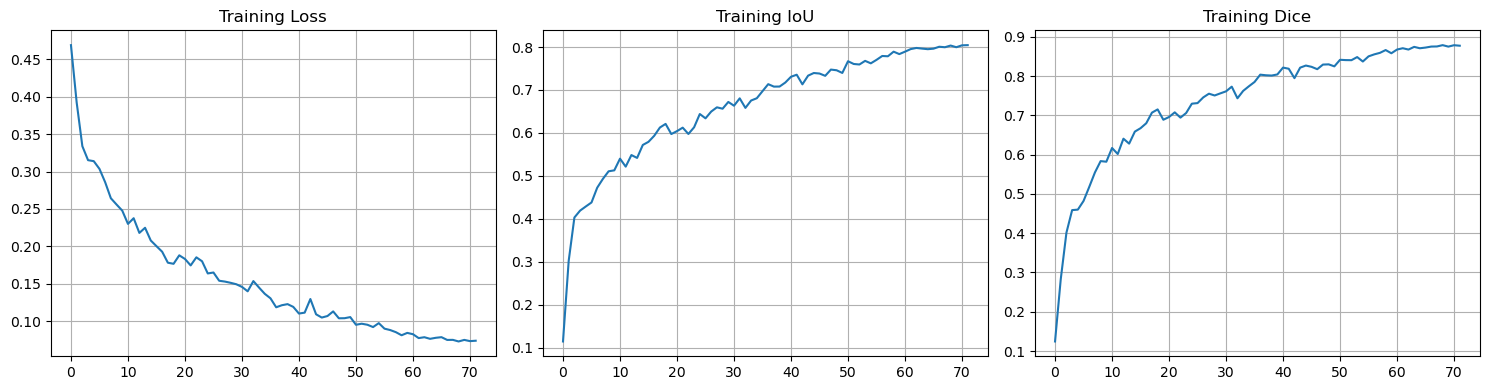

📊 Training curves saved as 'training_curves.png'


In [3]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import random

# -------------------- Dataset --------------------
class BraTSDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_paths = sorted([os.path.join(image_dir, f) for f in os.listdir(image_dir)])
        self.mask_paths = sorted([os.path.join(mask_dir, f) for f in os.listdir(mask_dir)])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = np.load(self.image_paths[idx])  # shape: (128, 128, 128, 3)
        mask = np.load(self.mask_paths[idx])    # shape: (128, 128, 128, 4)

        # Convert multi-channel to single-channel binary
        mask = np.argmax(mask, axis=-1)  # shape: (128, 128, 128)
        mask = (mask > 0).astype(np.float32)
        mask = np.expand_dims(mask, axis=0)  # shape: (1, 128, 128, 128)

        # Transpose image to (3, D, H, W)
        image = np.transpose(image, (3, 0, 1, 2))

        return torch.tensor(image, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32)

# -------------------- 3D U-Net --------------------
class UNet3D(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, init_features=16):
        super(UNet3D, self).__init__()
        features = init_features
        self.encoder1 = self.contract_block(in_channels, features)
        self.encoder2 = self.contract_block(features, features * 2)
        self.encoder3 = self.contract_block(features * 2, features * 4)
        self.encoder4 = self.contract_block(features * 4, features * 8)
        self.bottleneck = self.contract_block(features * 8, features * 16, dropout=0.3)

        self.upconv4 = self.expand_block(features * 16, features * 8)
        self.decoder4 = self.contract_block(features * 16, features * 8)

        self.upconv3 = self.expand_block(features * 8, features * 4)
        self.decoder3 = self.contract_block(features * 8, features * 4)

        self.upconv2 = self.expand_block(features * 4, features * 2)
        self.decoder2 = self.contract_block(features * 4, features * 2)

        self.upconv1 = self.expand_block(features * 2, features)
        self.decoder1 = self.contract_block(features * 2, features)

        self.out_conv = nn.Conv3d(features, out_channels, kernel_size=1)

    def contract_block(self, in_channels, out_channels, dropout=0.1):
        return nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Dropout3d(dropout),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def expand_block(self, in_channels, out_channels):
        return nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

    def forward(self, x):
        c1 = self.encoder1(x); p1 = F.max_pool3d(c1, 2)
        c2 = self.encoder2(p1); p2 = F.max_pool3d(c2, 2)
        c3 = self.encoder3(p2); p3 = F.max_pool3d(c3, 2)
        c4 = self.encoder4(p3); p4 = F.max_pool3d(c4, 2)
        bn = self.bottleneck(p4)
        u4 = self.upconv4(bn)
        d4 = self.decoder4(torch.cat([u4, c4], dim=1))
        u3 = self.upconv3(d4)
        d3 = self.decoder3(torch.cat([u3, c3], dim=1))
        u2 = self.upconv2(d3)
        d2 = self.decoder2(torch.cat([u2, c2], dim=1))
        u1 = self.upconv1(d2)
        d1 = self.decoder1(torch.cat([u1, c1], dim=1))
        return self.out_conv(d1)

# -------------------- Losses & Metrics --------------------
class BinaryDiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(-1)
        targets = targets.view(-1)
        intersection = (probs * targets).sum()
        return 1 - (2. * intersection + self.smooth) / (probs.sum() + targets.sum() + self.smooth)

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        BCE = F.binary_cross_entropy(probs, targets, reduction='none')
        pt = torch.where(targets == 1, probs, 1 - probs)
        return (self.alpha * (1 - pt) ** self.gamma * BCE).mean()

def binary_iou(preds, targets, smooth=1e-6):
    preds = preds.view(-1)
    targets = targets.view(-1)
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# -------------------- Early Stopping --------------------
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

# -------------------- Training Setup --------------------
train_dataset = BraTSDataset("BraTS2020_TrainingData/input_data_128/train/images", "BraTS2020_TrainingData/input_data_128/train/masks")
val_dataset = BraTSDataset("BraTS2020_TrainingData/input_data_128/val/images", "BraTS2020_TrainingData/input_data_128/val/masks")

train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet3D(in_channels=3, out_channels=1).to(device)

focal = FocalLoss()
dice = BinaryDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)
early_stopper = EarlyStopping(patience=10)

num_epochs = 100
best_model_state = None
best_loss = float('inf')

loss_log, iou_log, dice_log, val_loss_log = [], [], [], []

# -------------------- Training Loop --------------------
for epoch in range(num_epochs):
    model.train()
    total_loss, total_iou, total_dice = 0, 0, 0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        loss = 0.5 * focal(outputs, masks) + 0.5 * dice(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        preds = (torch.sigmoid(outputs) > 0.3).float()
        total_loss += loss.item()
        total_iou += binary_iou(preds, masks).item()
        total_dice += 1 - dice(outputs, masks).item()

    avg_loss = total_loss / len(train_loader)
    avg_iou = total_iou / len(train_loader)
    avg_dice = total_dice / len(train_loader)

    # Validation
    model.eval()
    val_loss, val_iou, val_dice = 0, 0, 0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = 0.5 * focal(outputs, masks) + 0.5 * dice(outputs, masks)

            preds = (torch.sigmoid(outputs) > 0.3).float()
            val_loss += loss.item()
            val_iou += binary_iou(preds, masks).item()
            val_dice += 1 - dice(outputs, masks).item()

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = val_iou / len(val_loader)
    avg_val_dice = val_dice / len(val_loader)

    print(f"✅ Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {avg_loss:.4f}, IoU: {avg_iou:.4f}, Dice: {avg_dice:.4f} | "
          f"Val Loss: {avg_val_loss:.4f}, IoU: {avg_val_iou:.4f}, Dice: {avg_val_dice:.4f}")

    loss_log.append(avg_loss)
    iou_log.append(avg_iou)
    dice_log.append(avg_dice)
    val_loss_log.append(avg_val_loss)

    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        best_model_state = model.state_dict()
        print("💾 Best model updated!")

    early_stopper(avg_val_loss)
    scheduler.step(avg_val_loss)
    if early_stopper.early_stop:
        print("⏹️ Early stopping triggered.")
        break

# -------------------- Save Best Model --------------------
if best_model_state:
    torch.save(best_model_state, "best_model_seg.pth")
    print("✅ Best model saved to 'best_model_seg.pth'")

# -------------------- Plot Training Curves --------------------
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); plt.plot(loss_log); plt.title("Training Loss"); plt.grid()
plt.subplot(1, 3, 2); plt.plot(iou_log); plt.title("Training IoU"); plt.grid()
plt.subplot(1, 3, 3); plt.plot(dice_log); plt.title("Training Dice"); plt.grid()
plt.tight_layout(); plt.savefig("training_curves.png"); plt.show()
print("📊 Training curves saved as 'training_curves.png'")


In [4]:
!pip install numpy nibabel matplotlib torch

  0%|                                                                                          | 0/105 [00:00<?, ?it/s]

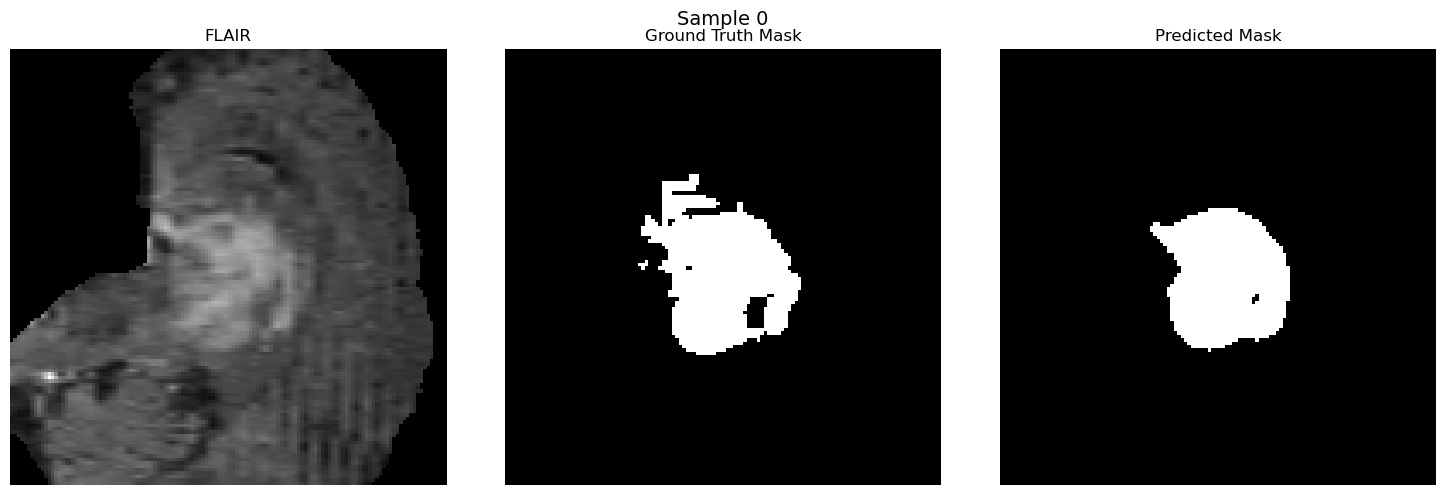

  1%|▊                                                                                 | 1/105 [00:00<01:07,  1.54it/s]

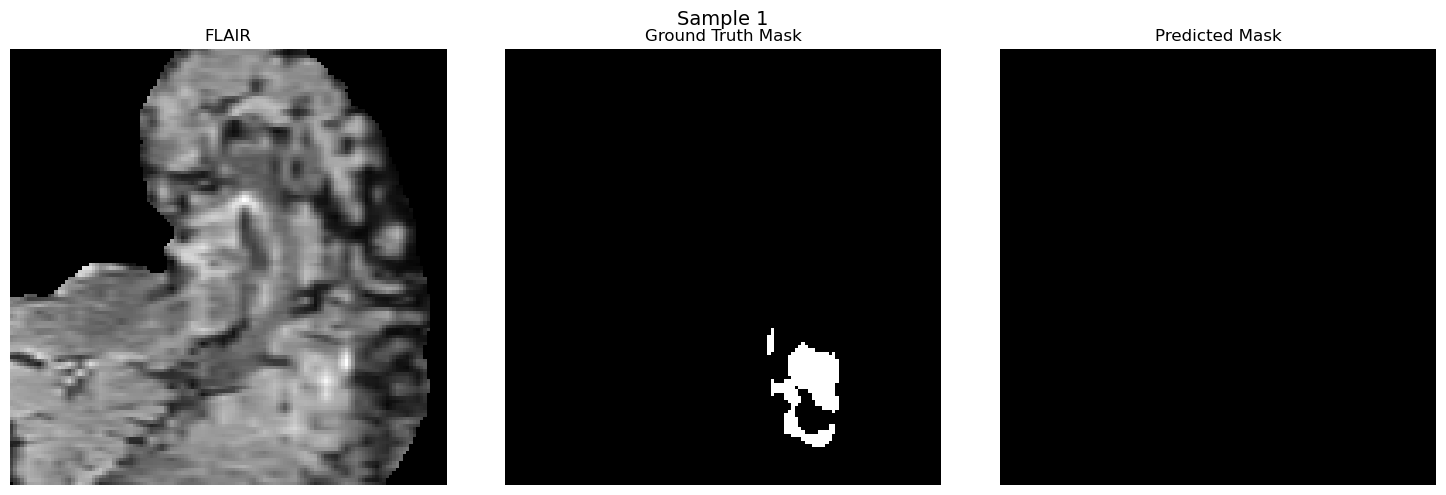

  2%|█▌                                                                                | 2/105 [00:01<00:51,  2.01it/s]

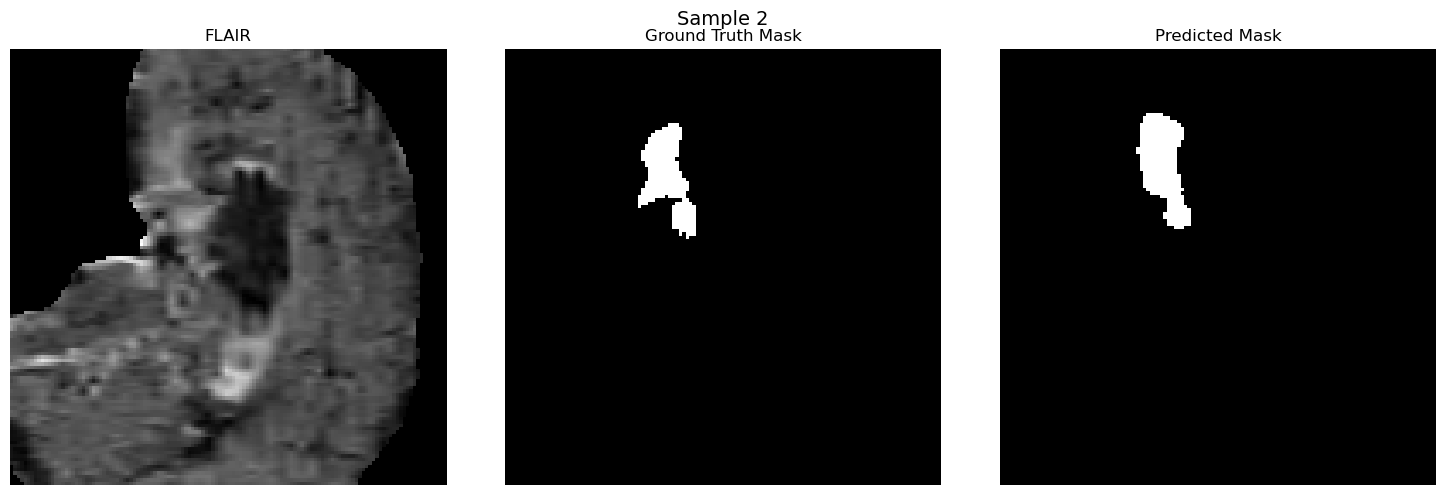

  3%|██▎                                                                               | 3/105 [00:01<00:41,  2.46it/s]

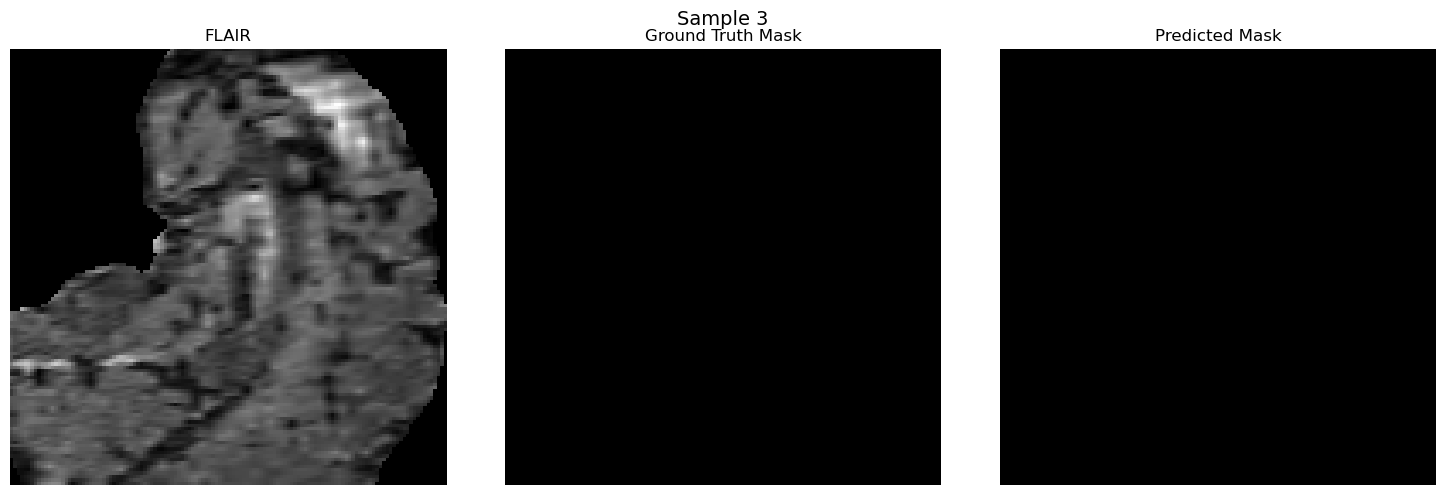

  4%|███                                                                               | 4/105 [00:01<00:39,  2.54it/s]

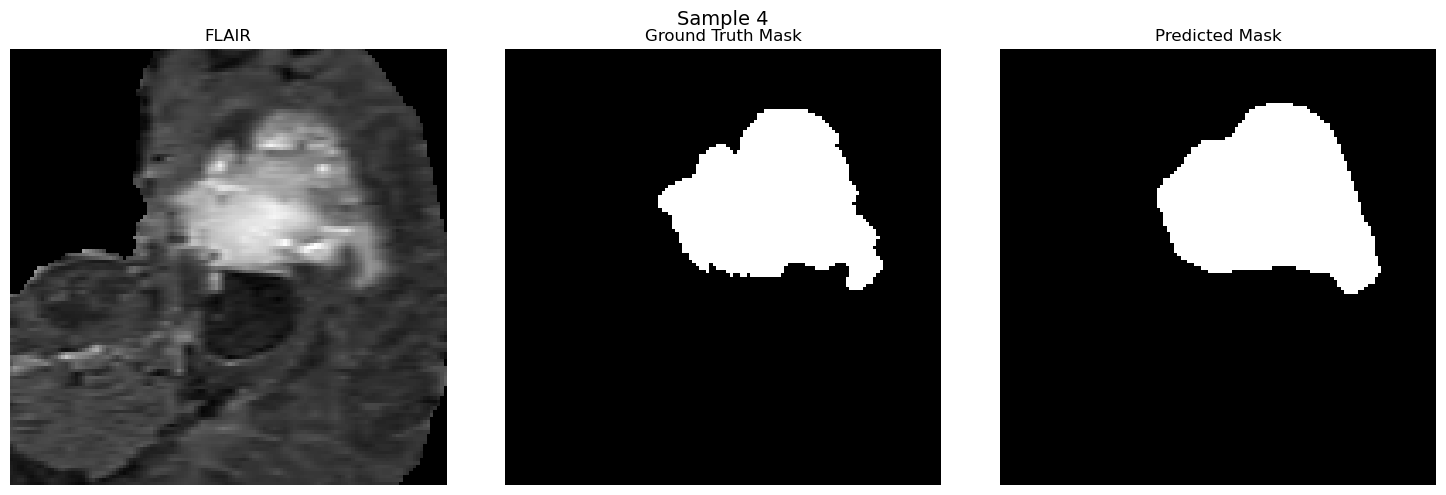

  5%|███▉                                                                              | 5/105 [00:01<00:35,  2.82it/s]

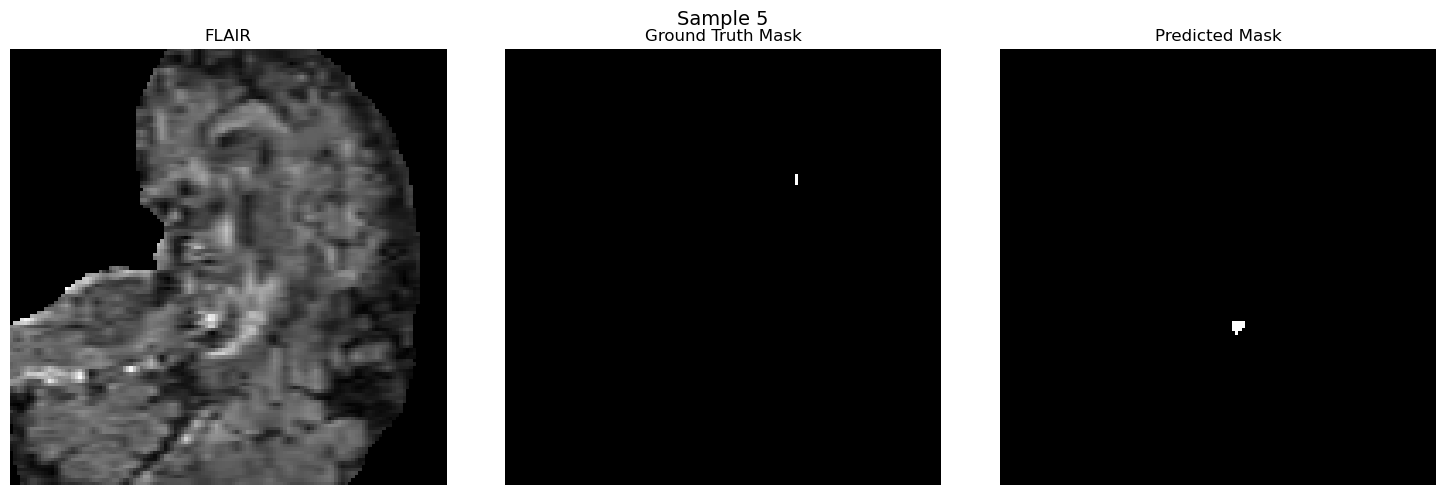

  6%|████▋                                                                             | 6/105 [00:02<00:35,  2.77it/s]

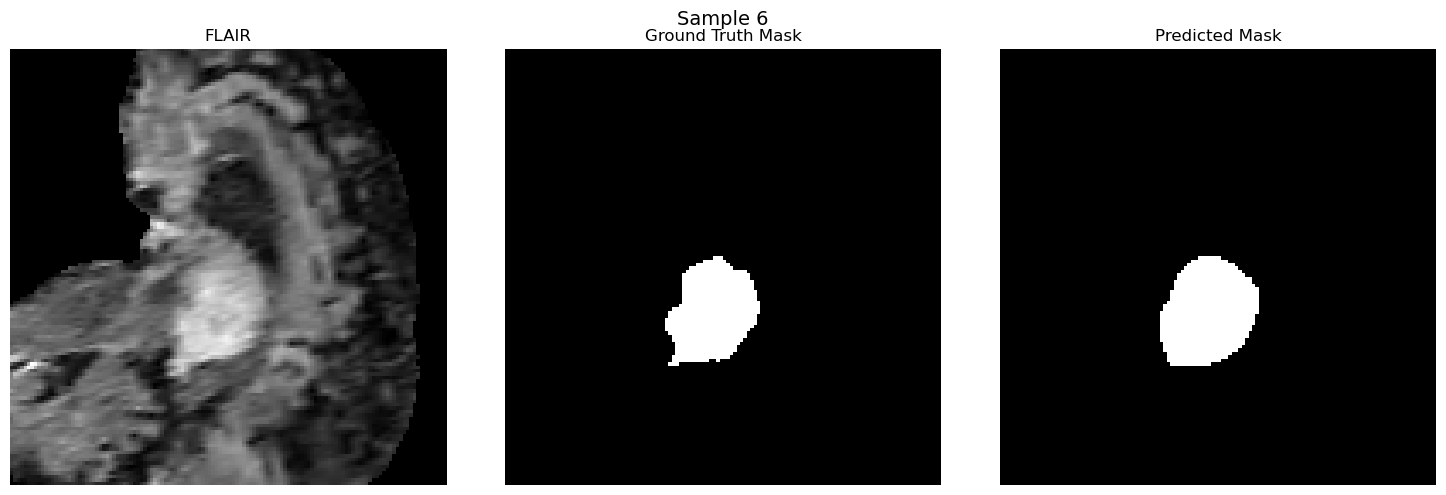

  7%|█████▍                                                                            | 7/105 [00:02<00:35,  2.75it/s]

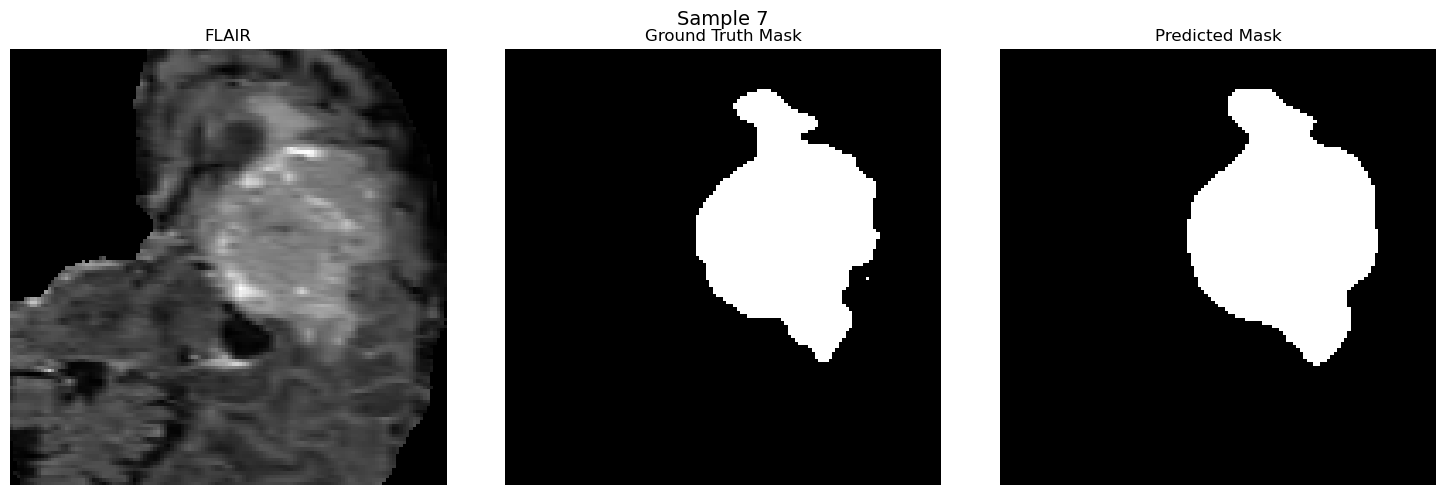

  8%|██████▏                                                                           | 8/105 [00:03<00:36,  2.69it/s]

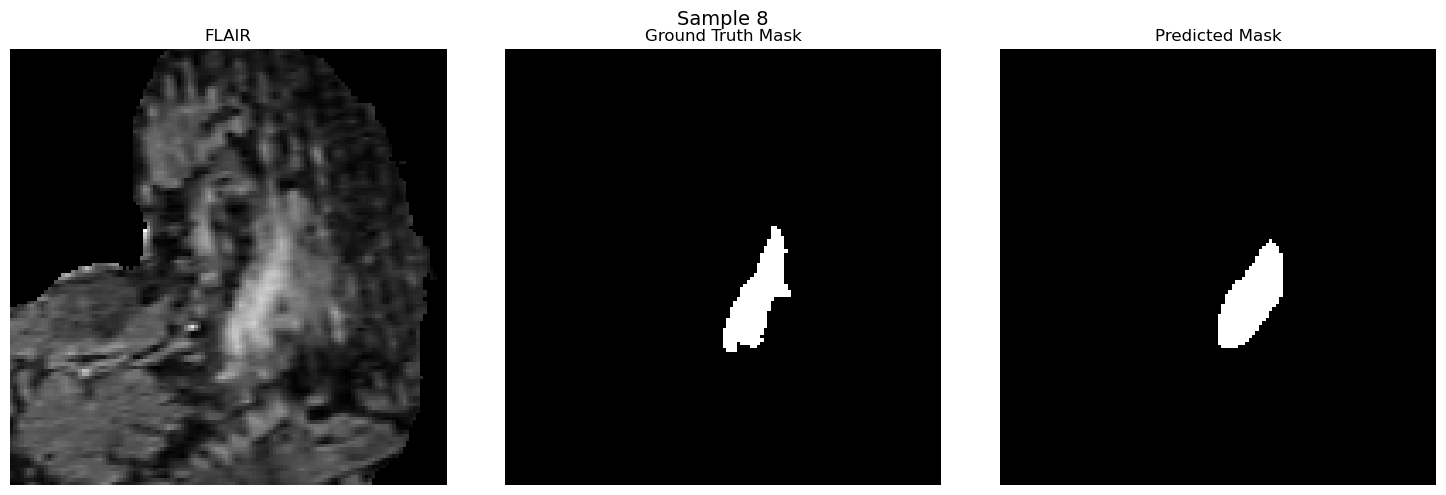

  9%|███████                                                                           | 9/105 [00:03<00:35,  2.68it/s]

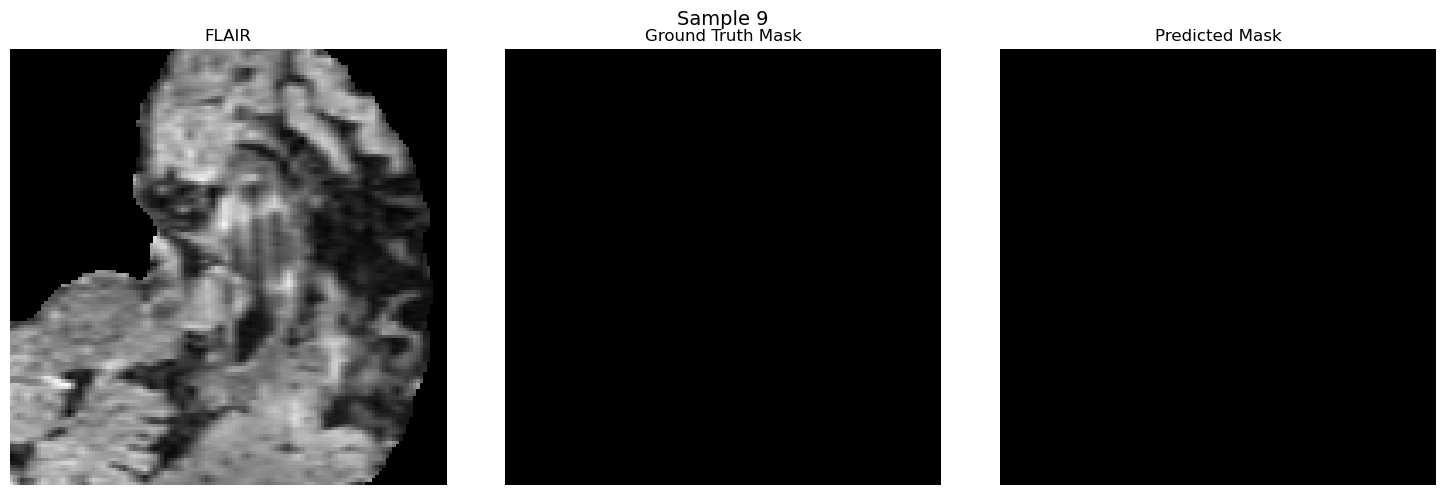

 10%|███████▋                                                                         | 10/105 [00:03<00:35,  2.67it/s]

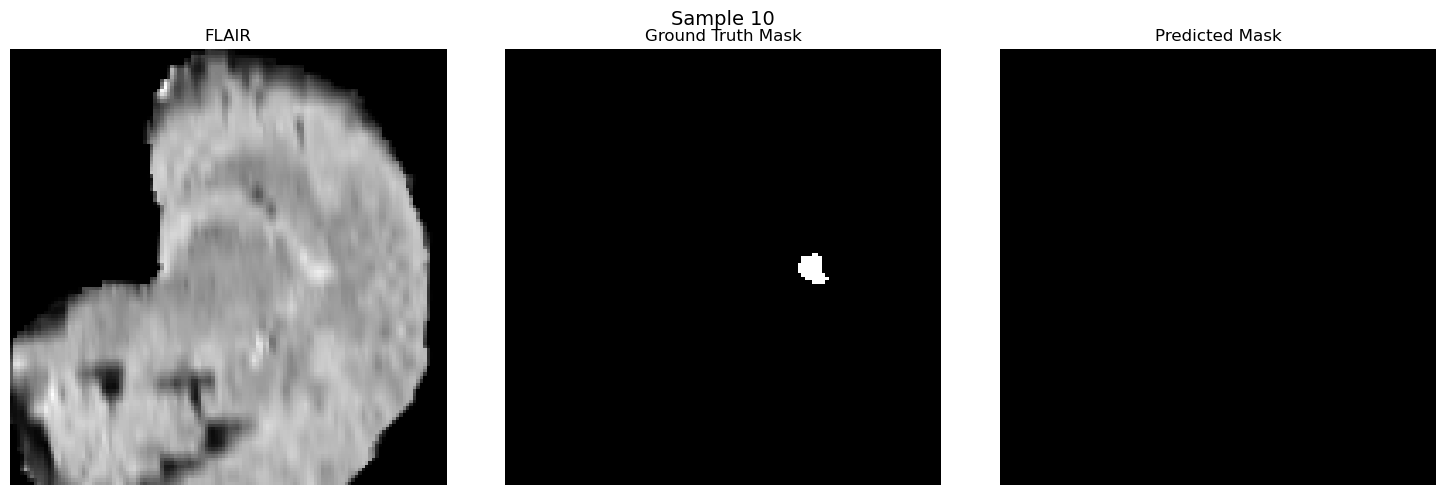

 10%|████████▍                                                                        | 11/105 [00:04<00:35,  2.66it/s]

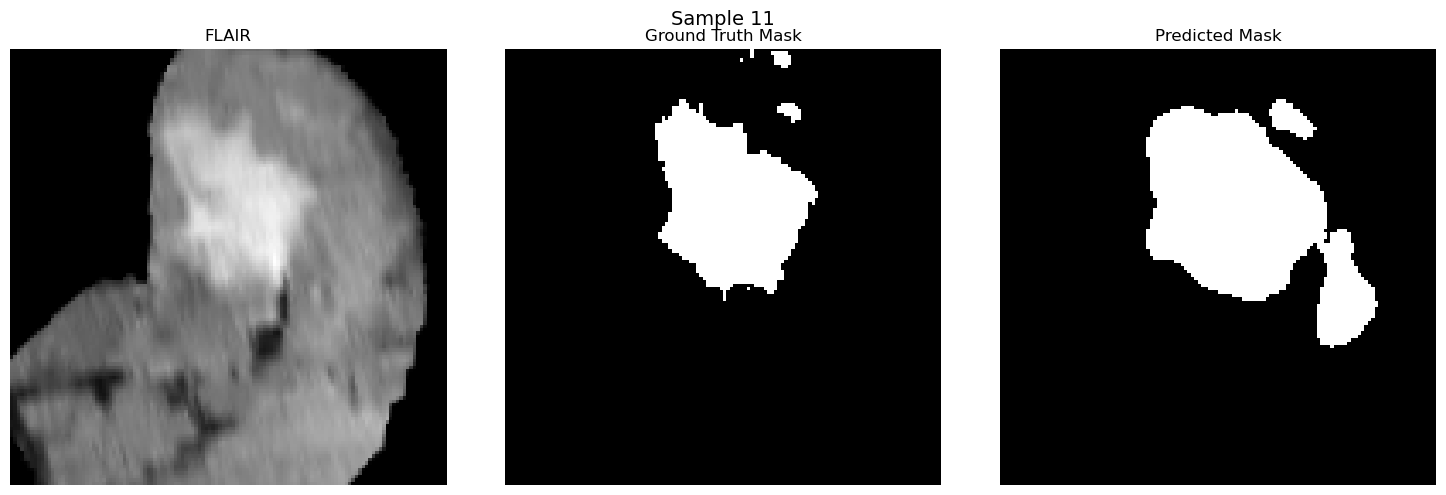

 11%|█████████▎                                                                       | 12/105 [00:04<00:34,  2.68it/s]

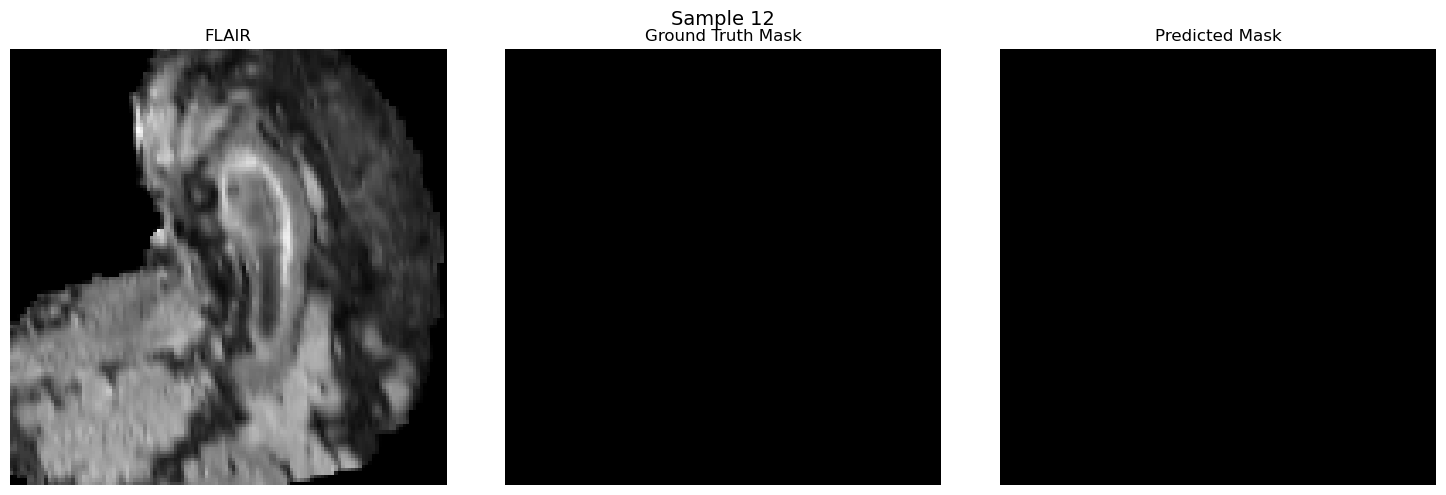

 12%|██████████                                                                       | 13/105 [00:05<00:34,  2.69it/s]

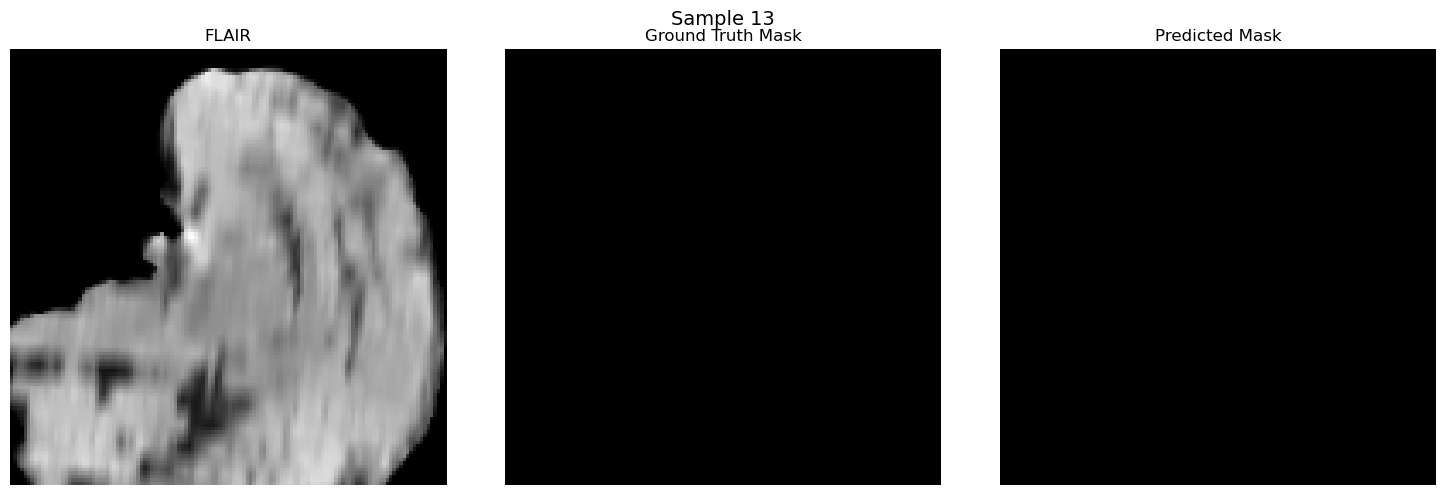

 13%|██████████▊                                                                      | 14/105 [00:05<00:41,  2.19it/s]

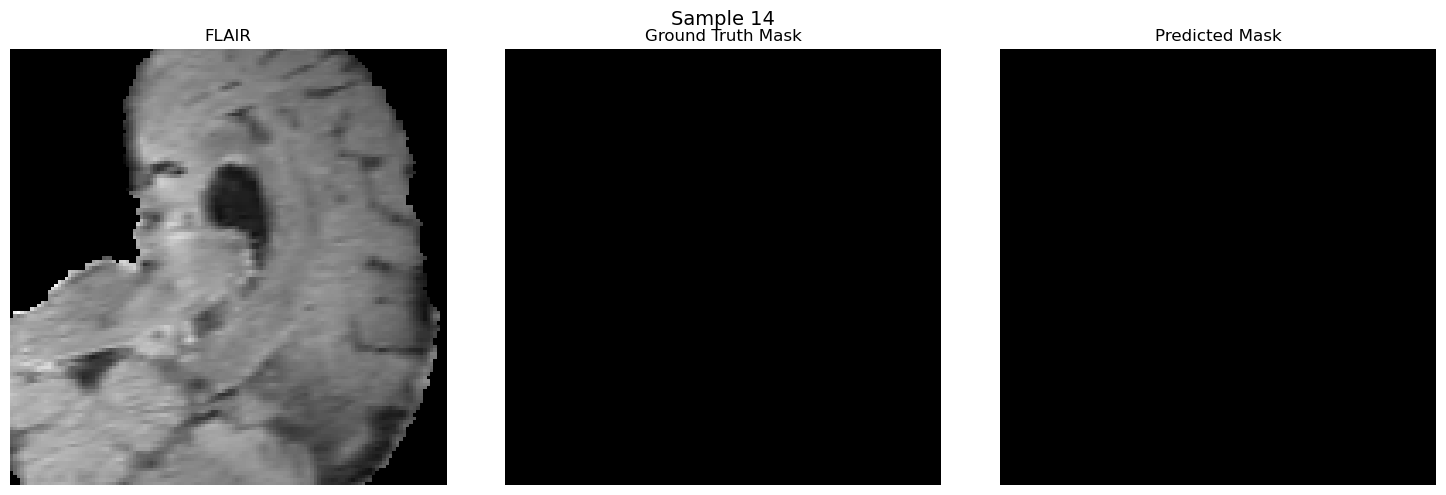

 14%|███████████▌                                                                     | 15/105 [00:06<00:39,  2.29it/s]

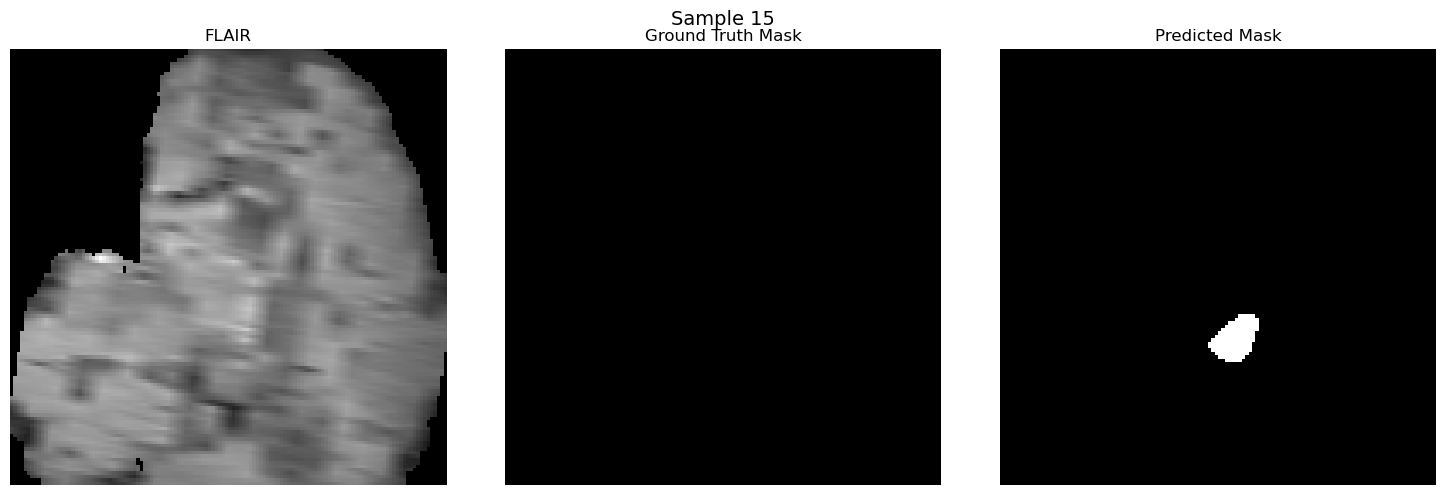

 15%|████████████▎                                                                    | 16/105 [00:06<00:37,  2.37it/s]

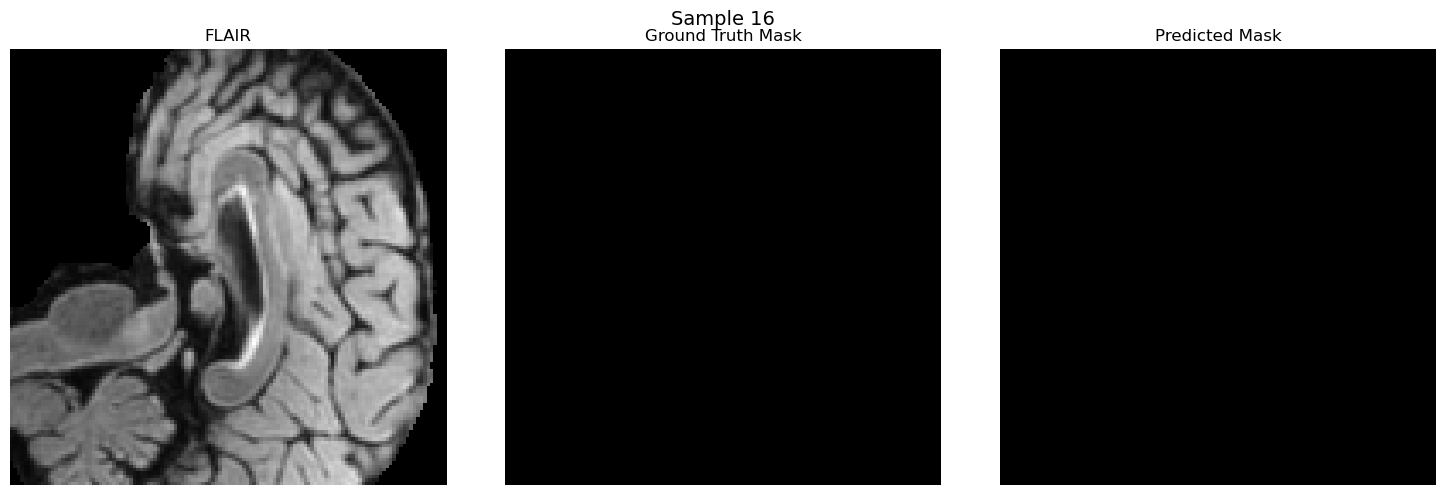

 16%|█████████████                                                                    | 17/105 [00:06<00:36,  2.39it/s]

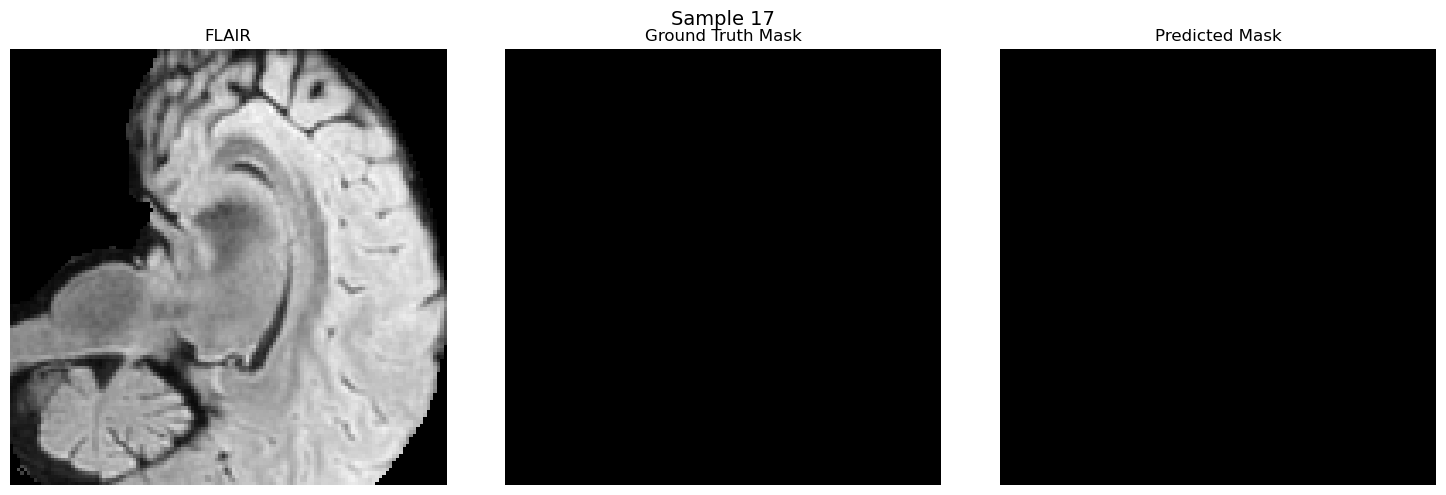

 17%|█████████████▉                                                                   | 18/105 [00:07<00:33,  2.57it/s]

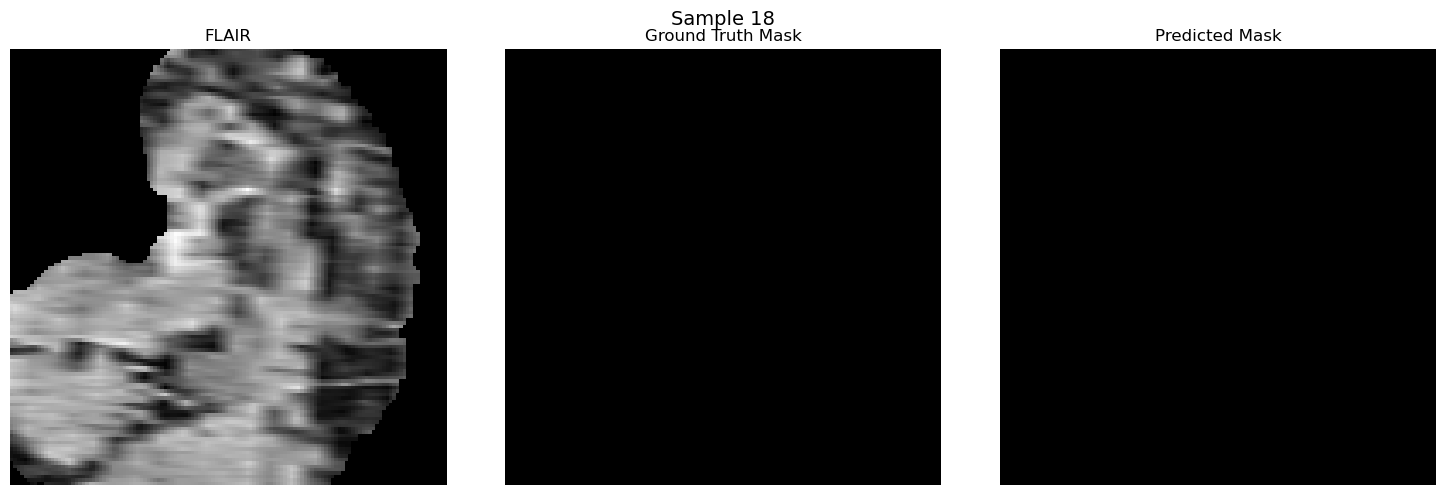

 18%|██████████████▋                                                                  | 19/105 [00:07<00:33,  2.57it/s]

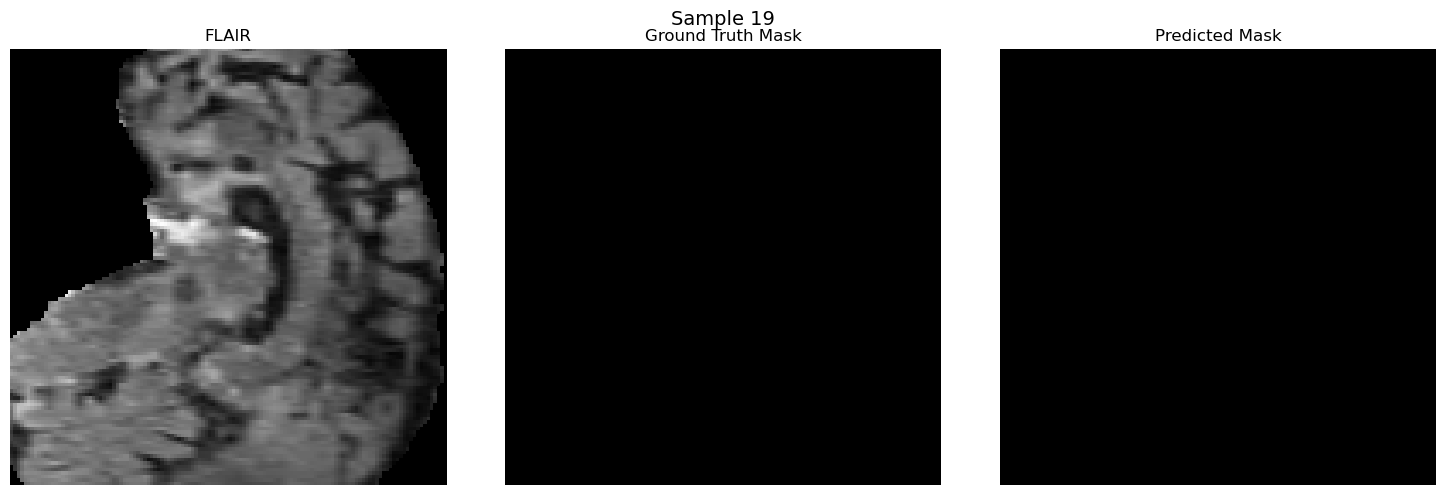

 19%|███████████████▍                                                                 | 20/105 [00:07<00:33,  2.56it/s]

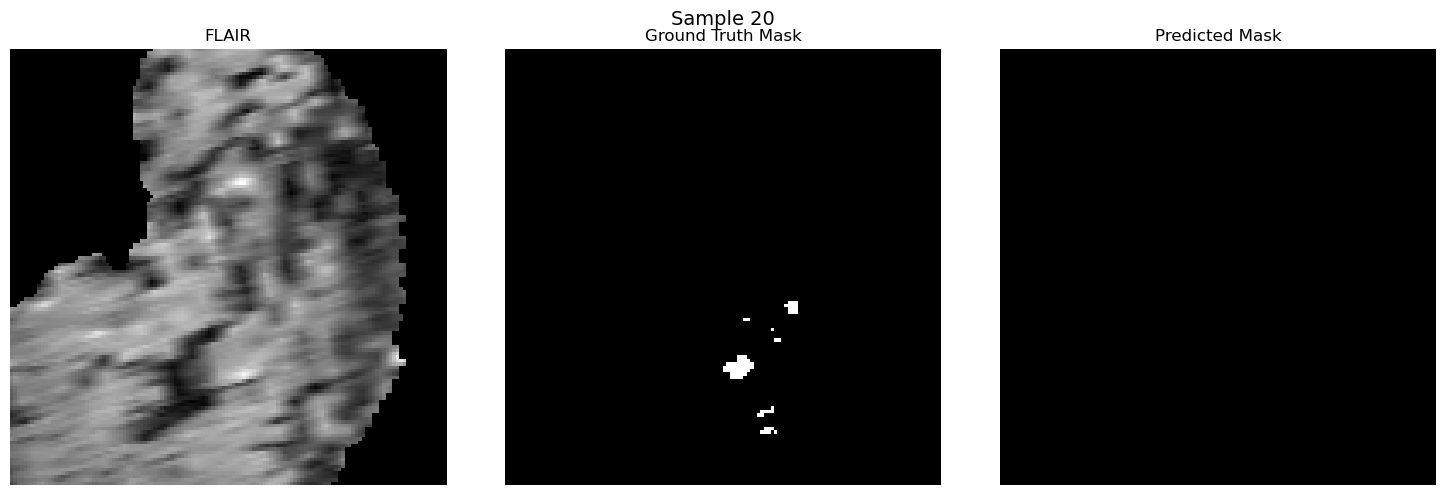

 20%|████████████████▏                                                                | 21/105 [00:08<00:30,  2.72it/s]

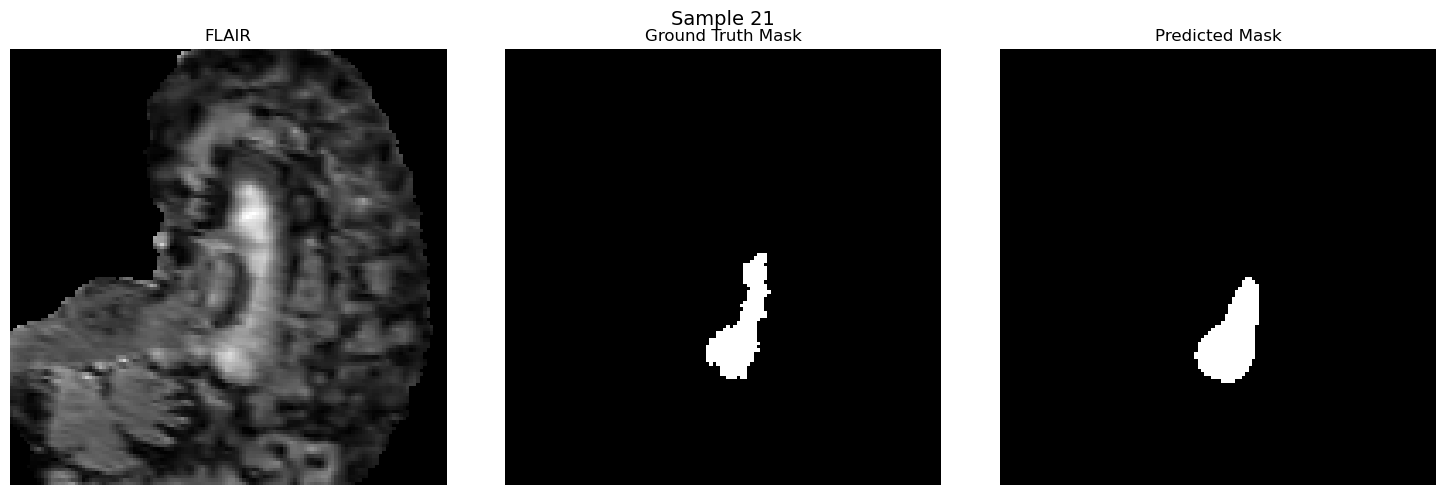

 21%|████████████████▉                                                                | 22/105 [00:08<00:30,  2.69it/s]

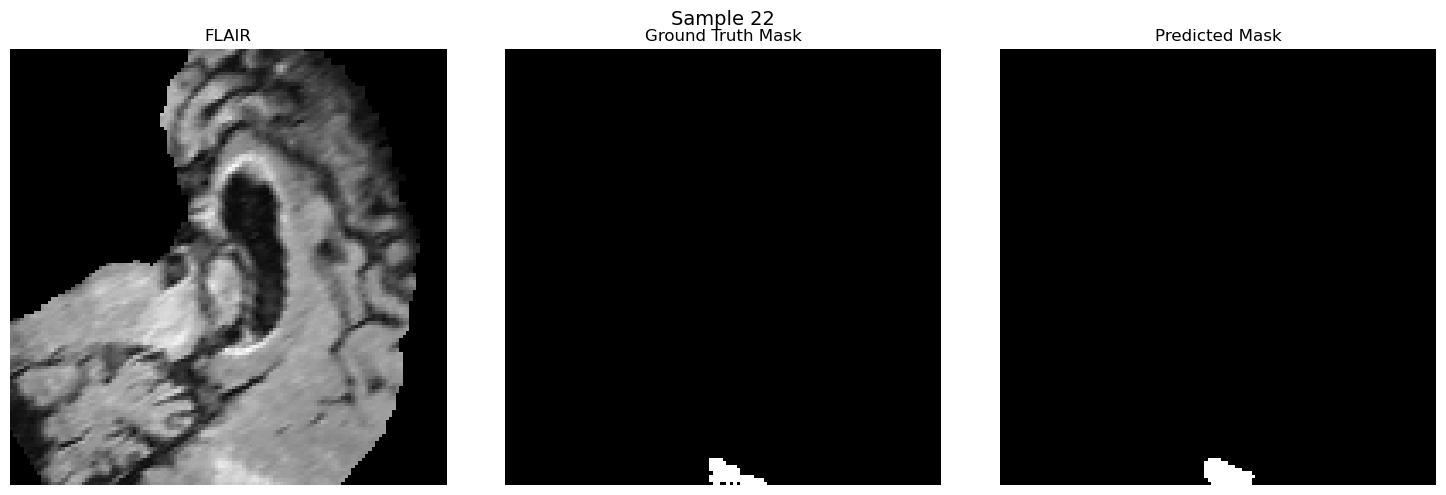

 22%|█████████████████▋                                                               | 23/105 [00:08<00:29,  2.82it/s]

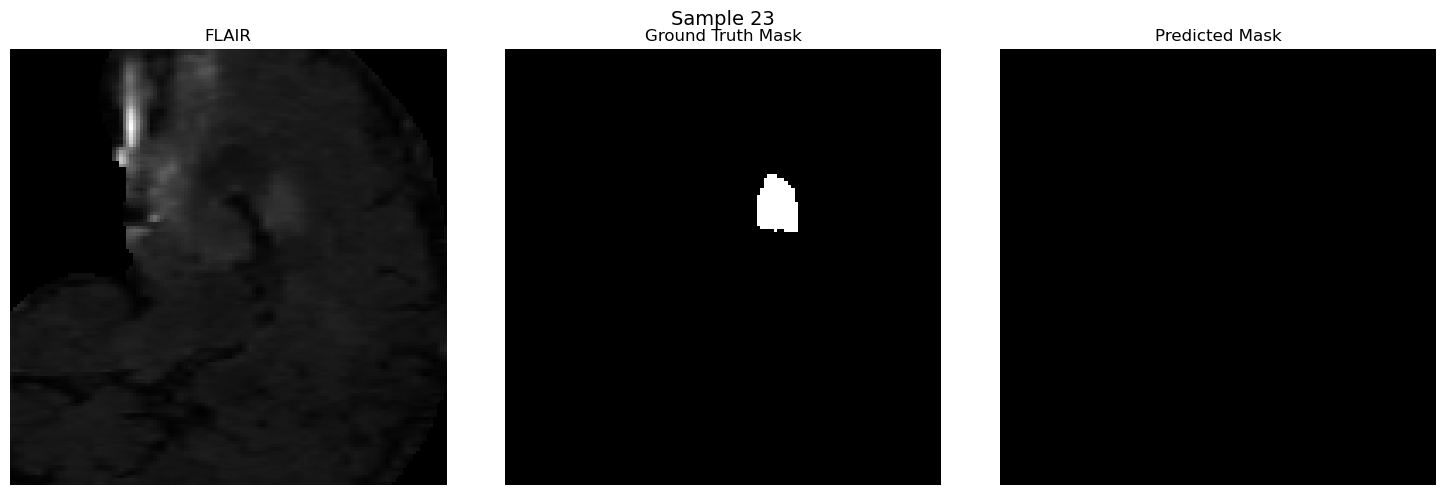

 23%|██████████████████▌                                                              | 24/105 [00:09<00:29,  2.77it/s]

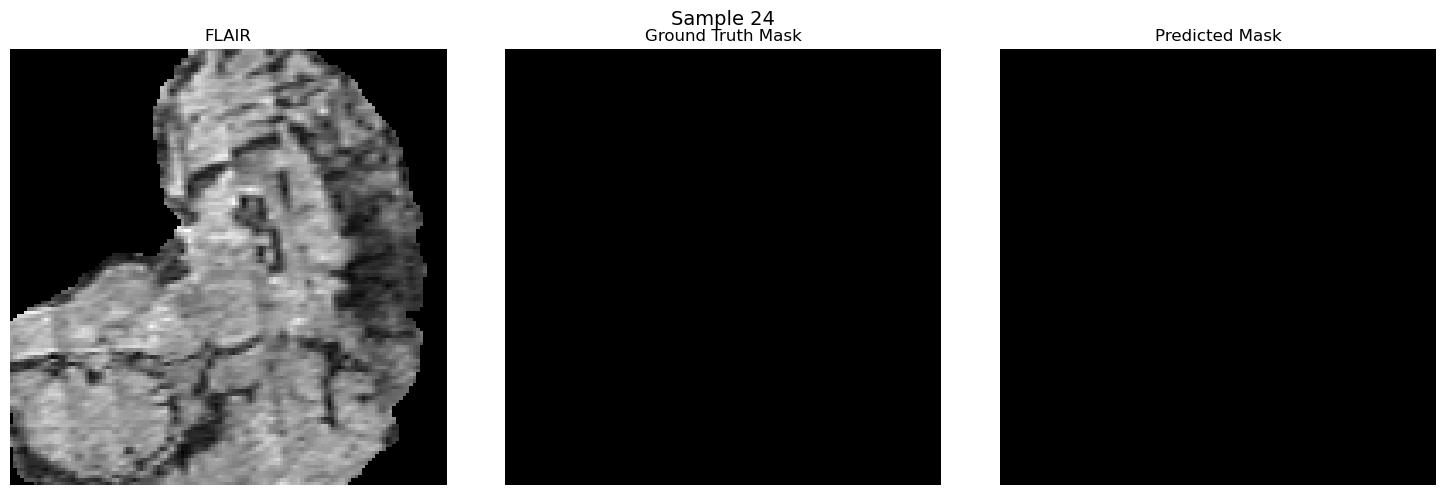

 24%|███████████████████▎                                                             | 25/105 [00:09<00:29,  2.69it/s]

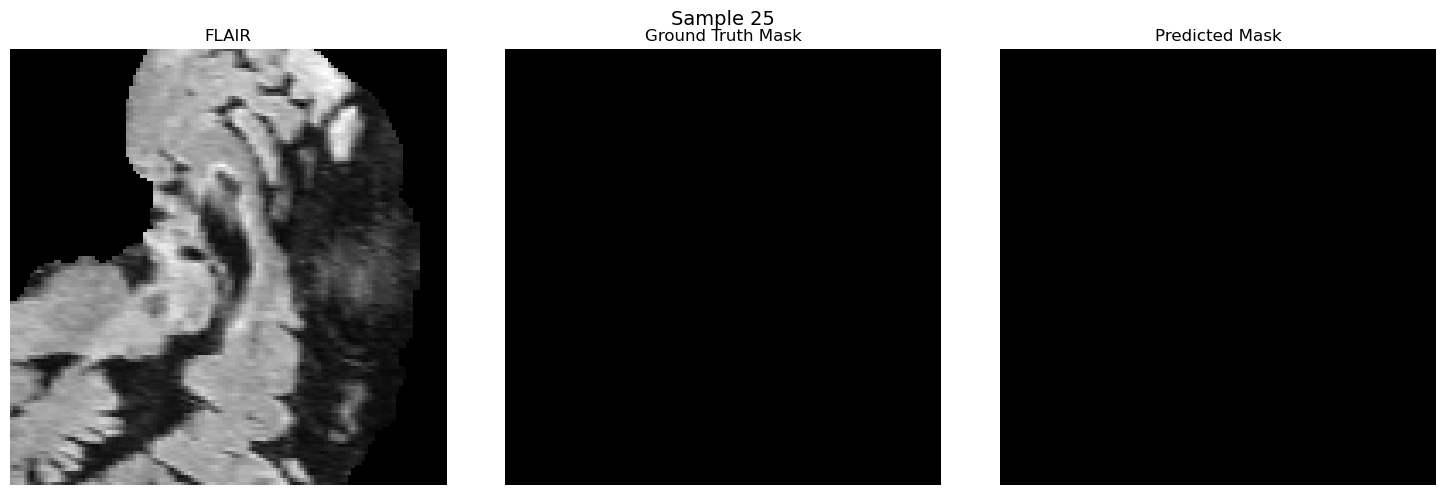

 25%|████████████████████                                                             | 26/105 [00:10<00:30,  2.61it/s]

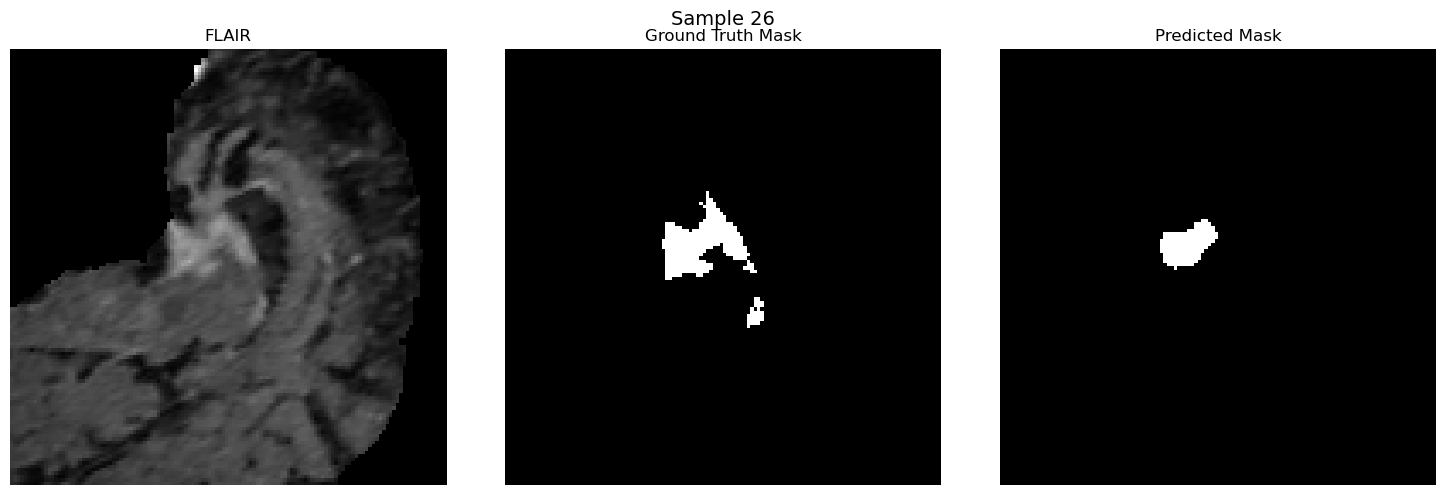

 26%|████████████████████▊                                                            | 27/105 [00:10<00:30,  2.60it/s]

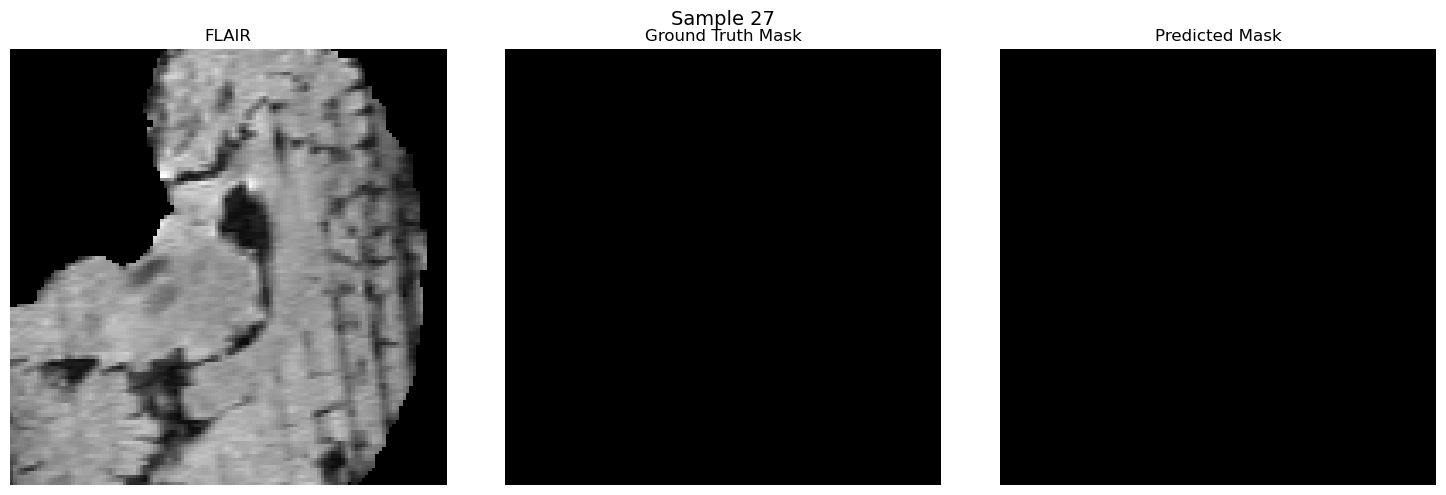

 27%|█████████████████████▌                                                           | 28/105 [00:10<00:29,  2.61it/s]

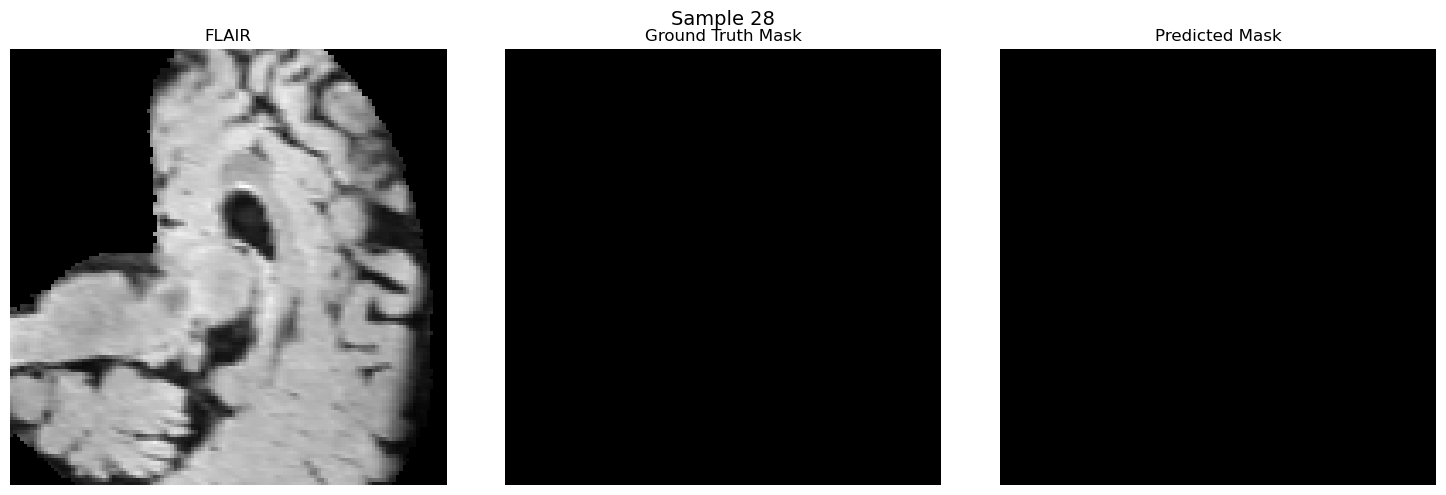

 28%|██████████████████████▎                                                          | 29/105 [00:11<00:29,  2.58it/s]

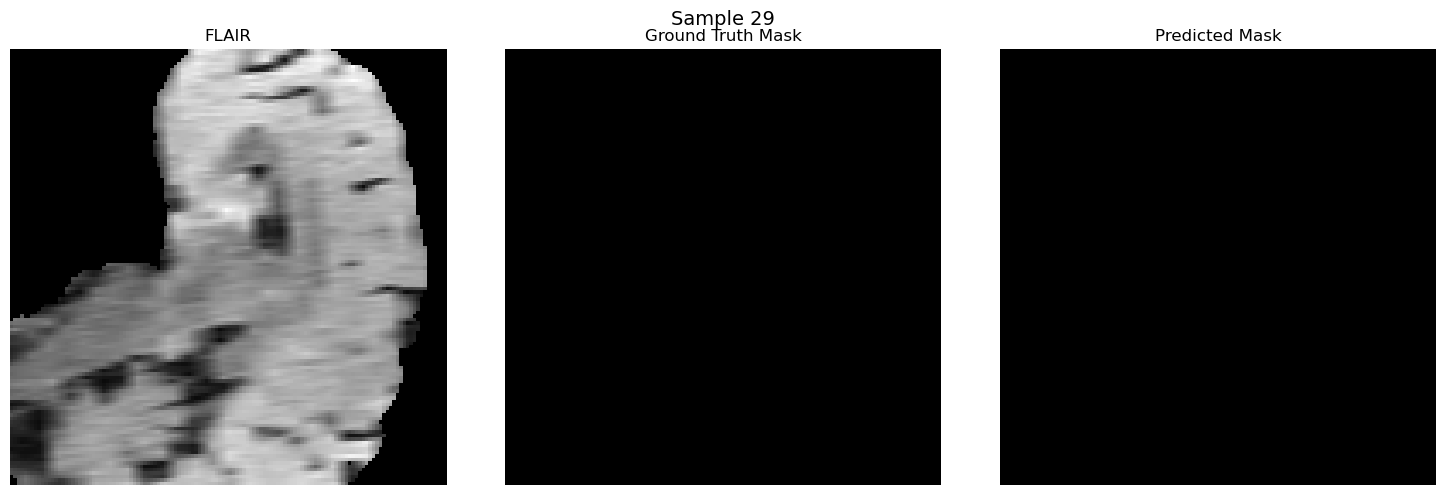

 29%|███████████████████████▏                                                         | 30/105 [00:11<00:28,  2.66it/s]

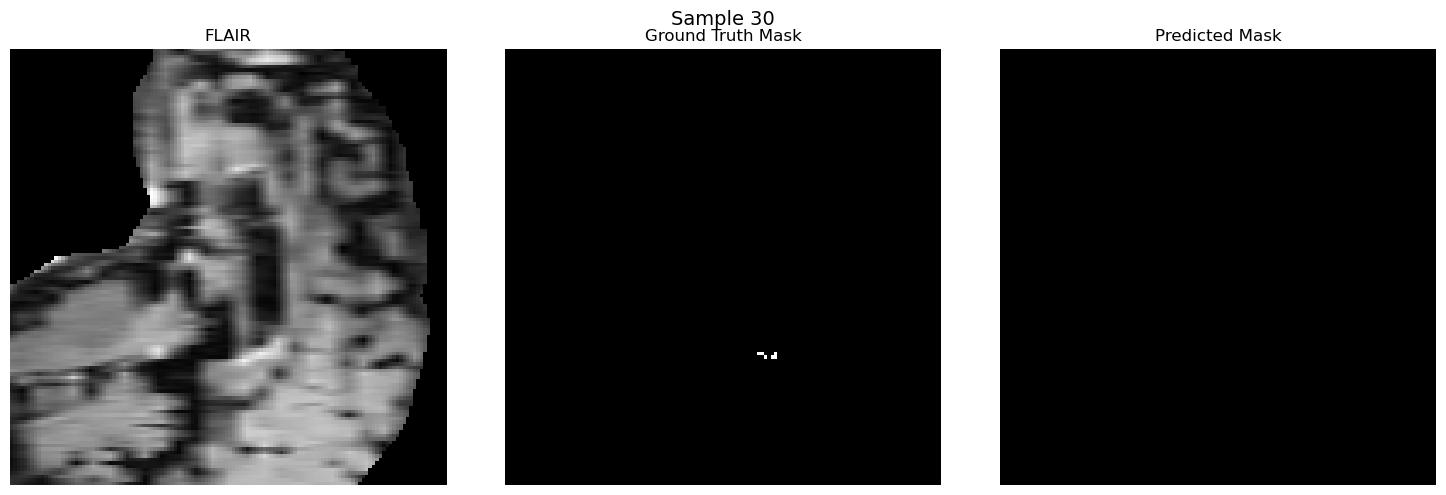

 30%|███████████████████████▉                                                         | 31/105 [00:12<00:33,  2.20it/s]

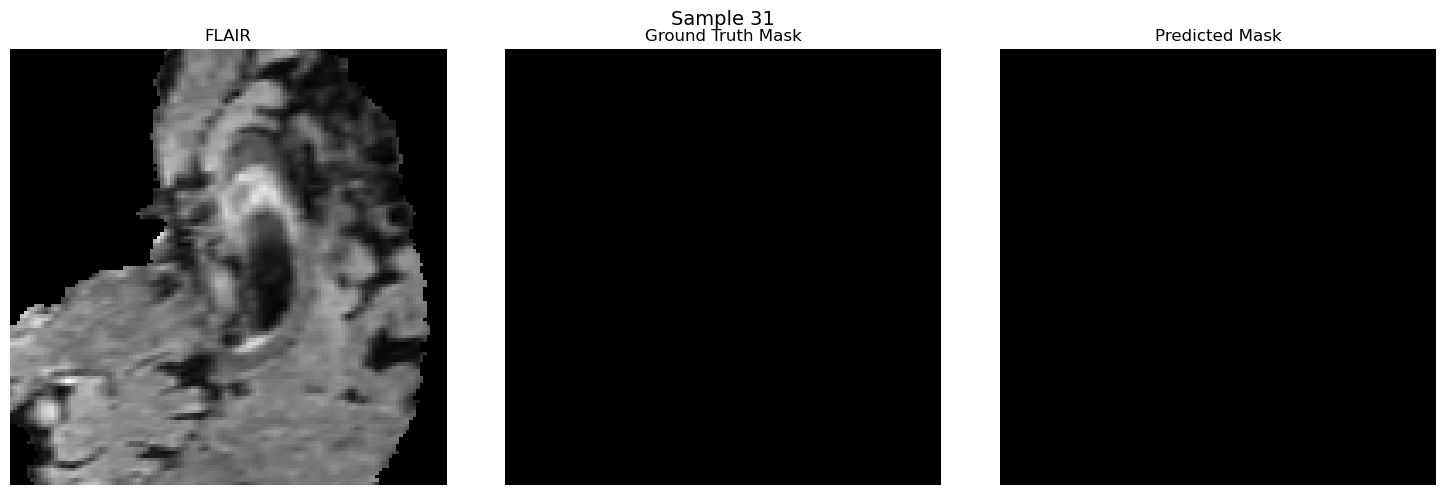

 30%|████████████████████████▋                                                        | 32/105 [00:12<00:31,  2.30it/s]

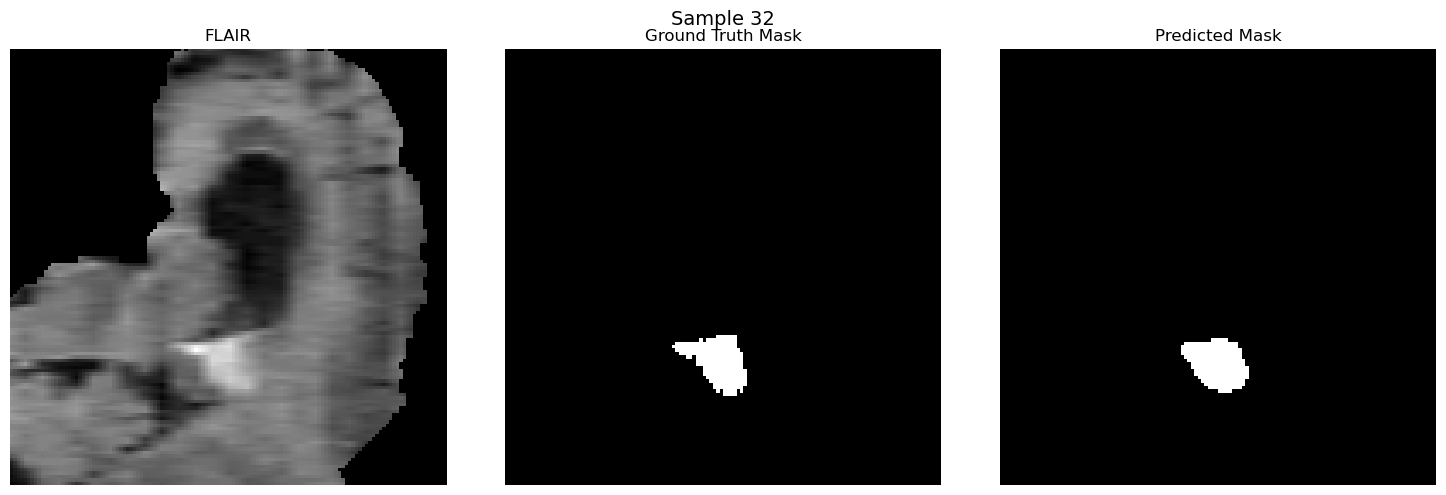

 31%|█████████████████████████▍                                                       | 33/105 [00:13<00:30,  2.36it/s]

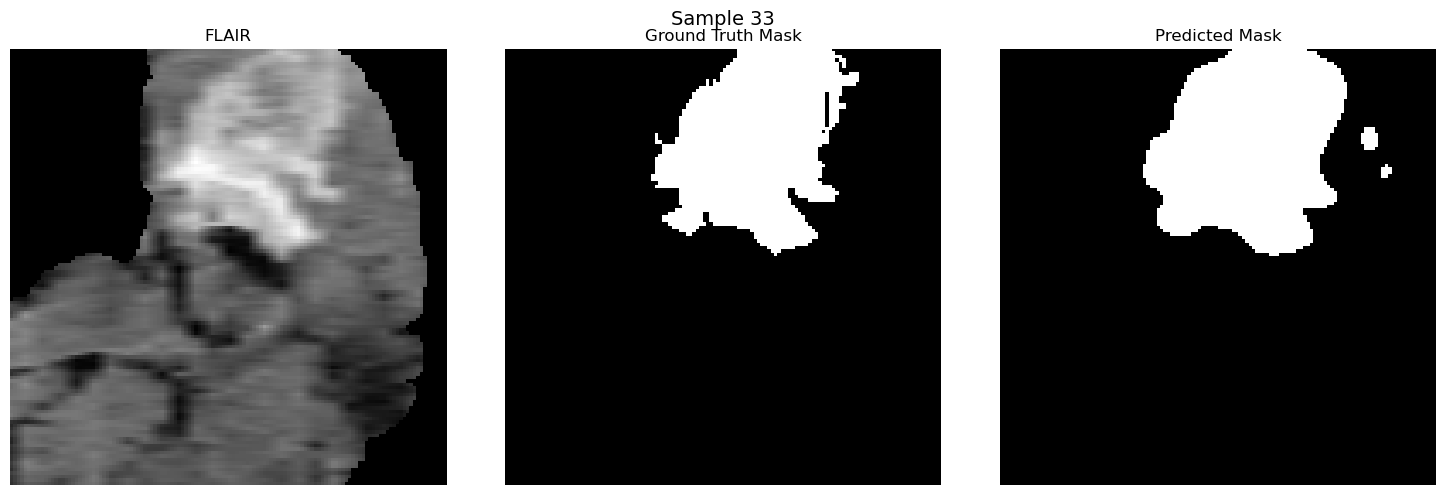

 32%|██████████████████████████▏                                                      | 34/105 [00:13<00:28,  2.49it/s]

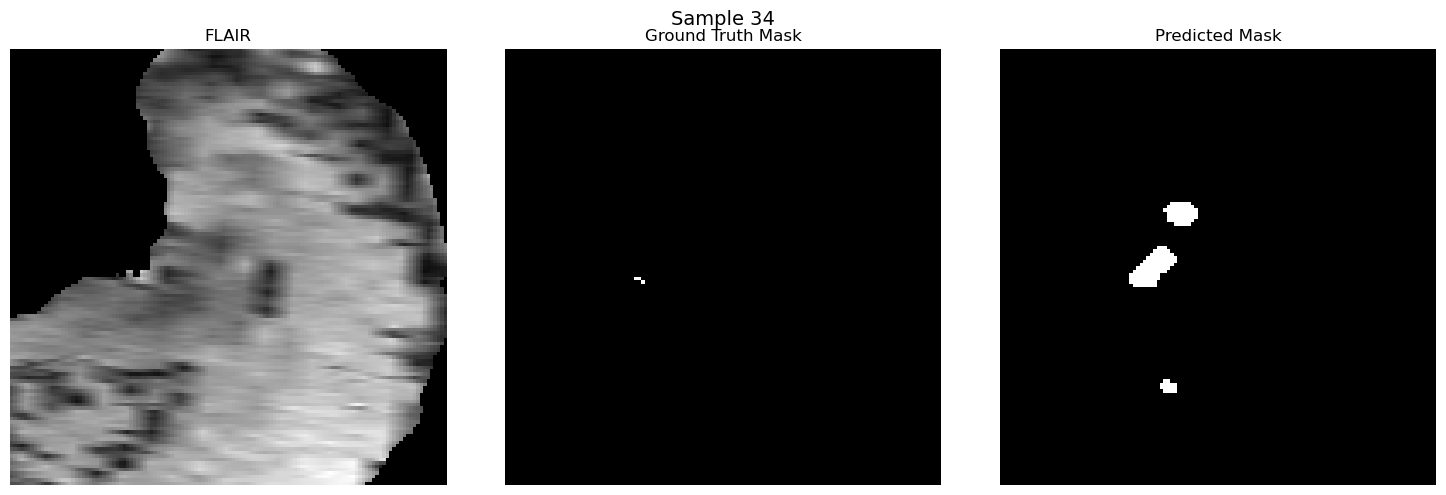

 33%|███████████████████████████                                                      | 35/105 [00:13<00:27,  2.56it/s]

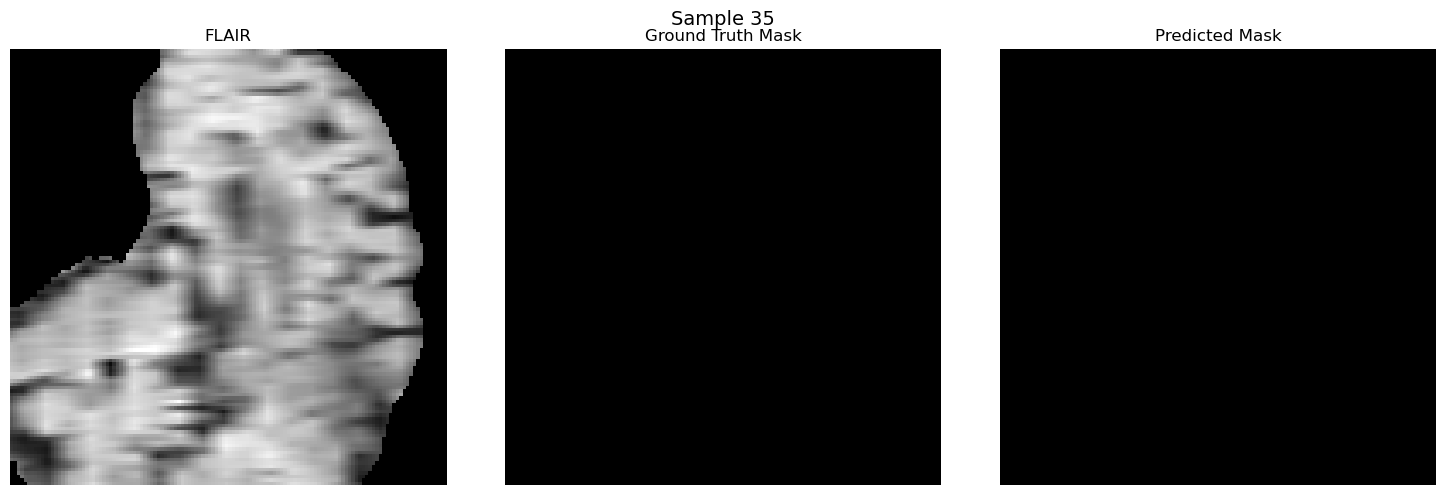

 34%|███████████████████████████▊                                                     | 36/105 [00:14<00:26,  2.61it/s]

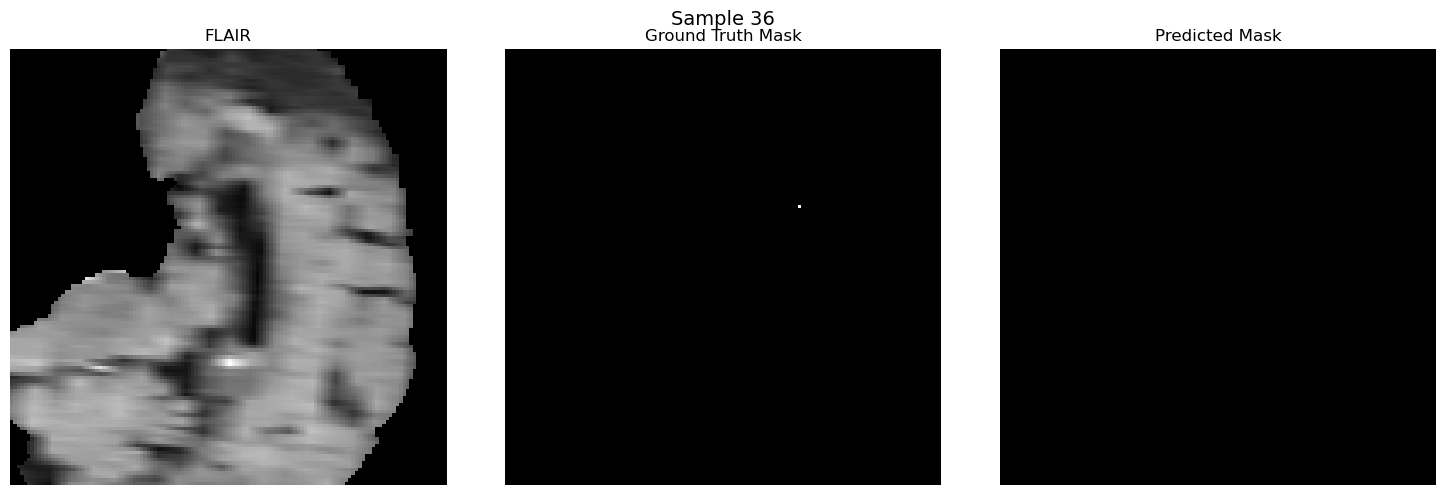

 35%|████████████████████████████▌                                                    | 37/105 [00:14<00:26,  2.59it/s]

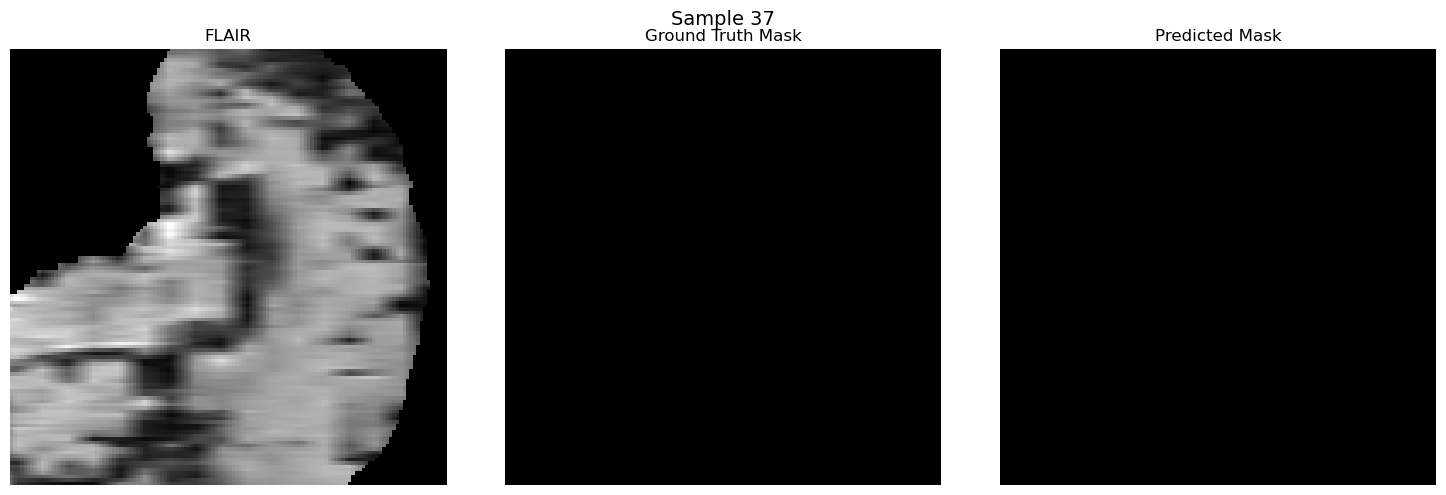

 36%|█████████████████████████████▎                                                   | 38/105 [00:14<00:25,  2.61it/s]

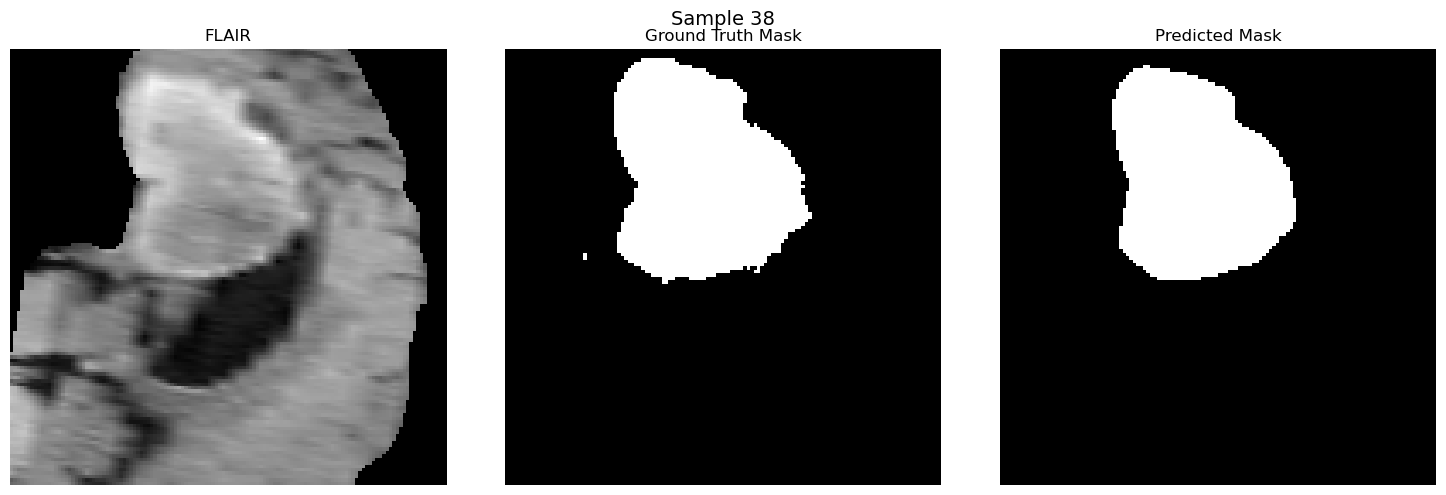

 37%|██████████████████████████████                                                   | 39/105 [00:15<00:25,  2.59it/s]

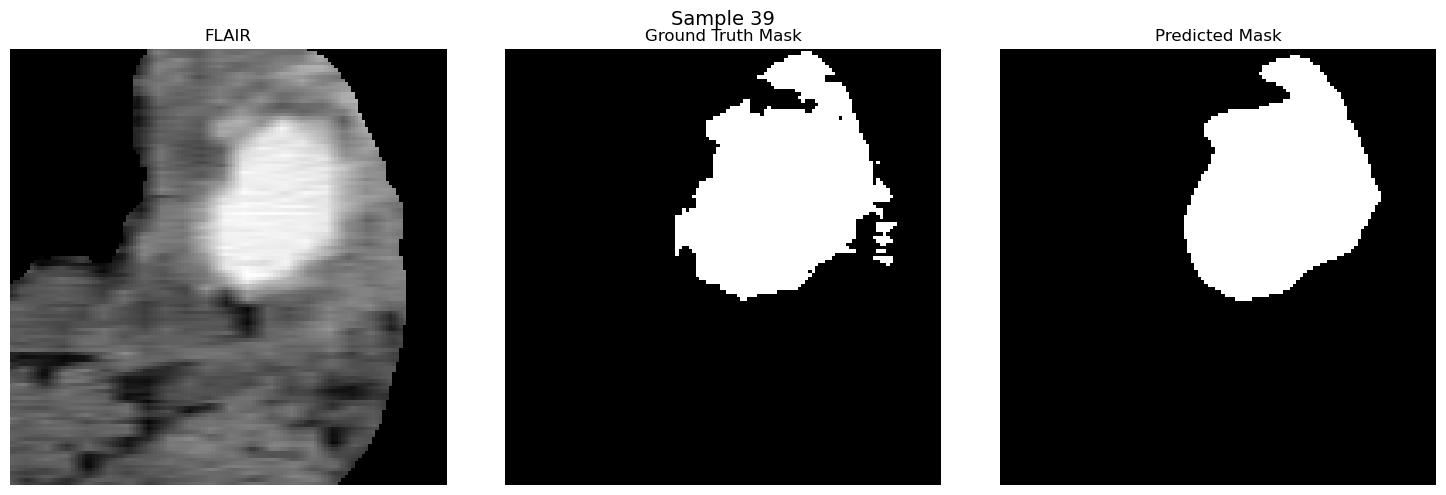

 38%|██████████████████████████████▊                                                  | 40/105 [00:15<00:24,  2.67it/s]

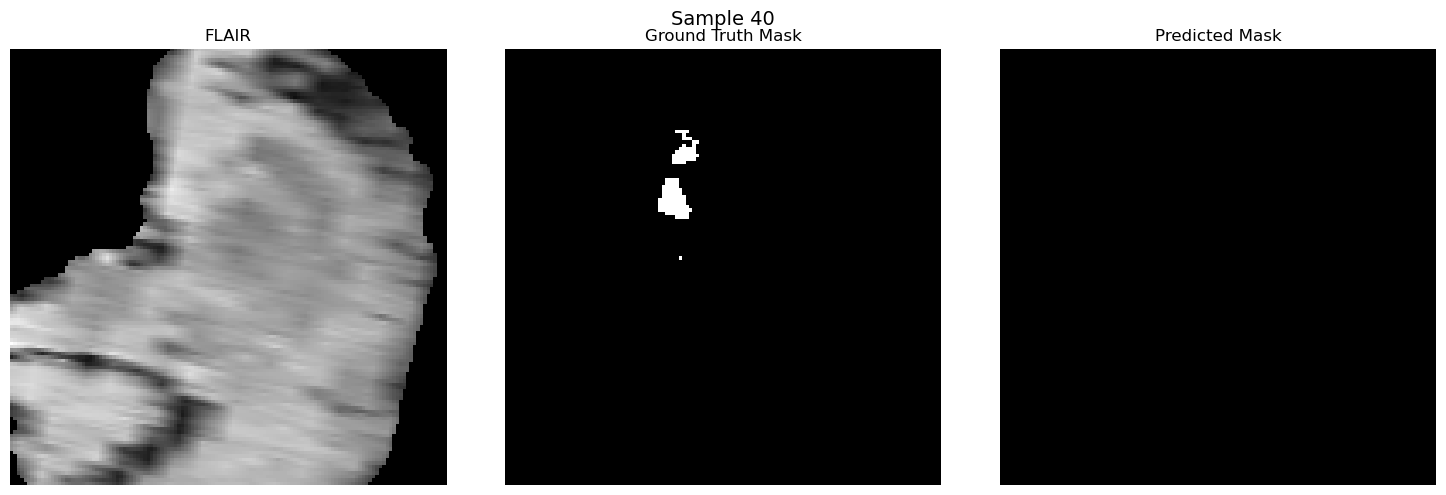

 39%|███████████████████████████████▋                                                 | 41/105 [00:16<00:23,  2.71it/s]

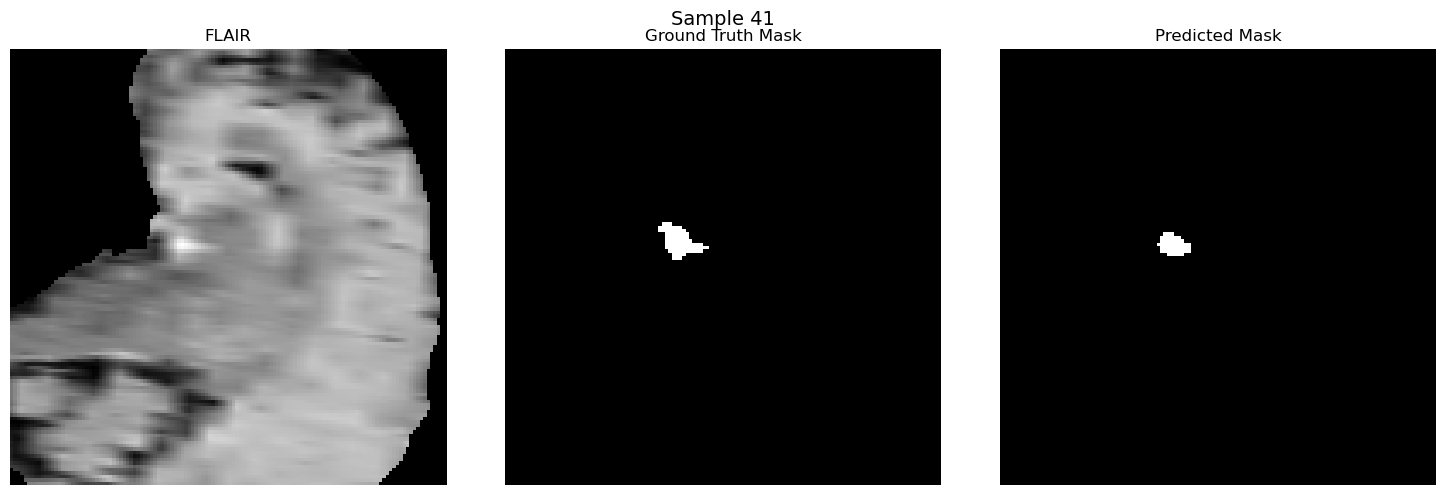

 40%|████████████████████████████████▍                                                | 42/105 [00:16<00:23,  2.71it/s]

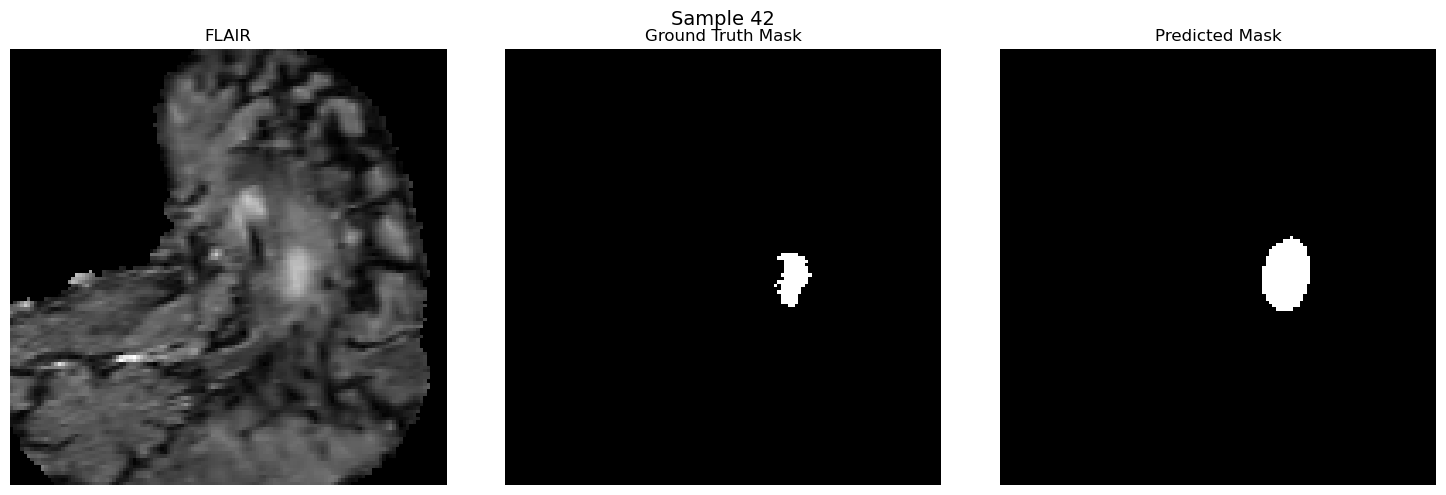

 41%|█████████████████████████████████▏                                               | 43/105 [00:16<00:23,  2.65it/s]

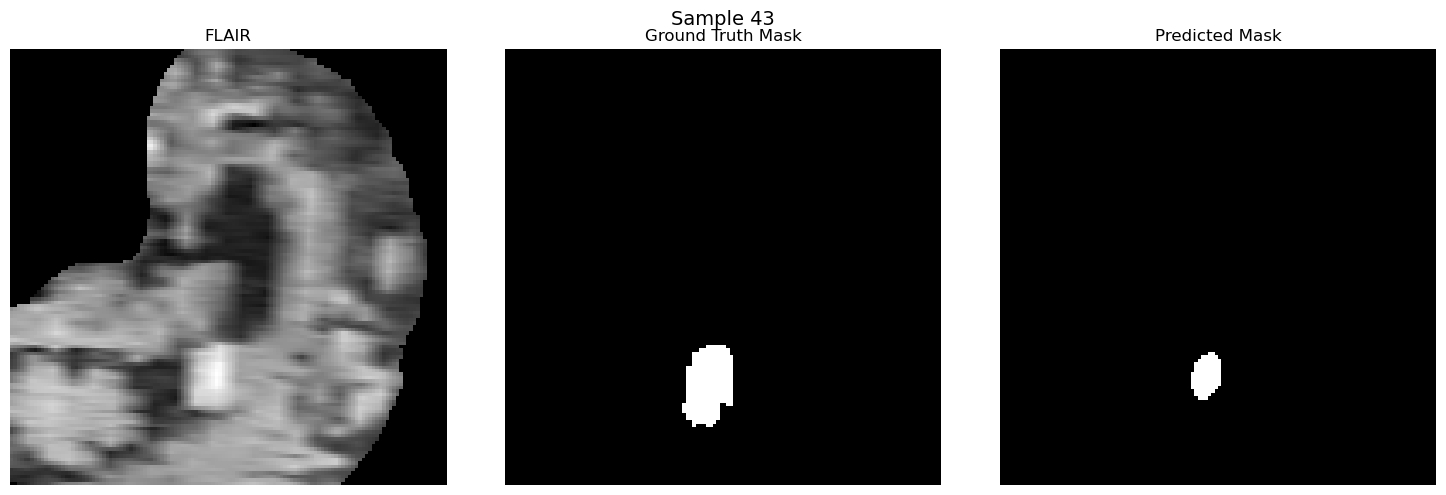

 42%|█████████████████████████████████▉                                               | 44/105 [00:17<00:21,  2.78it/s]

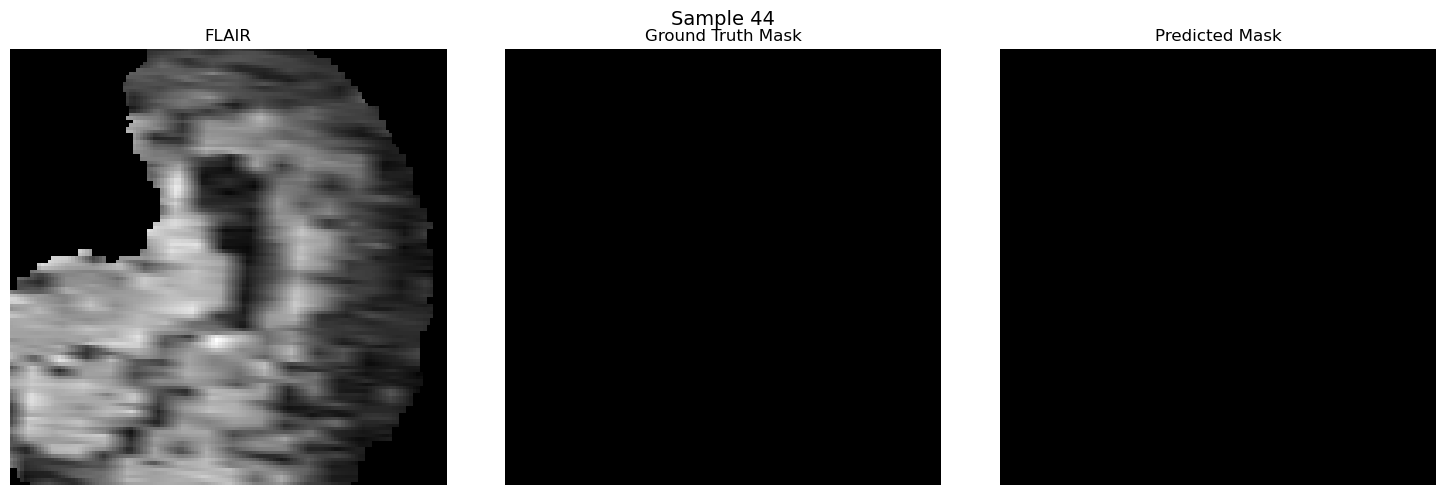

 43%|██████████████████████████████████▋                                              | 45/105 [00:17<00:21,  2.77it/s]

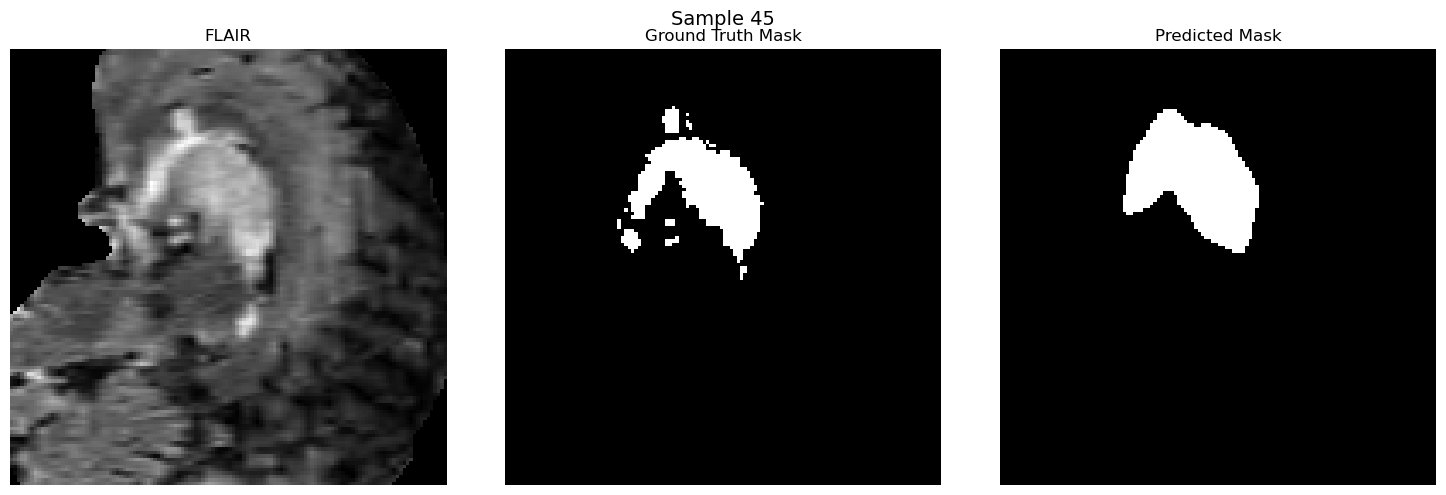

 44%|███████████████████████████████████▍                                             | 46/105 [00:17<00:21,  2.69it/s]

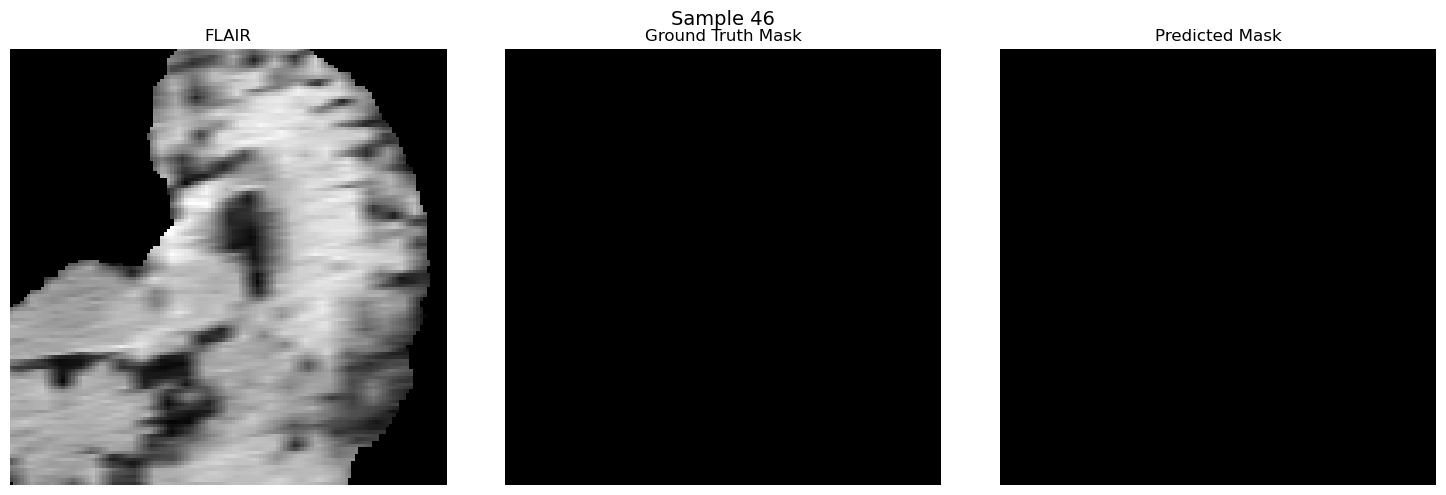

 45%|████████████████████████████████████▎                                            | 47/105 [00:18<00:20,  2.77it/s]

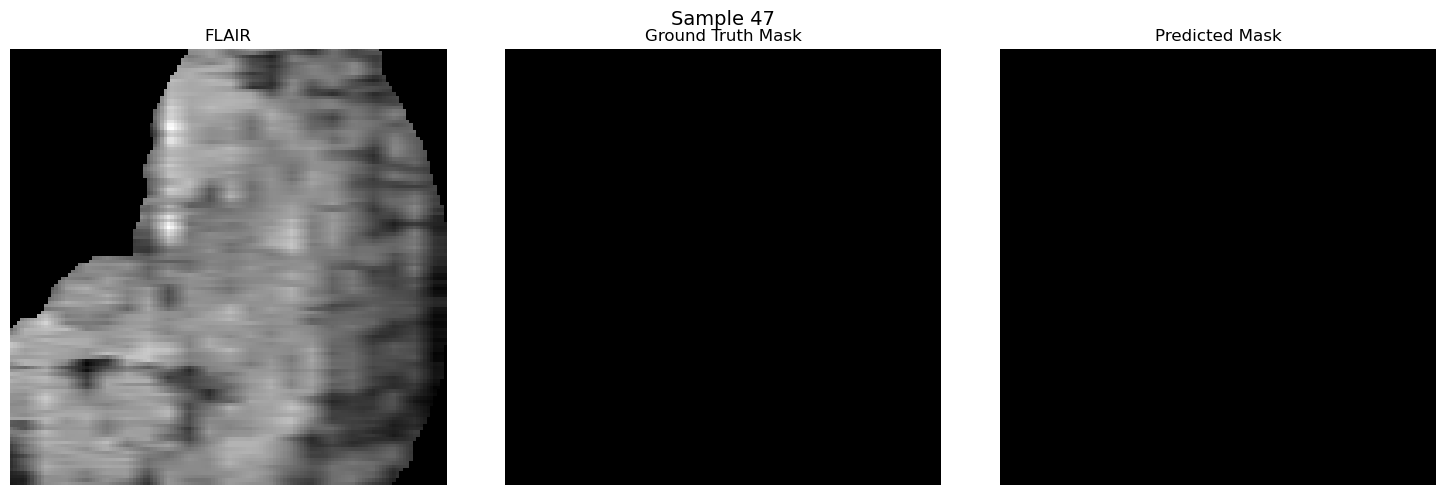

 46%|█████████████████████████████████████                                            | 48/105 [00:18<00:20,  2.81it/s]

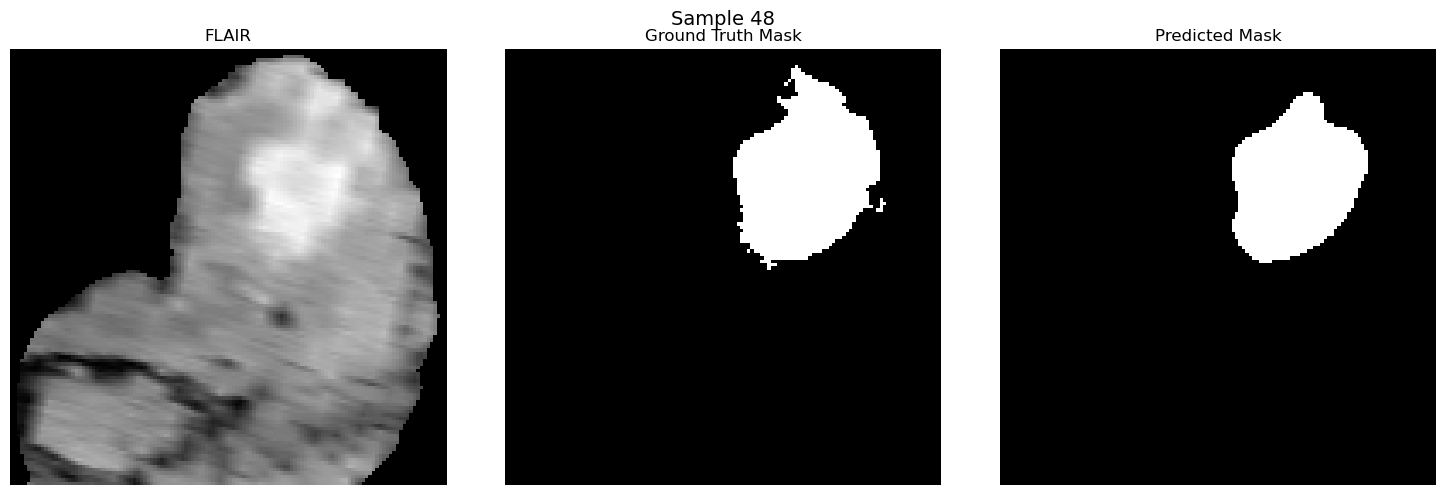

 47%|█████████████████████████████████████▊                                           | 49/105 [00:18<00:19,  2.85it/s]

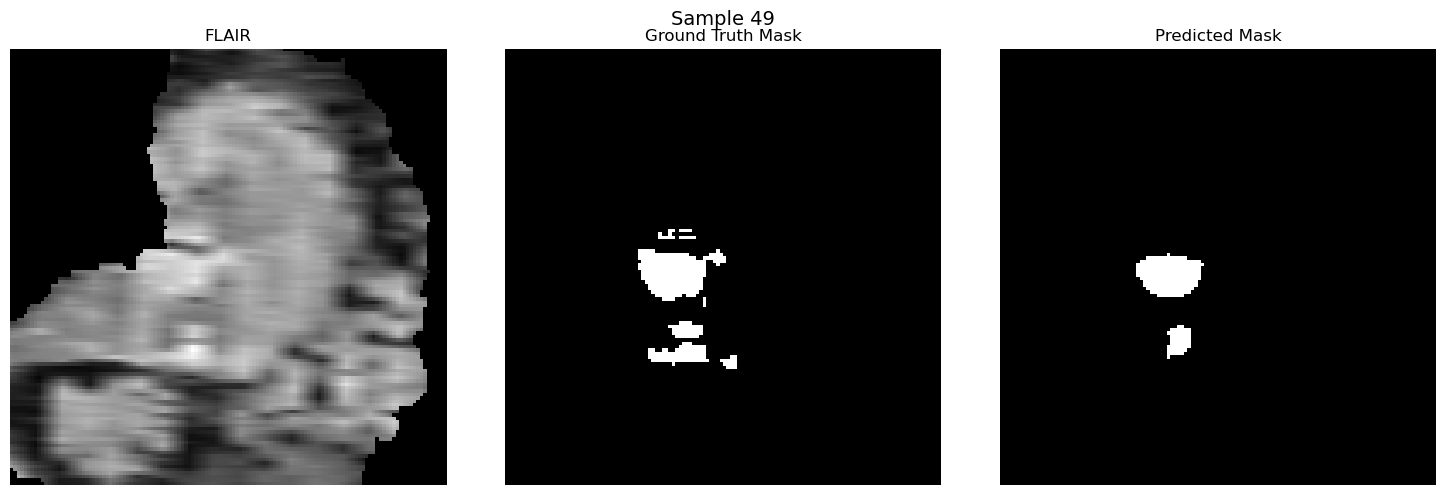

 48%|██████████████████████████████████████▌                                          | 50/105 [00:19<00:23,  2.30it/s]

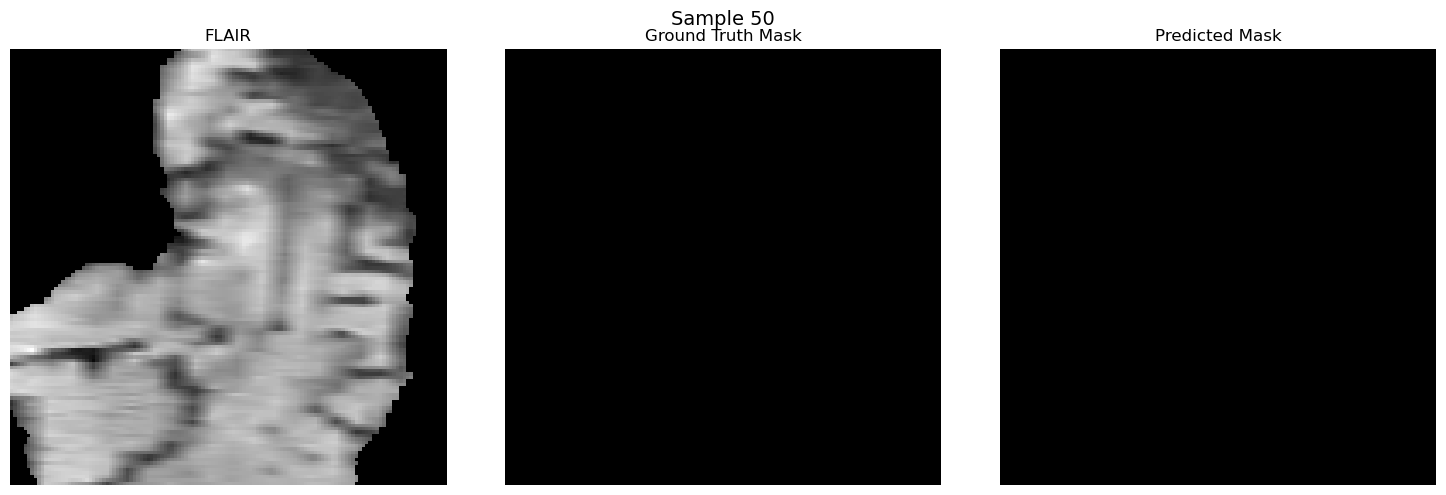

 49%|███████████████████████████████████████▎                                         | 51/105 [00:19<00:23,  2.35it/s]

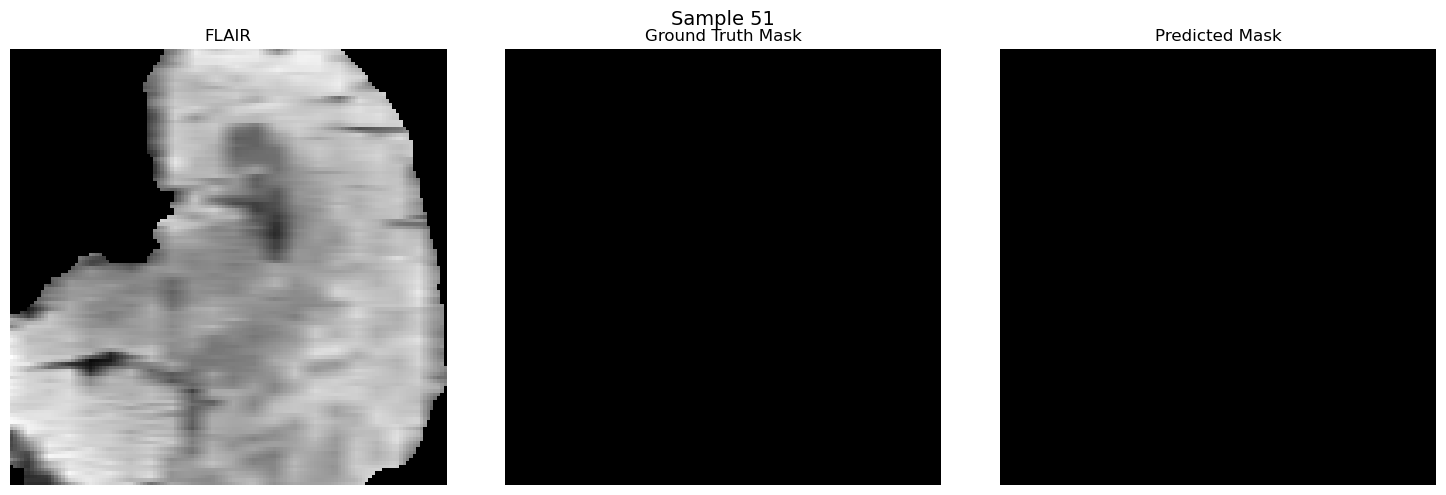

 50%|████████████████████████████████████████                                         | 52/105 [00:20<00:21,  2.43it/s]

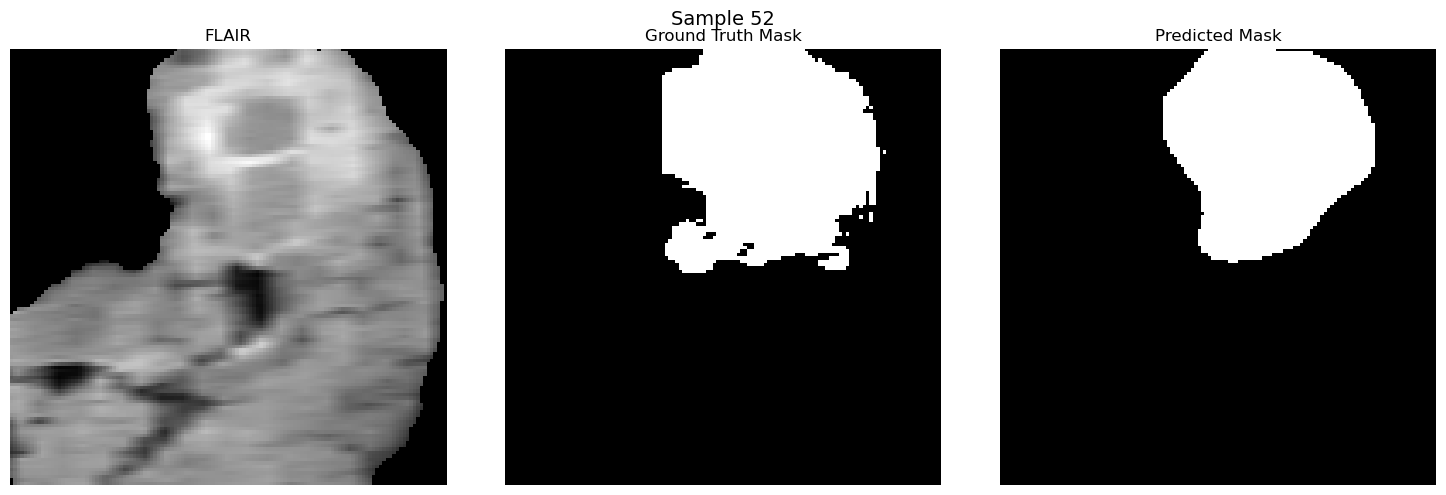

 50%|████████████████████████████████████████▉                                        | 53/105 [00:20<00:20,  2.52it/s]

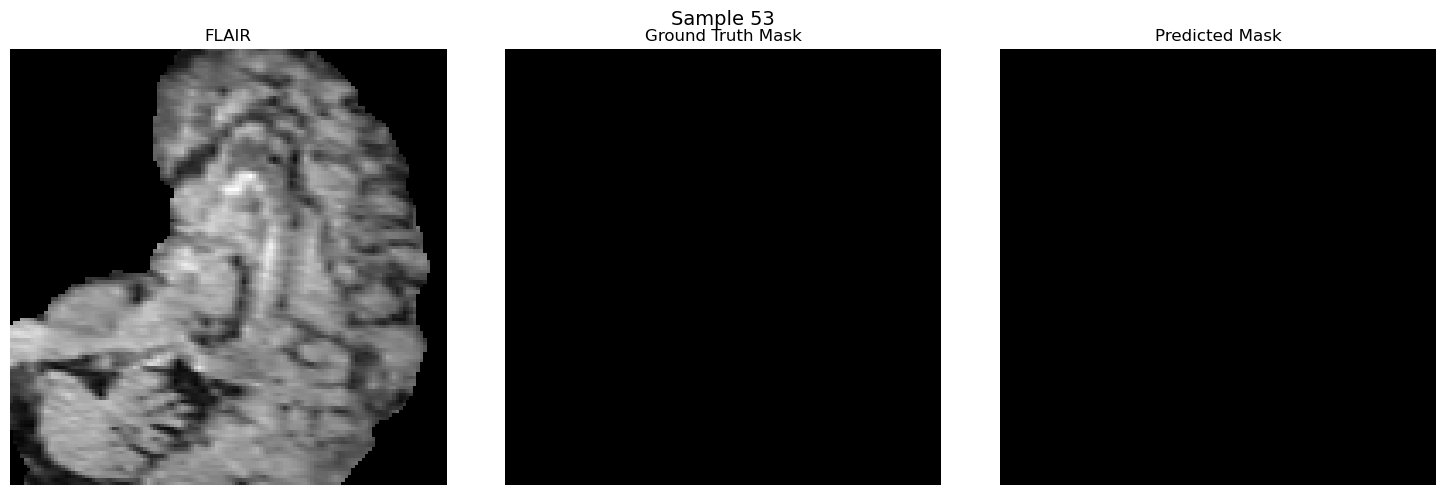

 51%|█████████████████████████████████████████▋                                       | 54/105 [00:21<00:19,  2.61it/s]

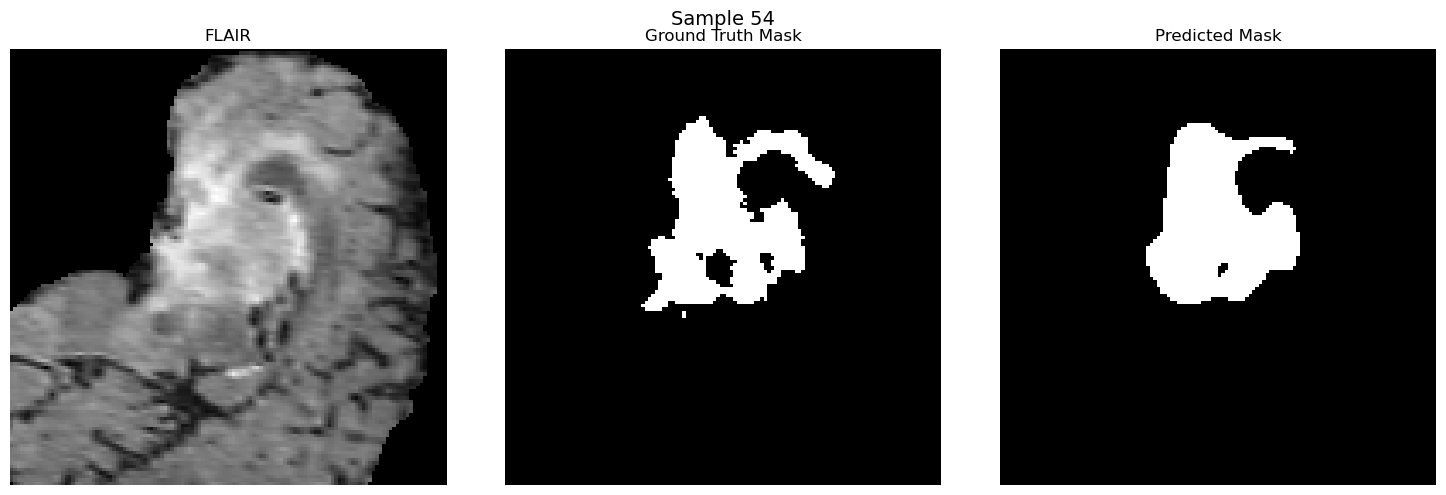

 52%|██████████████████████████████████████████▍                                      | 55/105 [00:21<00:19,  2.61it/s]

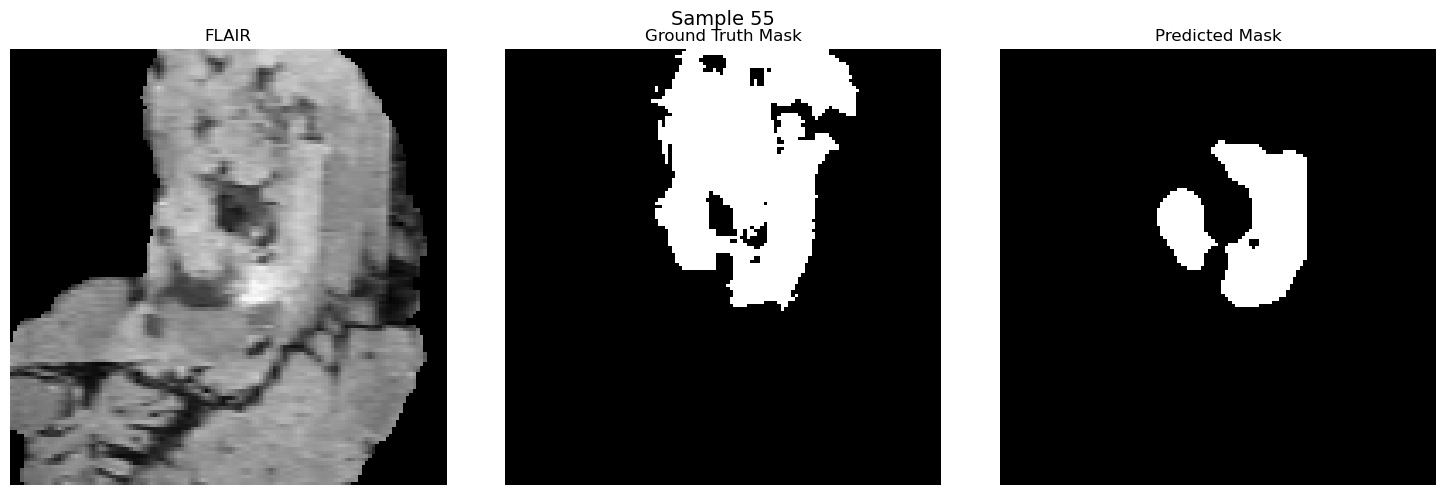

 53%|███████████████████████████████████████████▏                                     | 56/105 [00:21<00:18,  2.70it/s]

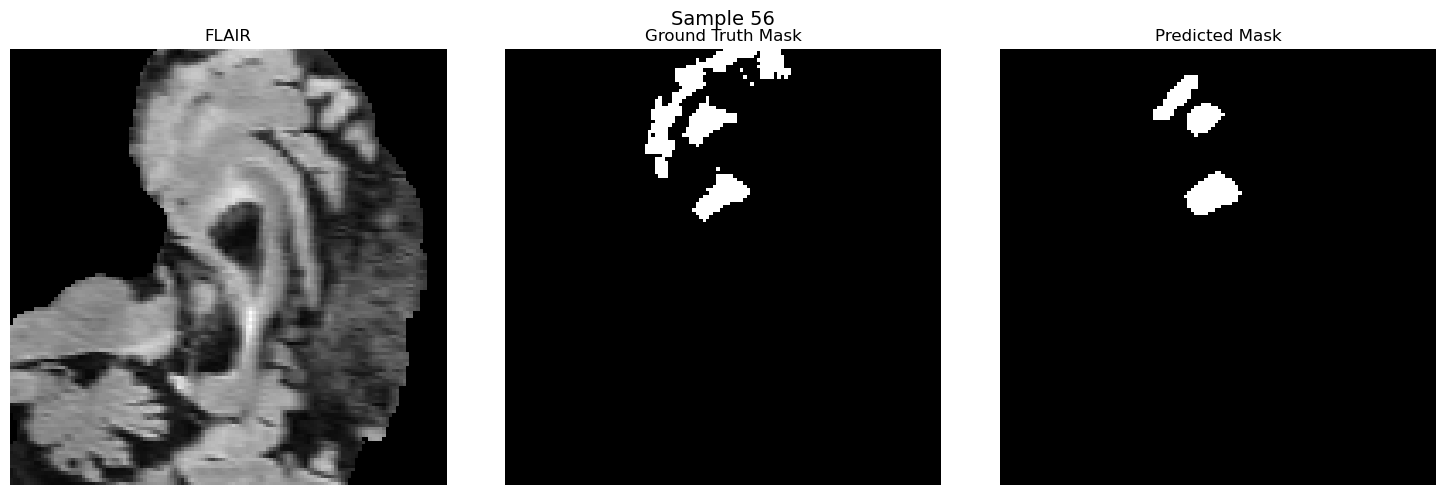

 54%|███████████████████████████████████████████▉                                     | 57/105 [00:22<00:17,  2.75it/s]

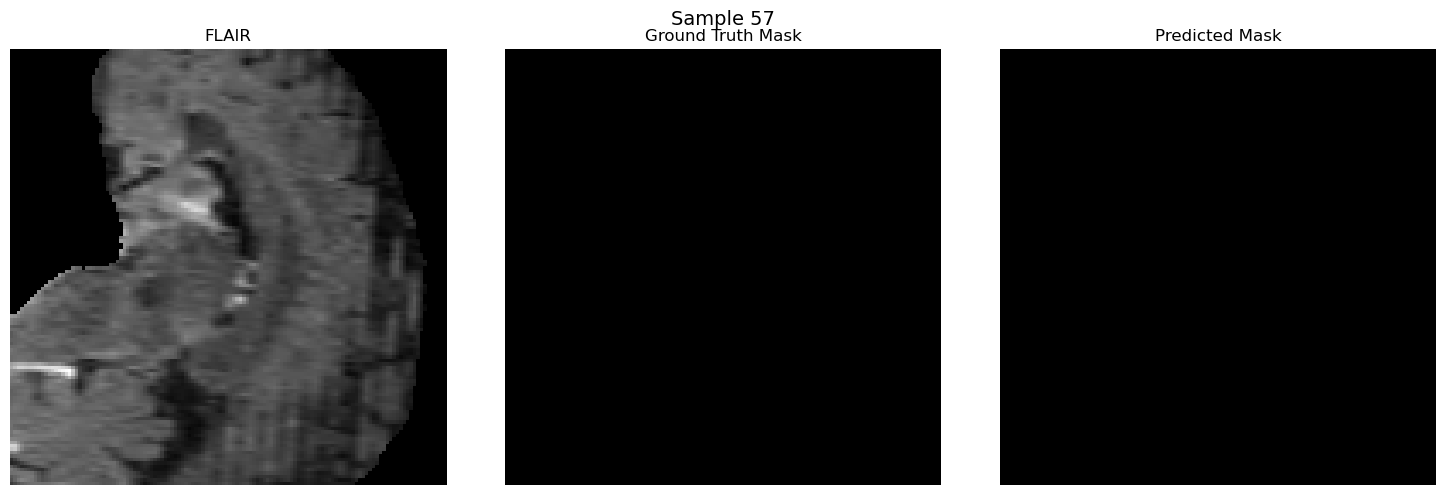

 55%|████████████████████████████████████████████▋                                    | 58/105 [00:22<00:18,  2.60it/s]

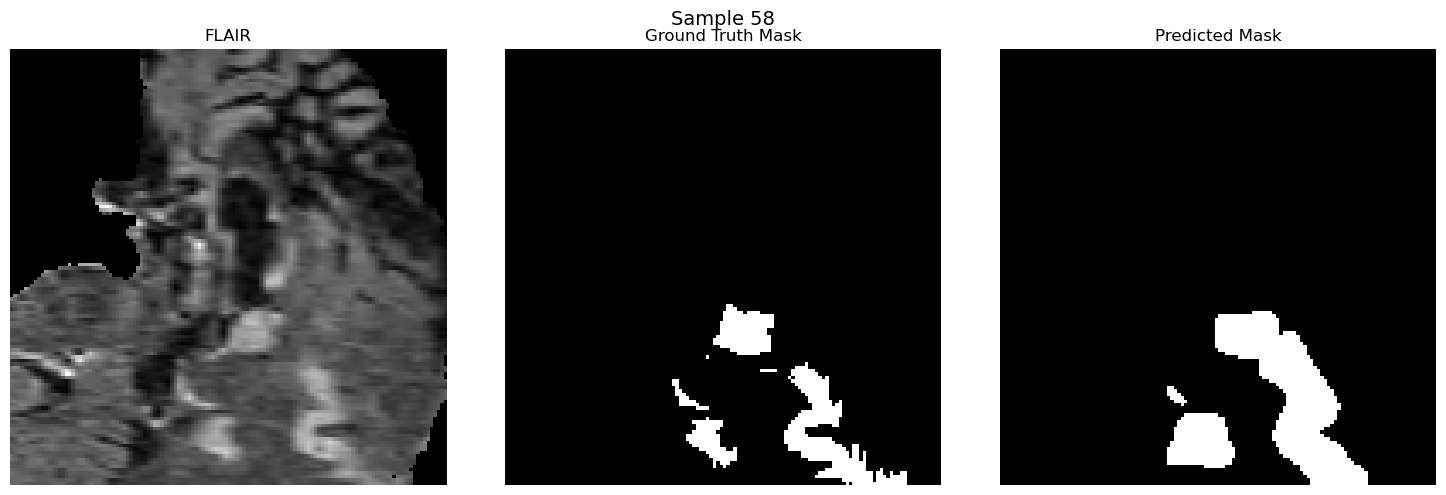

 56%|█████████████████████████████████████████████▌                                   | 59/105 [00:22<00:17,  2.60it/s]

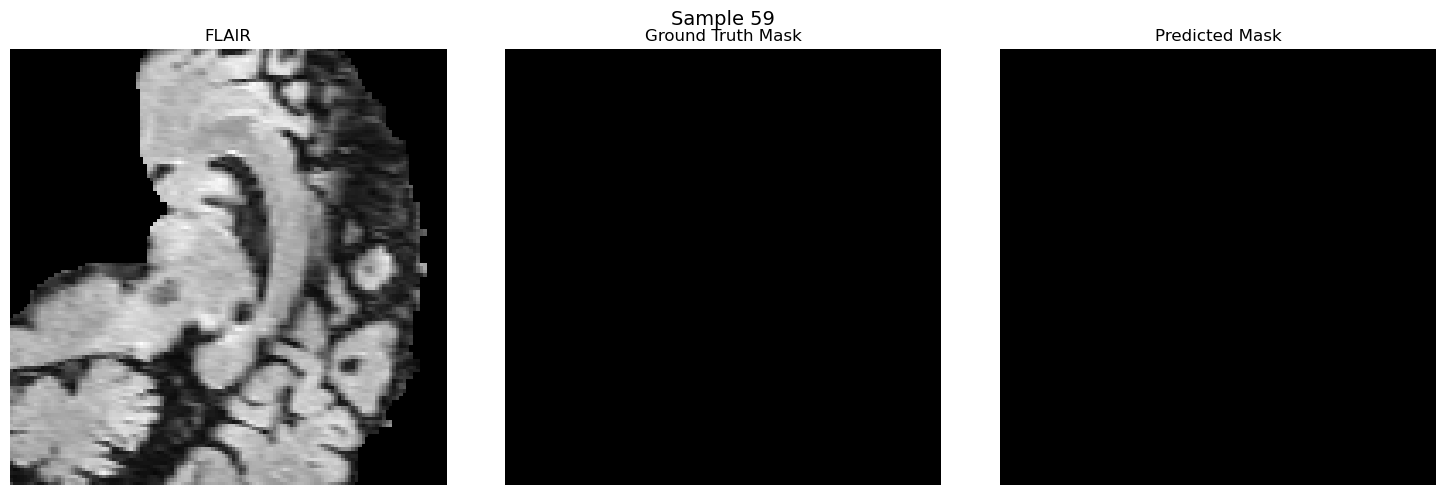

 57%|██████████████████████████████████████████████▎                                  | 60/105 [00:23<00:17,  2.64it/s]

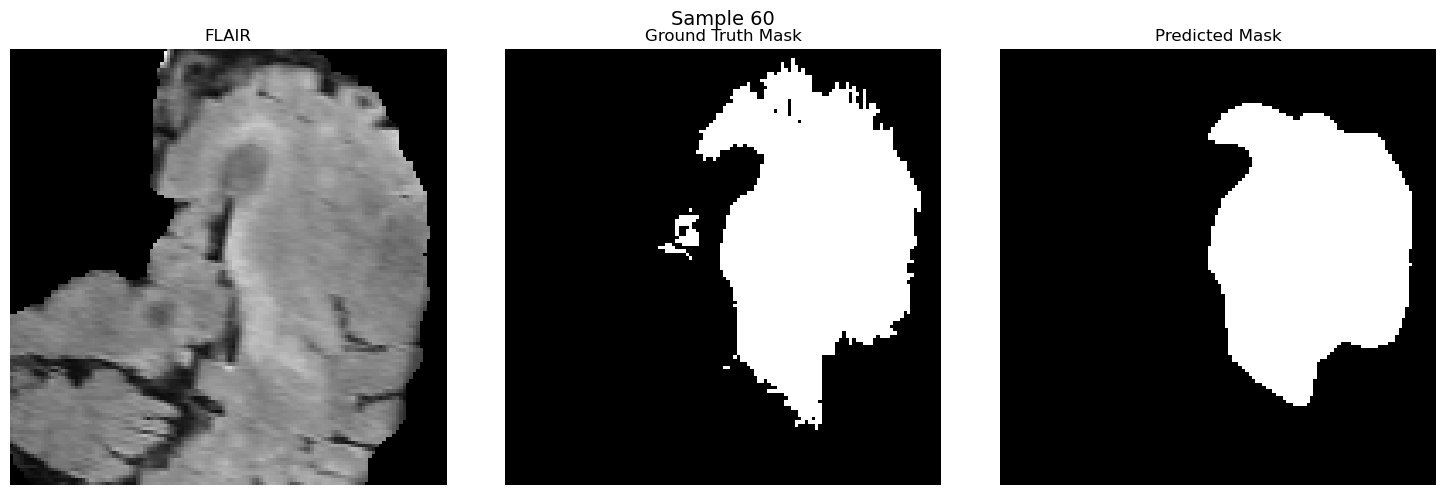

 58%|███████████████████████████████████████████████                                  | 61/105 [00:23<00:16,  2.71it/s]

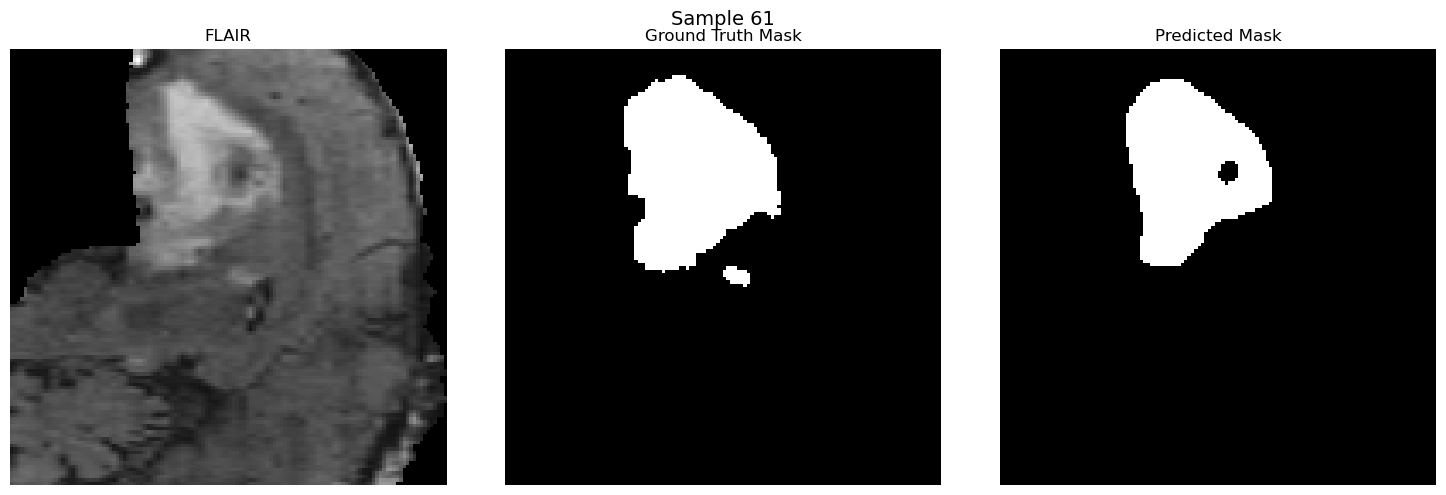

 59%|███████████████████████████████████████████████▊                                 | 62/105 [00:23<00:15,  2.74it/s]

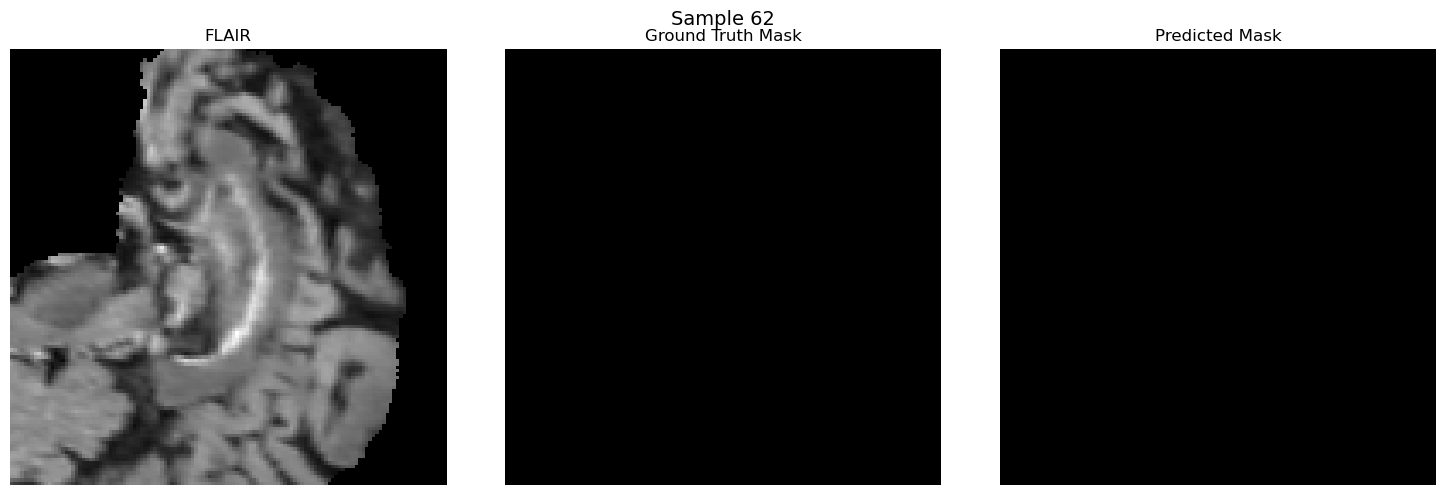

 60%|████████████████████████████████████████████████▌                                | 63/105 [00:24<00:15,  2.79it/s]

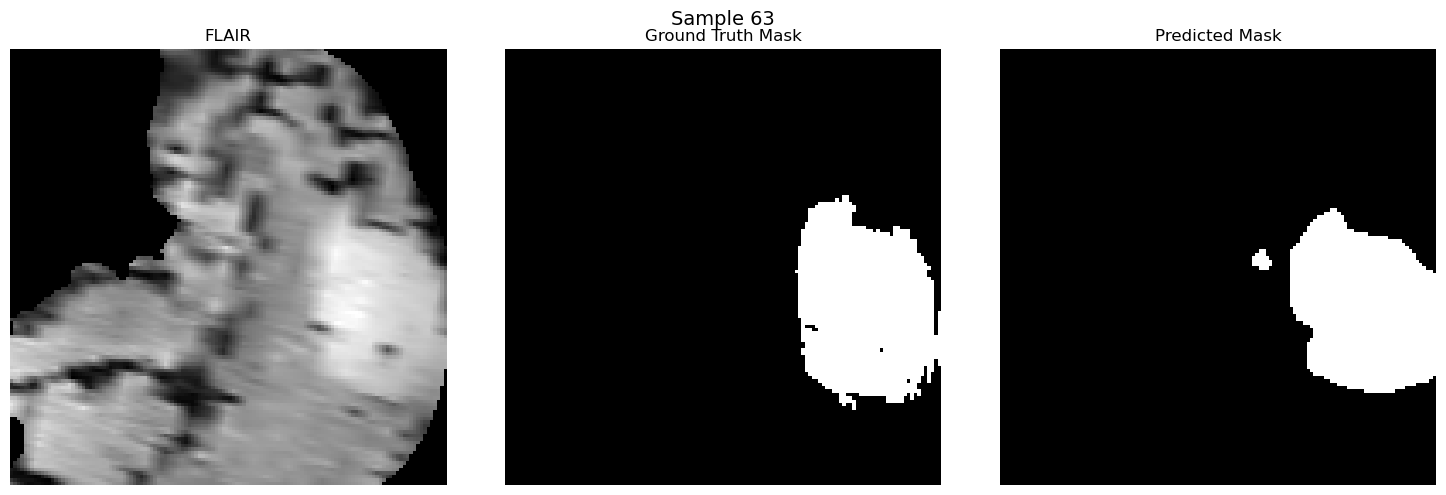

 61%|█████████████████████████████████████████████████▎                               | 64/105 [00:24<00:14,  2.85it/s]

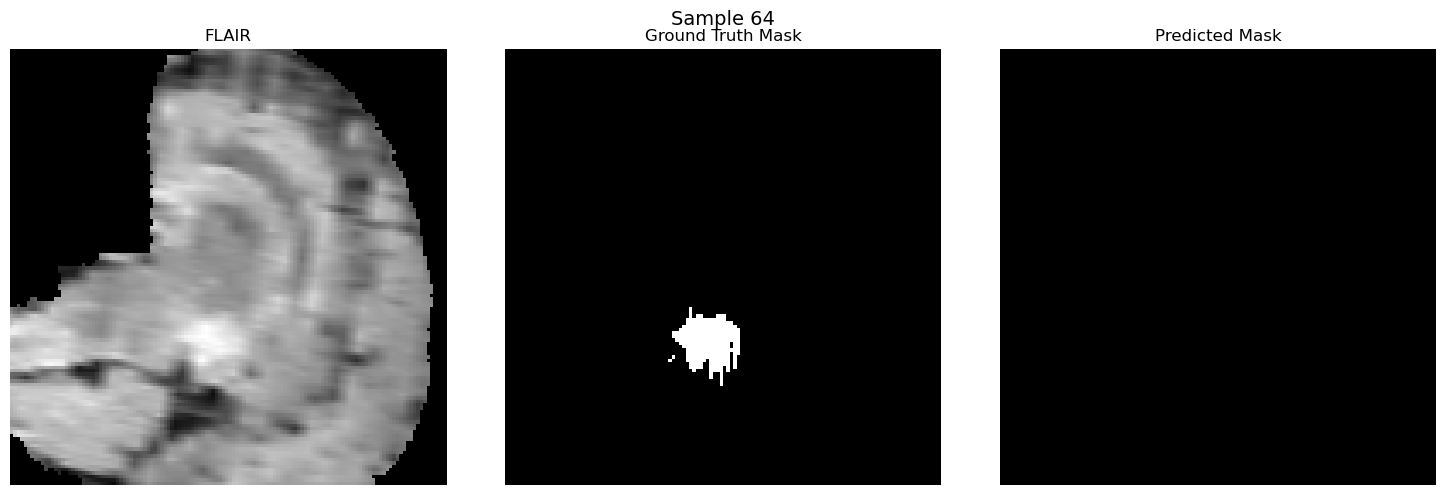

 62%|██████████████████████████████████████████████████▏                              | 65/105 [00:25<00:14,  2.81it/s]

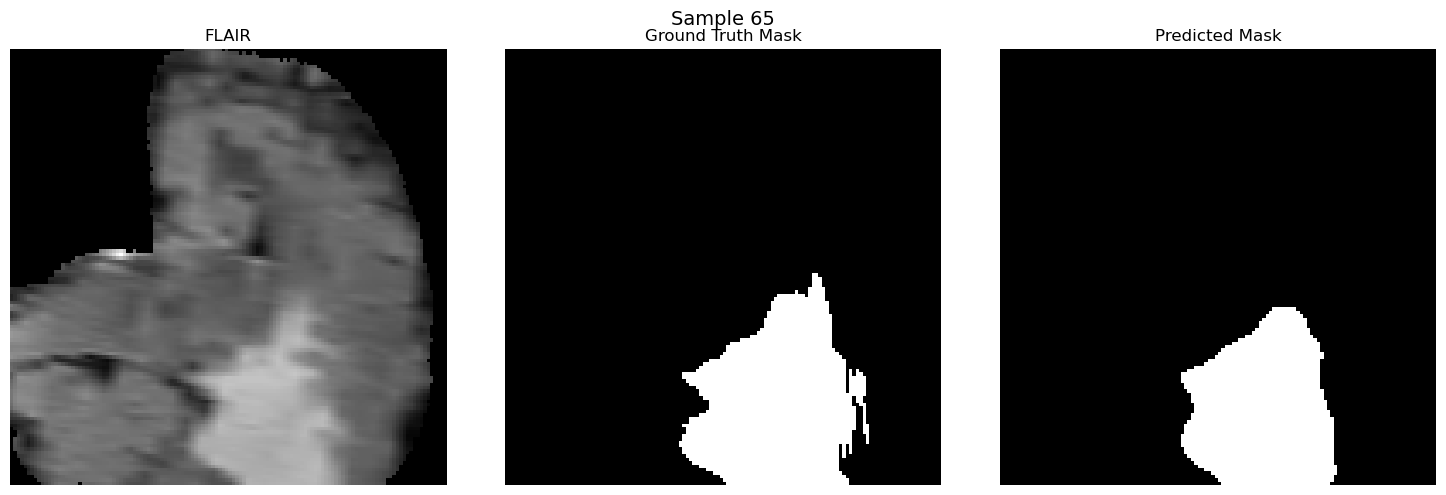

 63%|██████████████████████████████████████████████████▉                              | 66/105 [00:25<00:14,  2.70it/s]

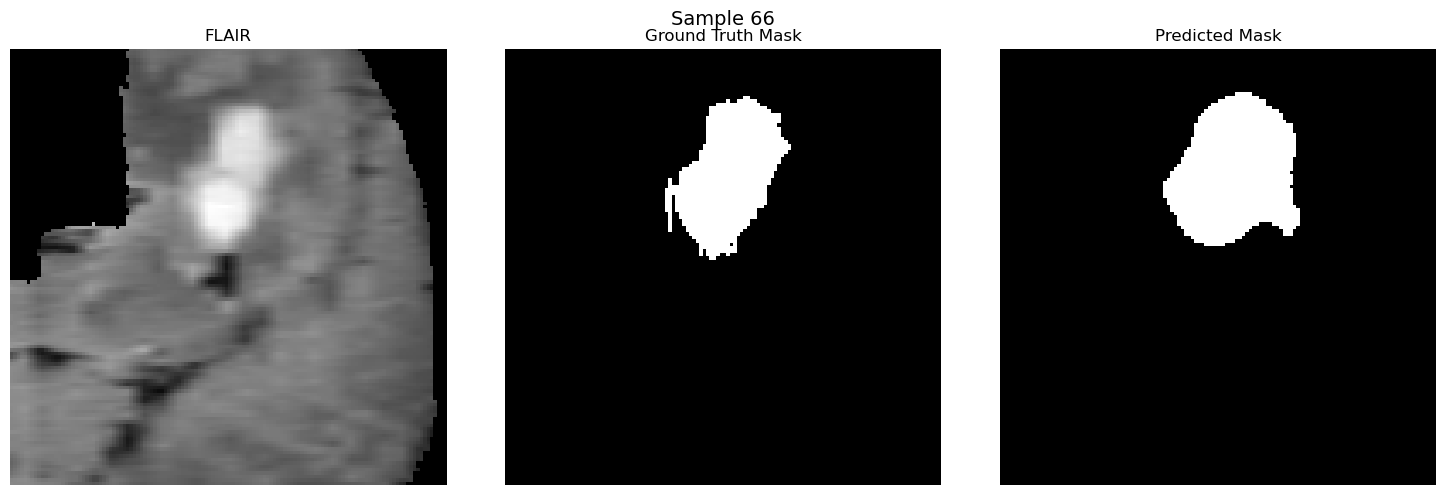

 64%|███████████████████████████████████████████████████▋                             | 67/105 [00:26<00:17,  2.18it/s]

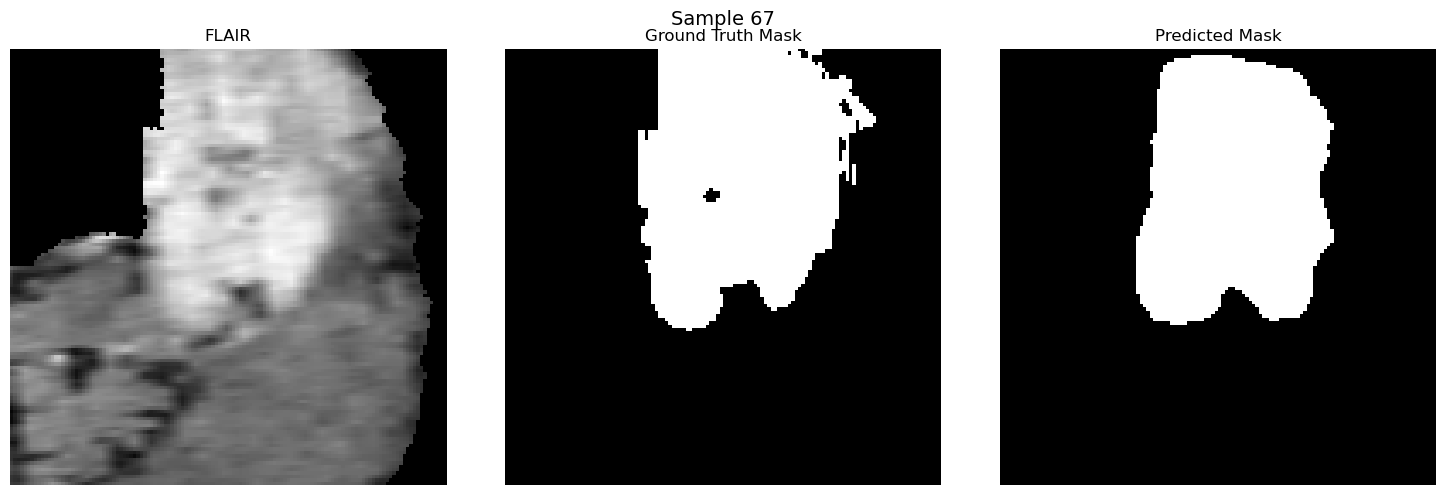

 65%|████████████████████████████████████████████████████▍                            | 68/105 [00:26<00:15,  2.36it/s]

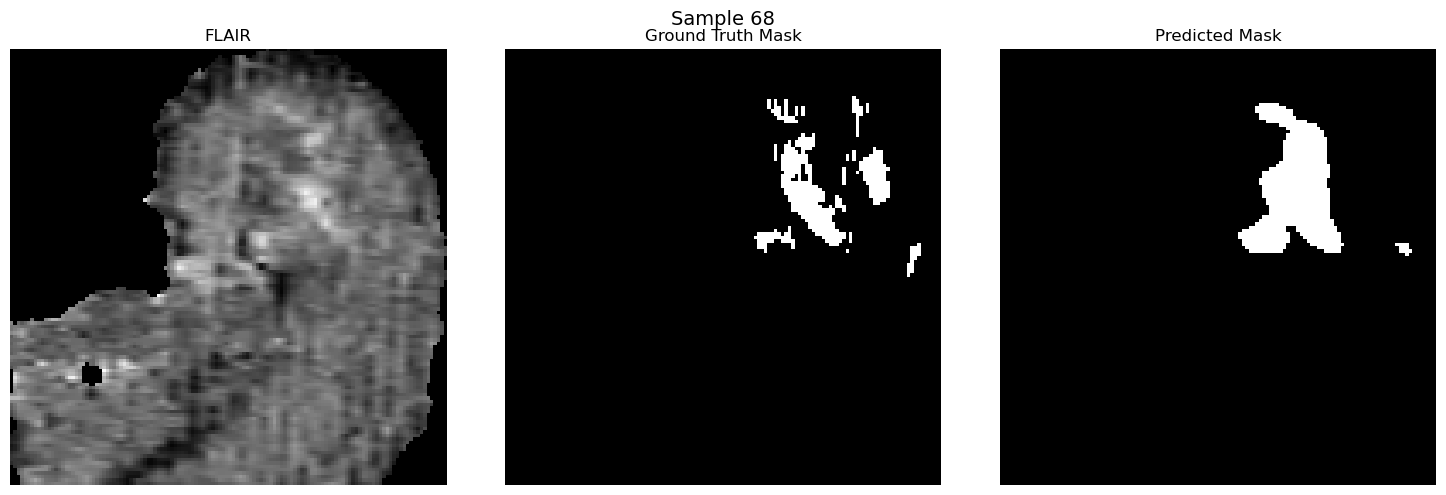

 66%|█████████████████████████████████████████████████████▏                           | 69/105 [00:26<00:14,  2.51it/s]

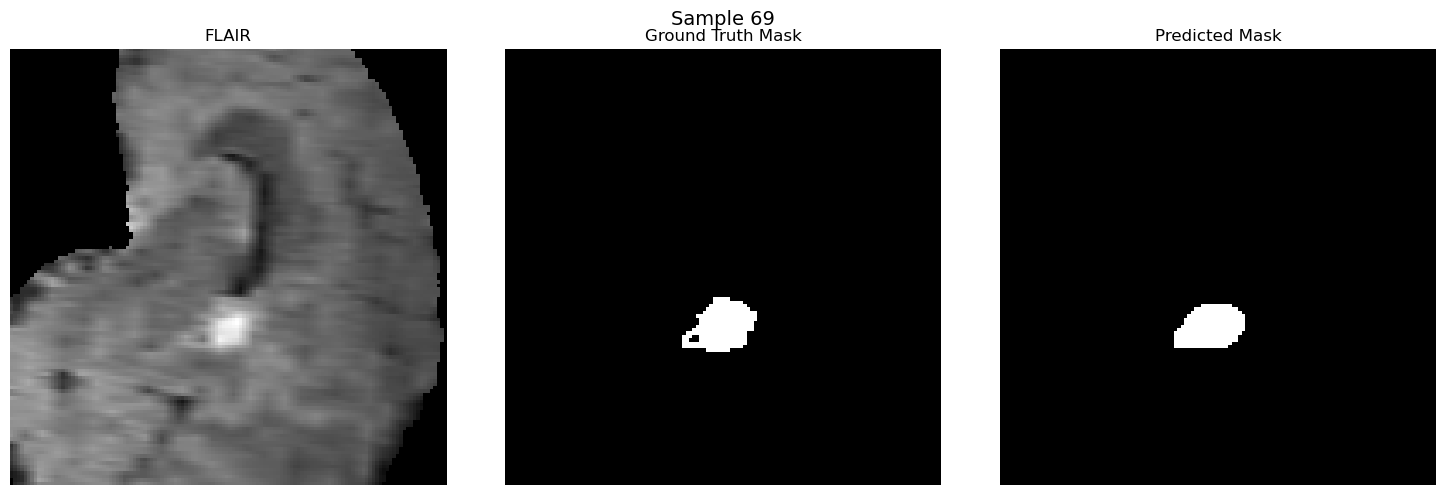

 67%|██████████████████████████████████████████████████████                           | 70/105 [00:27<00:13,  2.57it/s]

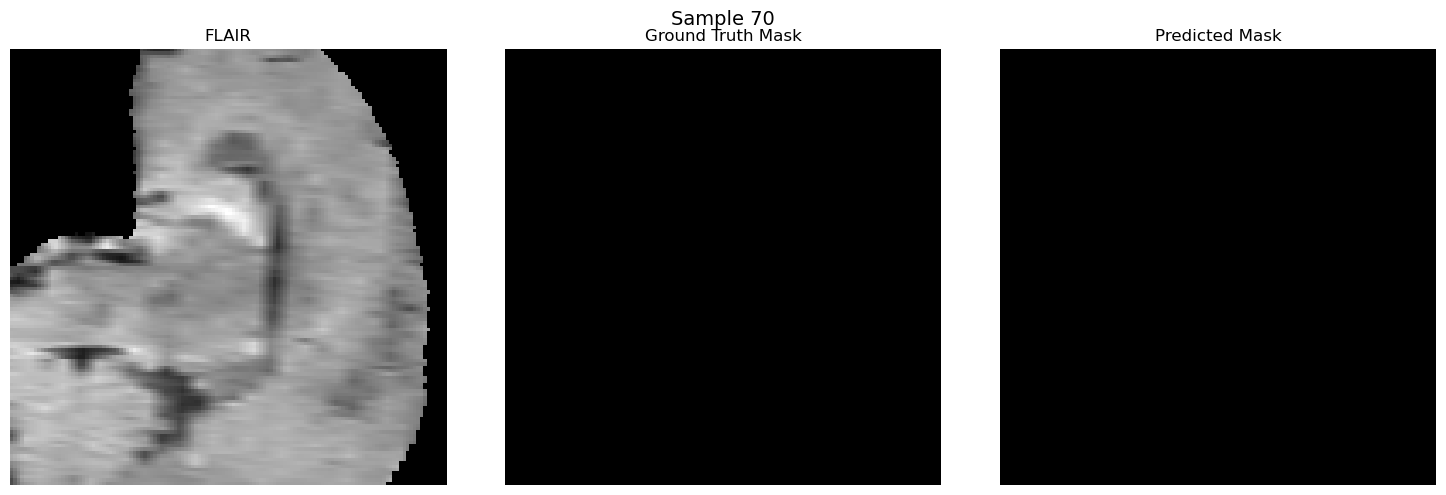

 68%|██████████████████████████████████████████████████████▊                          | 71/105 [00:27<00:13,  2.53it/s]

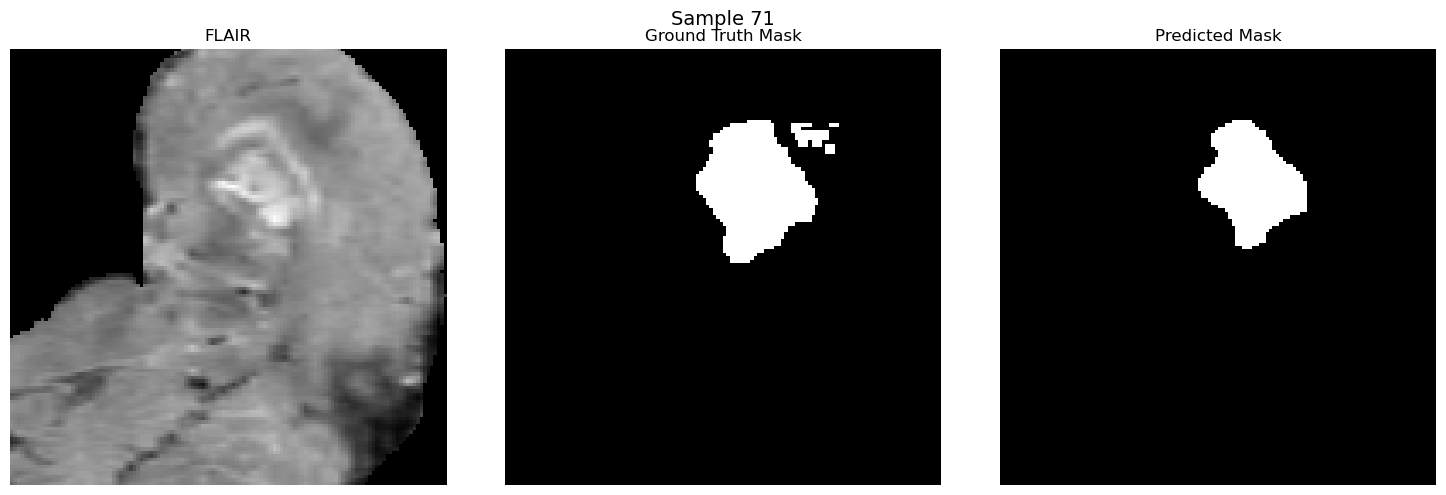

 69%|███████████████████████████████████████████████████████▌                         | 72/105 [00:27<00:13,  2.52it/s]

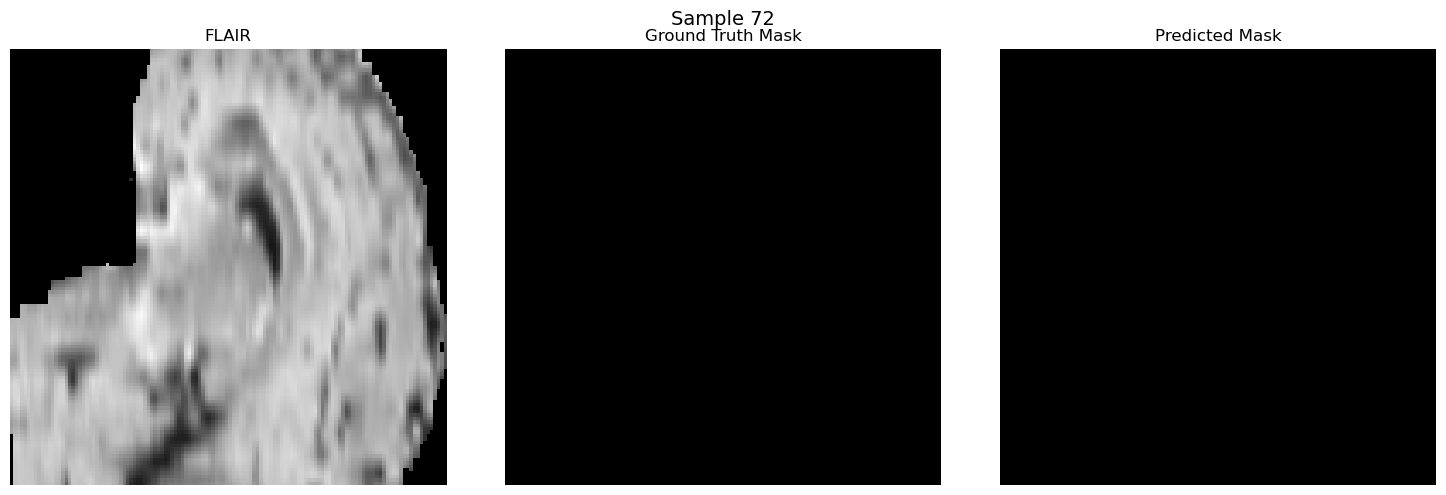

 70%|████████████████████████████████████████████████████████▎                        | 73/105 [00:28<00:12,  2.51it/s]

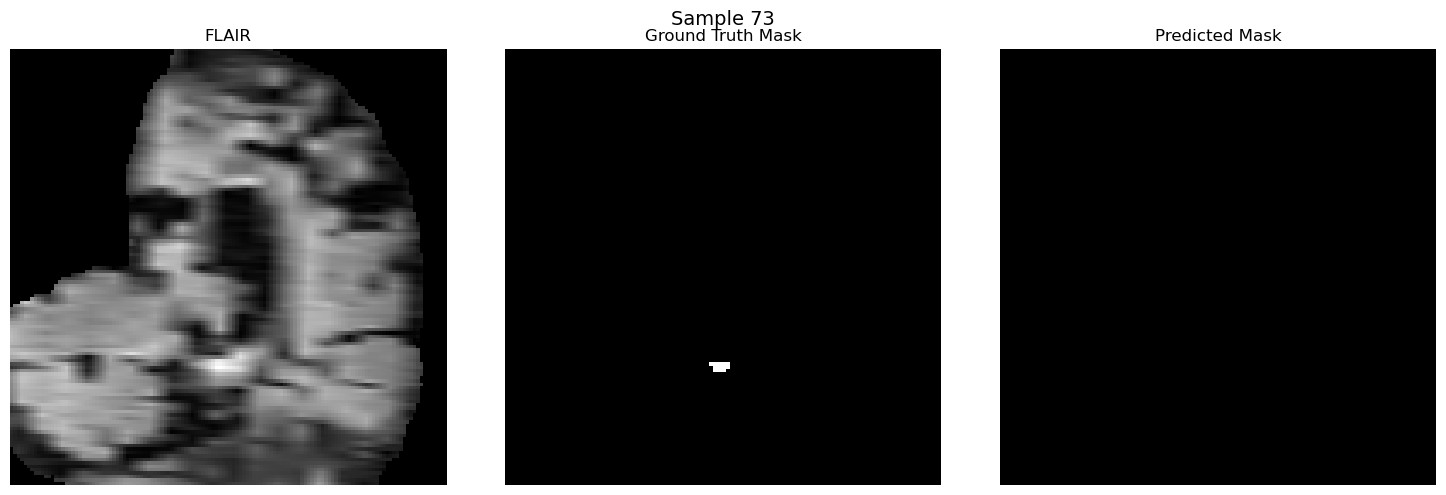

 70%|█████████████████████████████████████████████████████████                        | 74/105 [00:28<00:12,  2.42it/s]

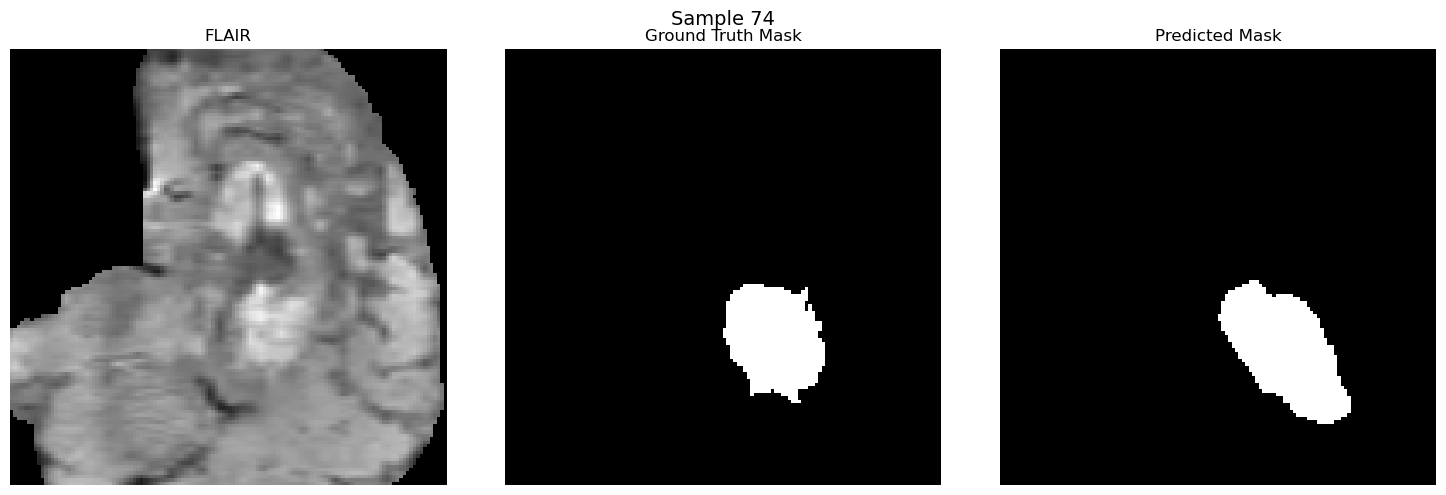

 71%|█████████████████████████████████████████████████████████▊                       | 75/105 [00:29<00:12,  2.39it/s]

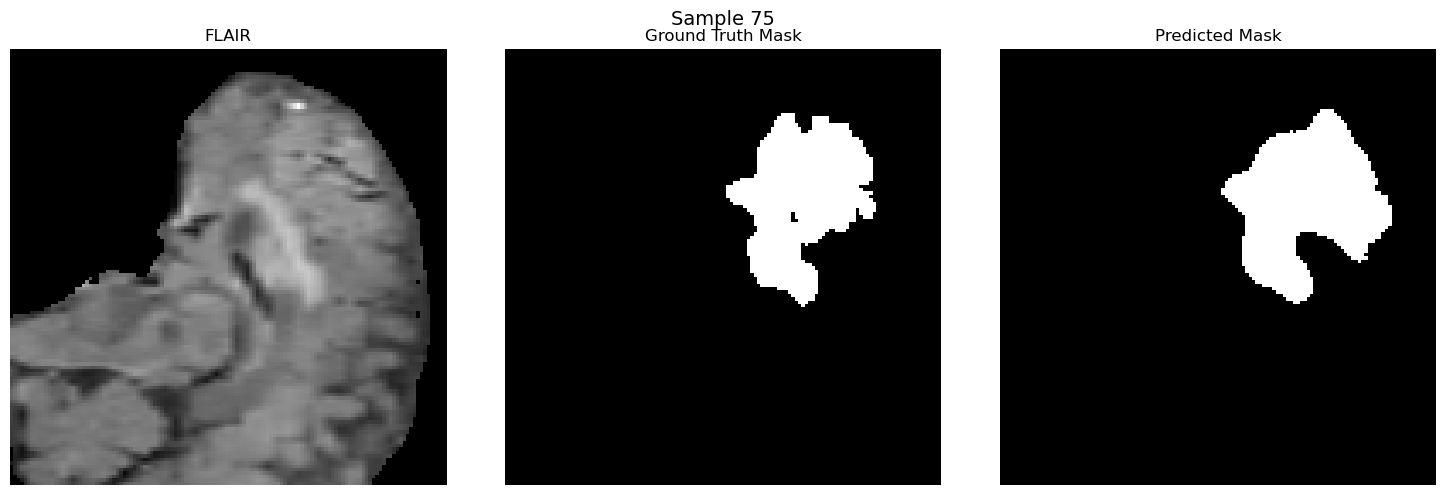

 72%|██████████████████████████████████████████████████████████▋                      | 76/105 [00:29<00:12,  2.30it/s]

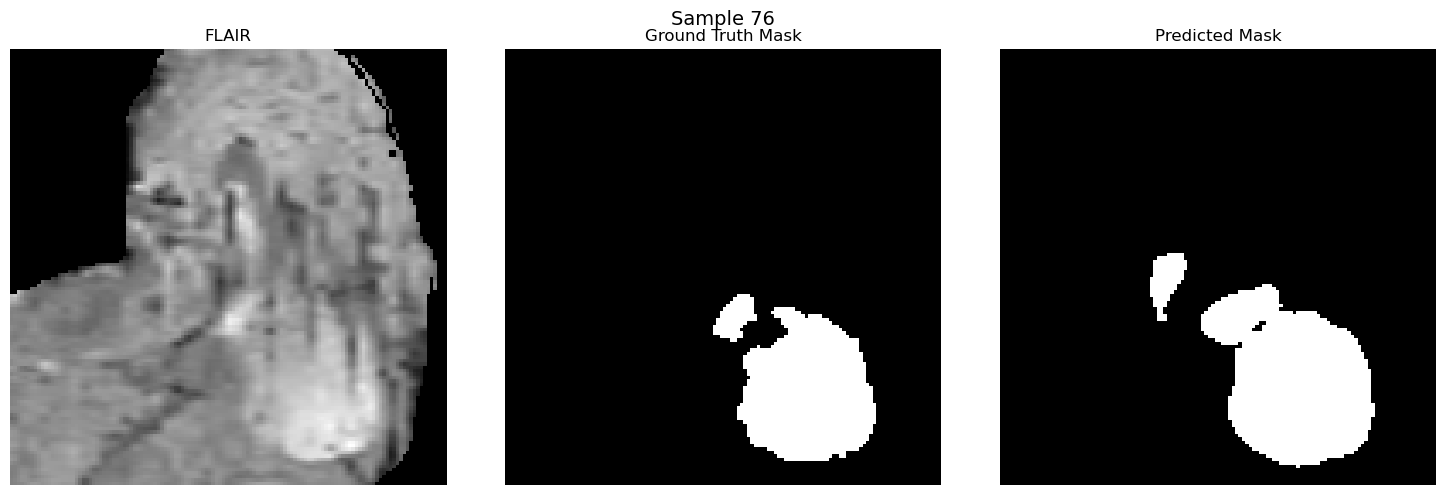

 73%|███████████████████████████████████████████████████████████▍                     | 77/105 [00:30<00:12,  2.29it/s]

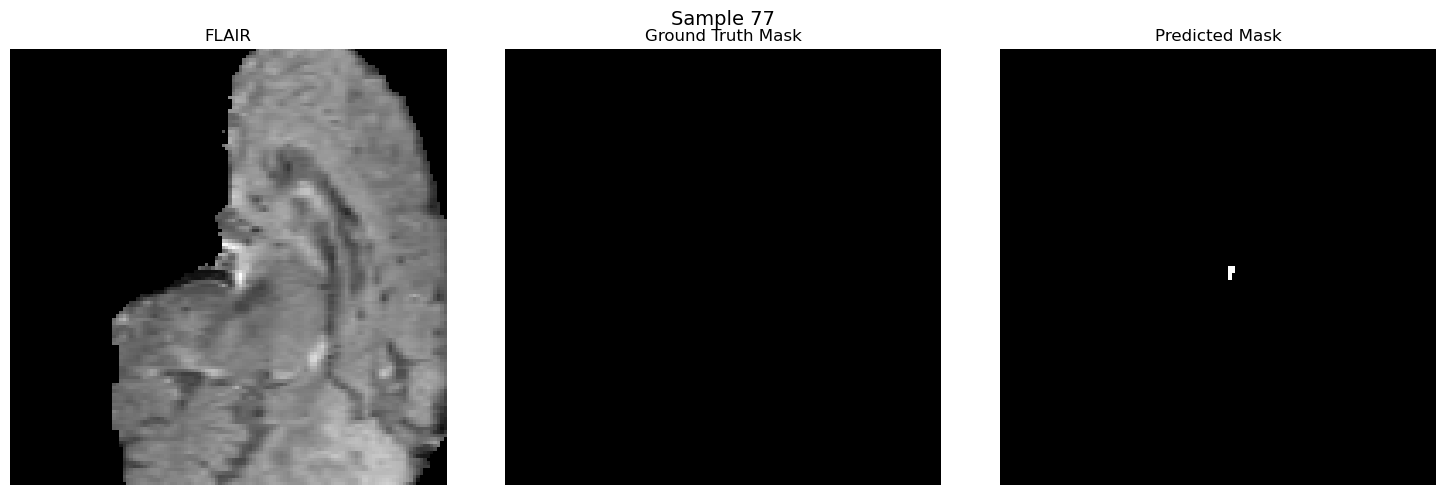

 74%|████████████████████████████████████████████████████████████▏                    | 78/105 [00:30<00:11,  2.37it/s]

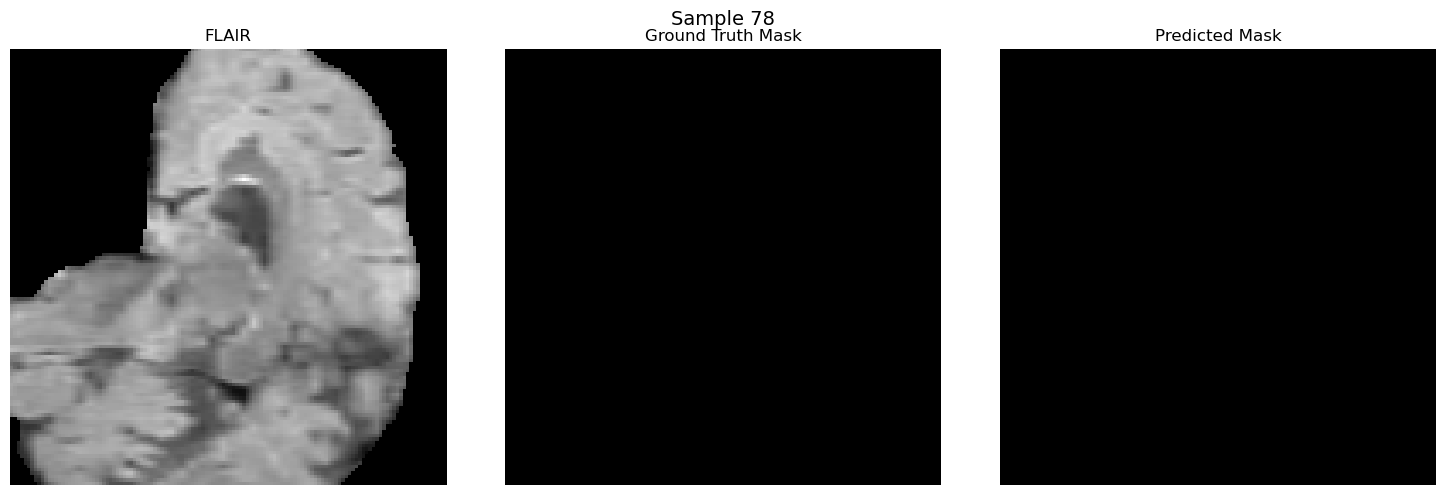

 75%|████████████████████████████████████████████████████████████▉                    | 79/105 [00:30<00:10,  2.40it/s]

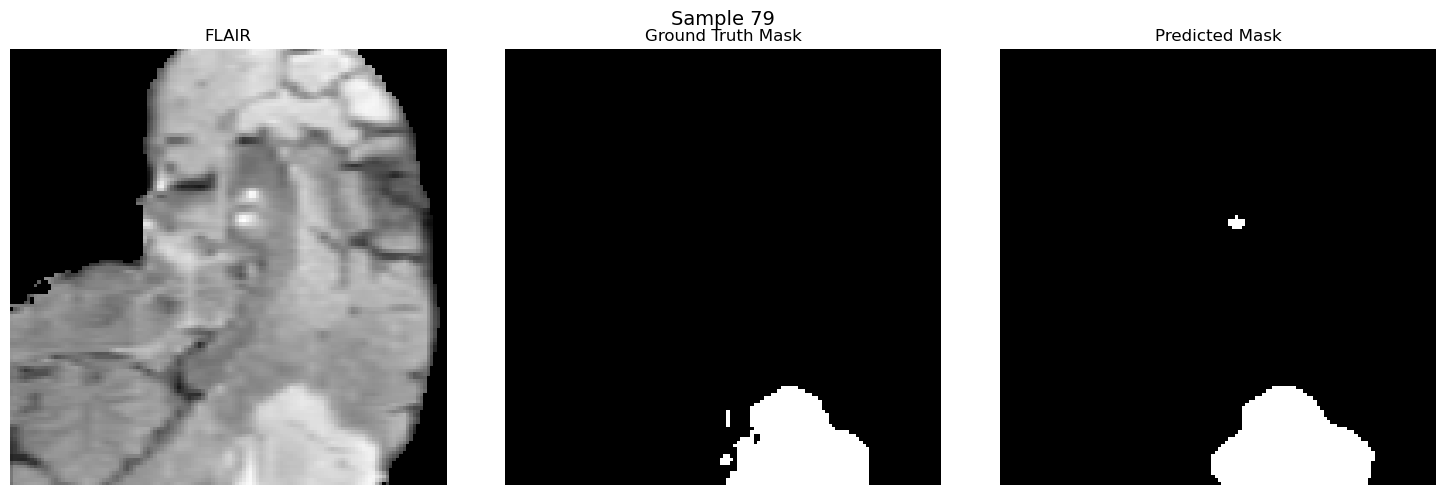

 76%|█████████████████████████████████████████████████████████████▋                   | 80/105 [00:31<00:10,  2.31it/s]

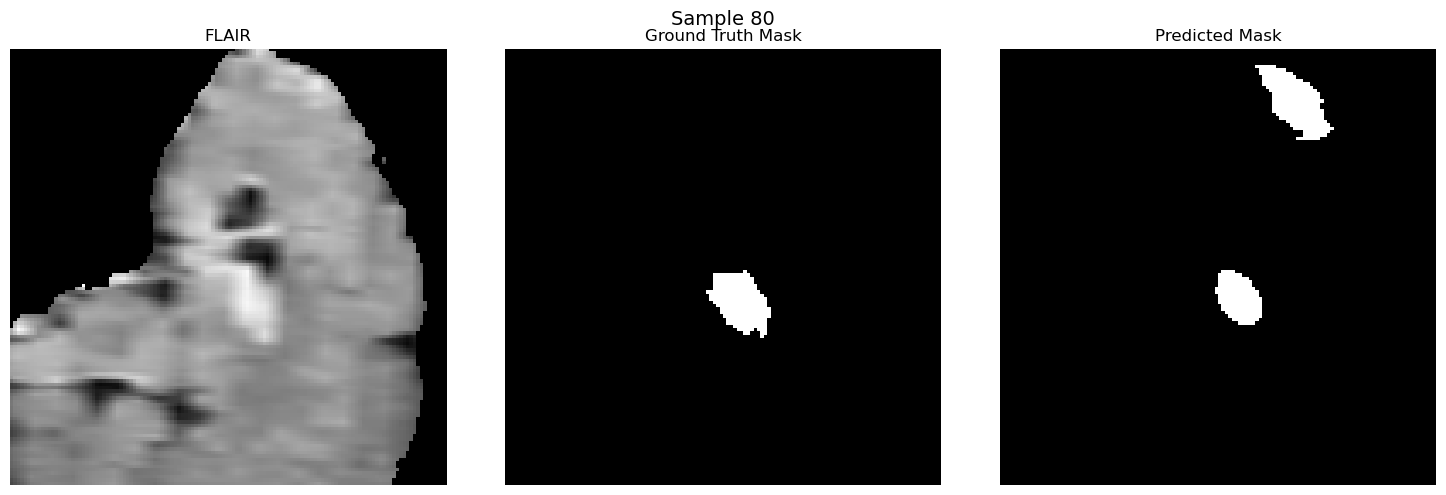

 77%|██████████████████████████████████████████████████████████████▍                  | 81/105 [00:31<00:10,  2.30it/s]

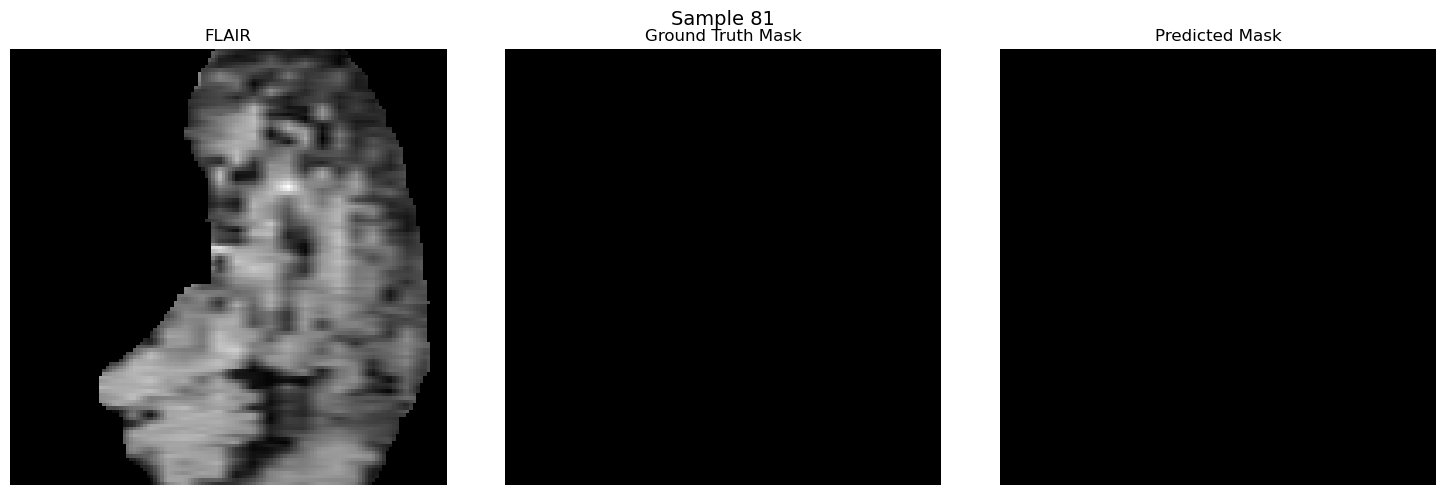

 78%|███████████████████████████████████████████████████████████████▎                 | 82/105 [00:32<00:09,  2.30it/s]

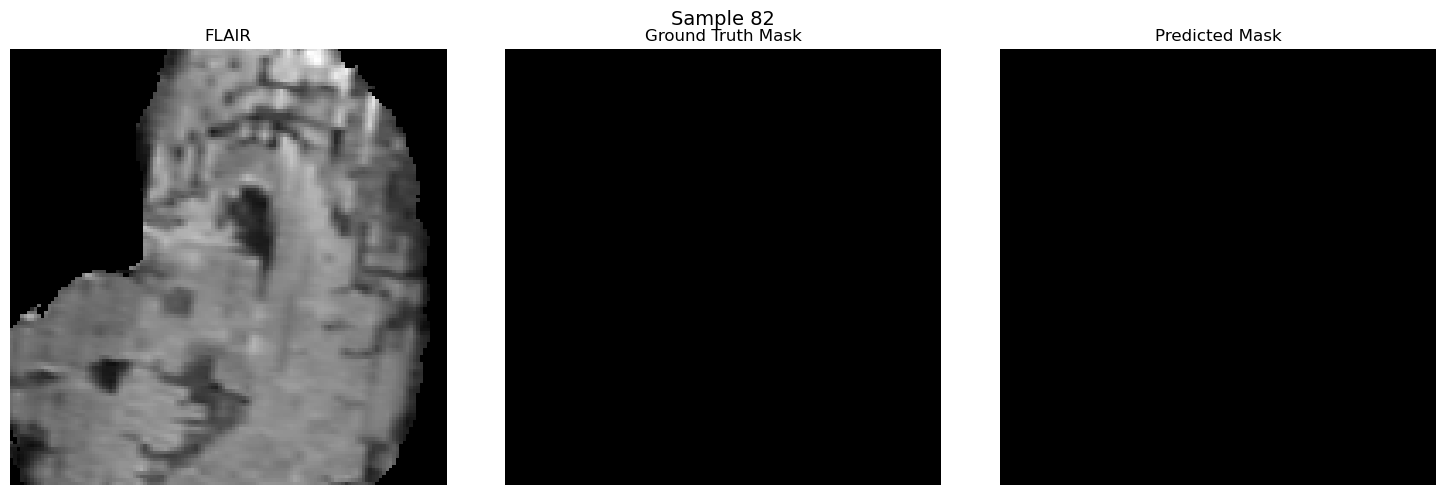

 79%|████████████████████████████████████████████████████████████████                 | 83/105 [00:32<00:09,  2.25it/s]

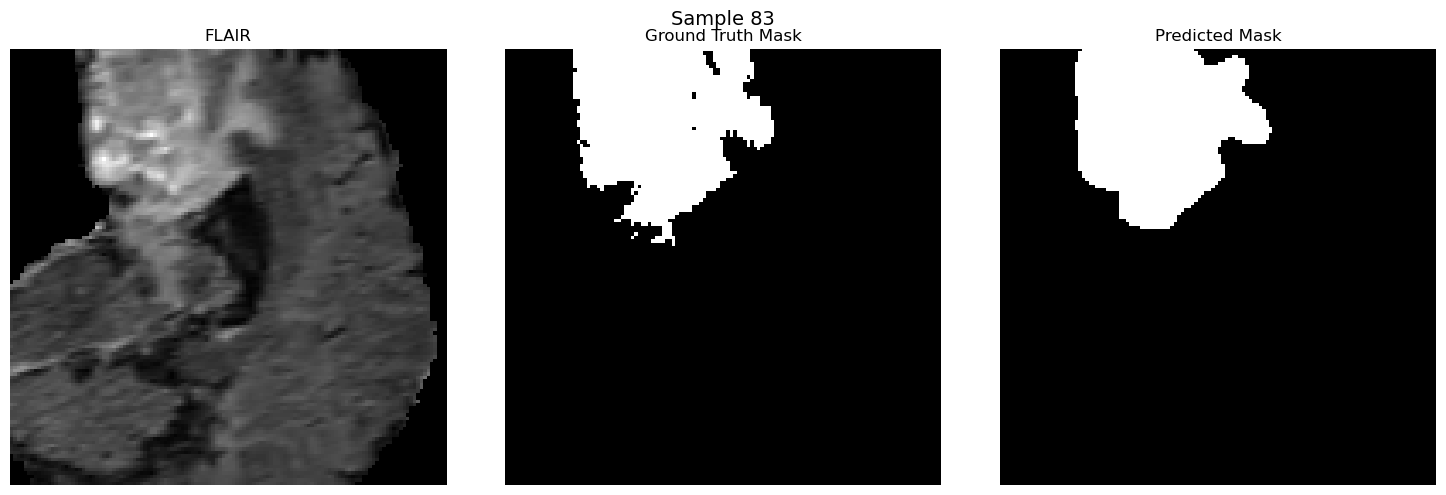

 80%|████████████████████████████████████████████████████████████████▊                | 84/105 [00:33<00:09,  2.26it/s]

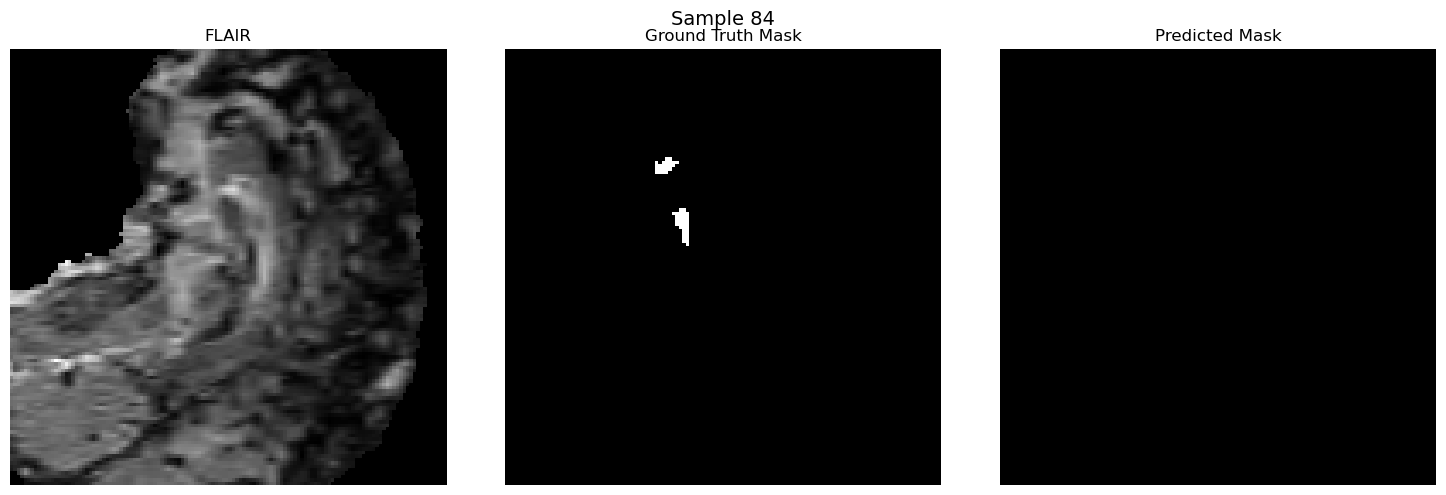

 81%|█████████████████████████████████████████████████████████████████▌               | 85/105 [00:33<00:08,  2.25it/s]

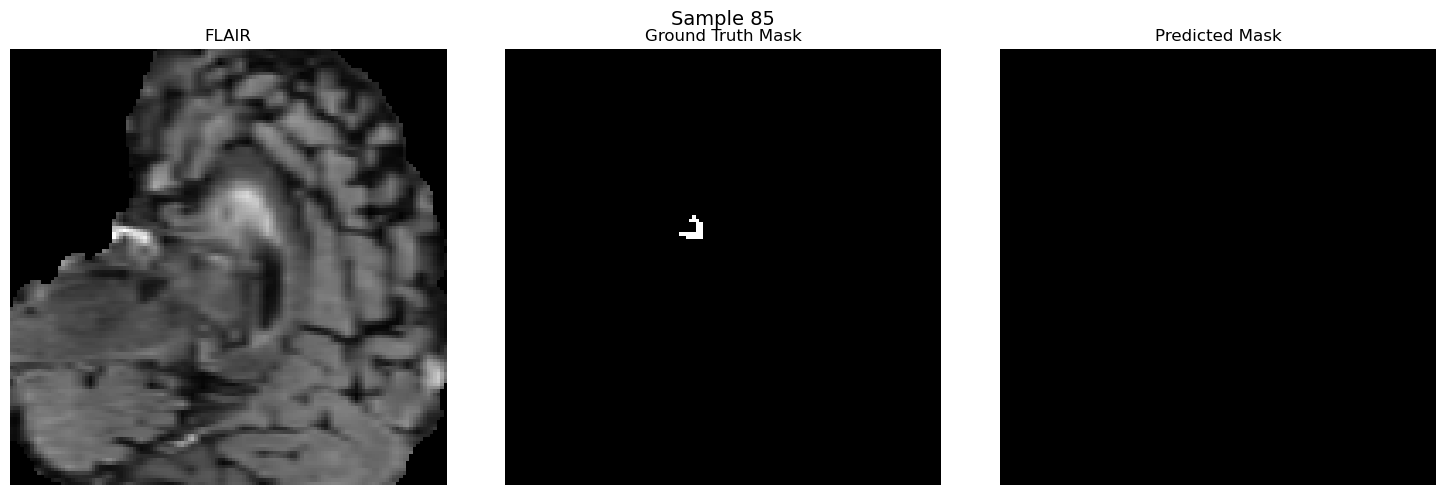

 82%|██████████████████████████████████████████████████████████████████▎              | 86/105 [00:34<00:10,  1.90it/s]

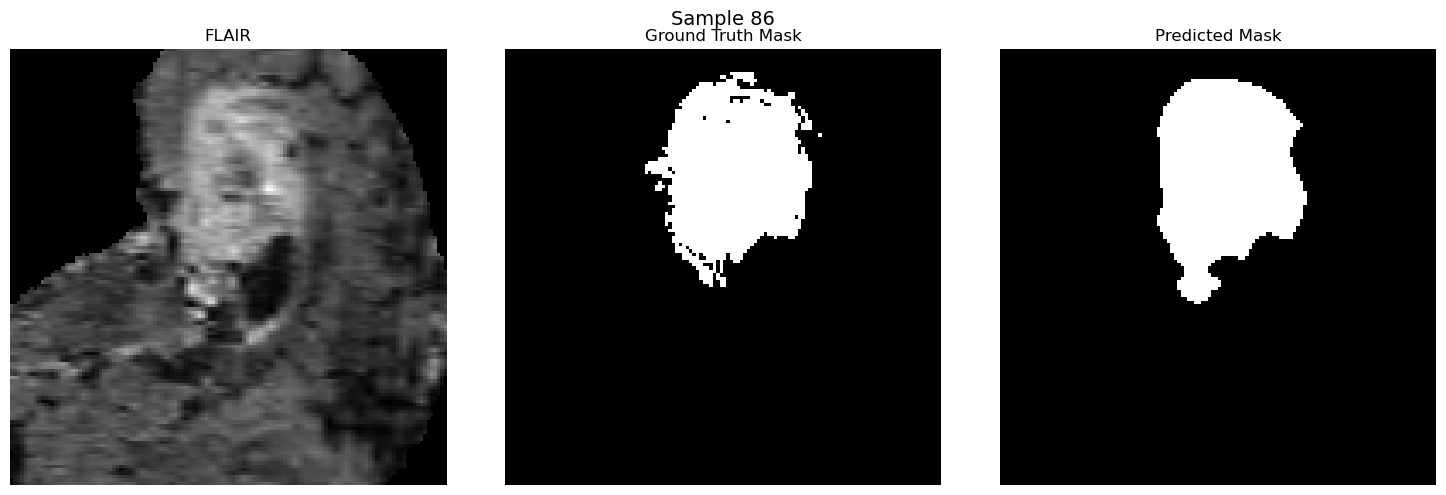

 83%|███████████████████████████████████████████████████████████████████              | 87/105 [00:34<00:08,  2.00it/s]

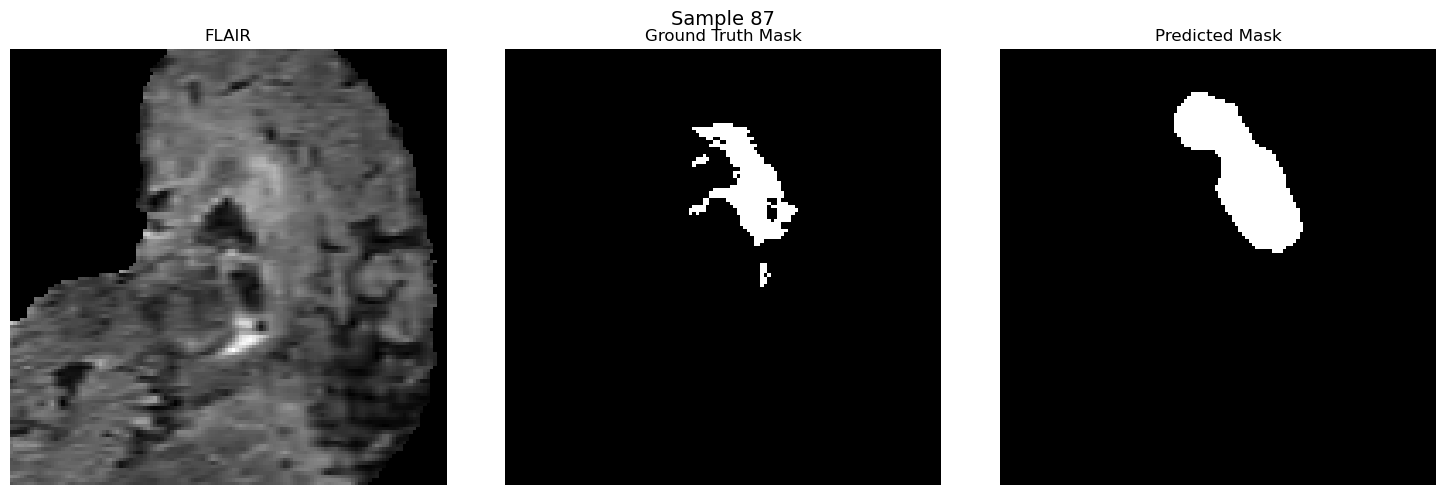

 84%|███████████████████████████████████████████████████████████████████▉             | 88/105 [00:35<00:08,  2.03it/s]

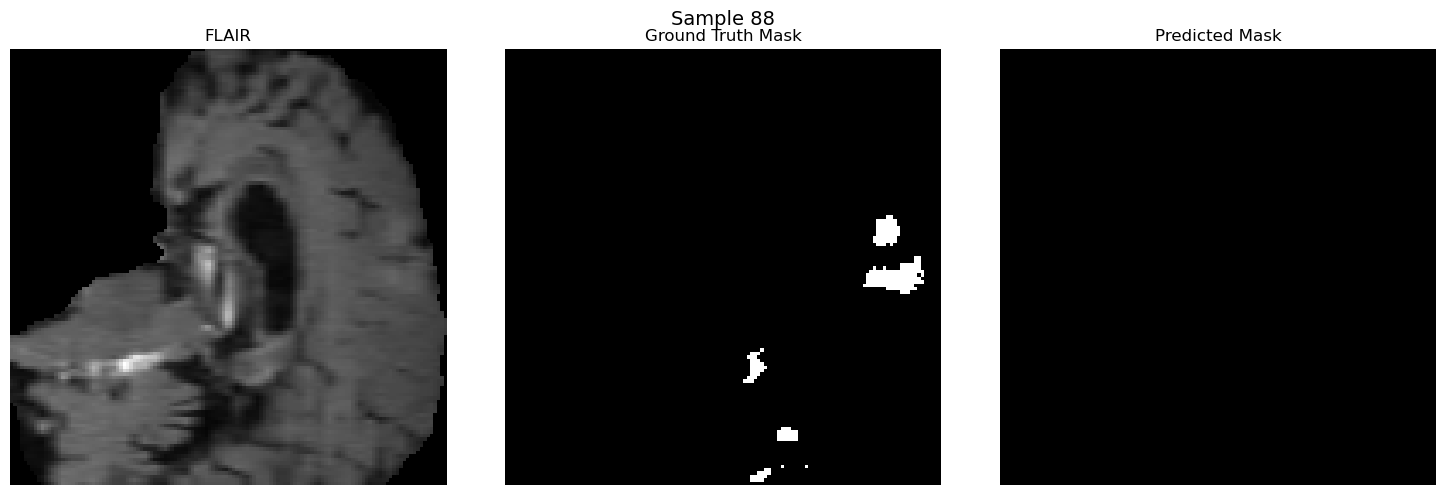

 85%|████████████████████████████████████████████████████████████████████▋            | 89/105 [00:35<00:07,  2.06it/s]

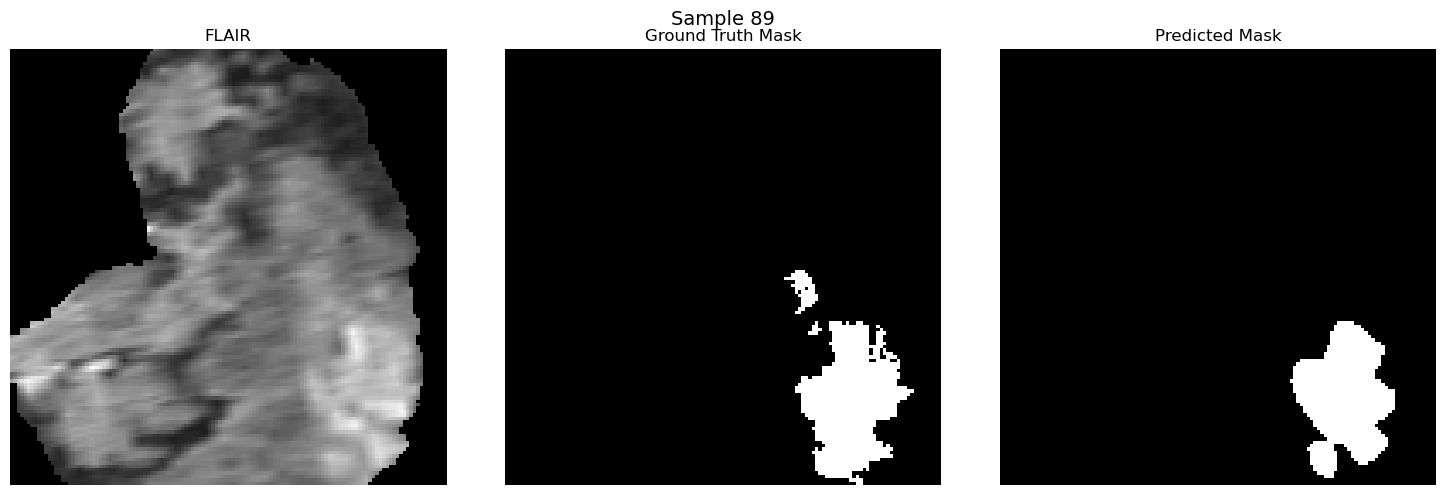

 86%|█████████████████████████████████████████████████████████████████████▍           | 90/105 [00:36<00:06,  2.16it/s]

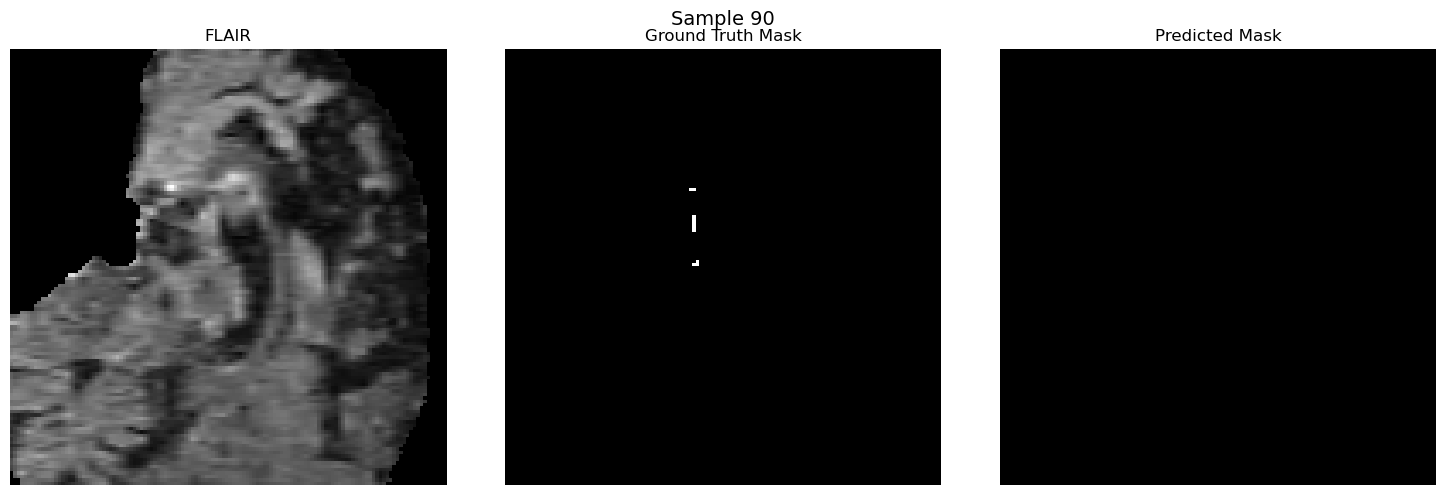

 87%|██████████████████████████████████████████████████████████████████████▏          | 91/105 [00:36<00:06,  2.20it/s]

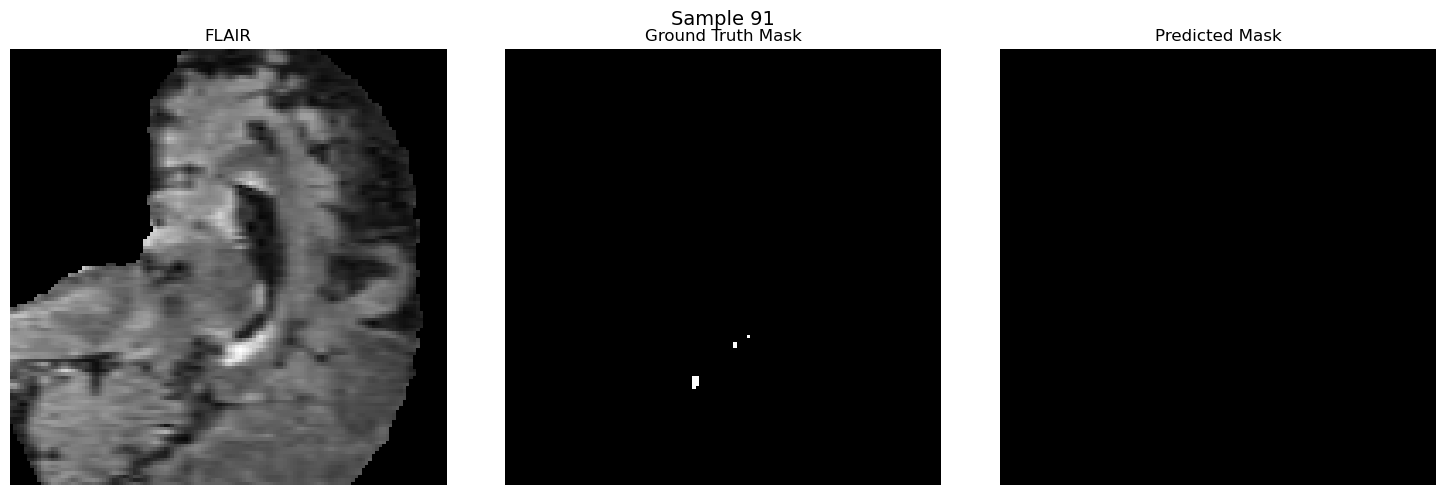

 88%|██████████████████████████████████████████████████████████████████████▉          | 92/105 [00:36<00:05,  2.26it/s]

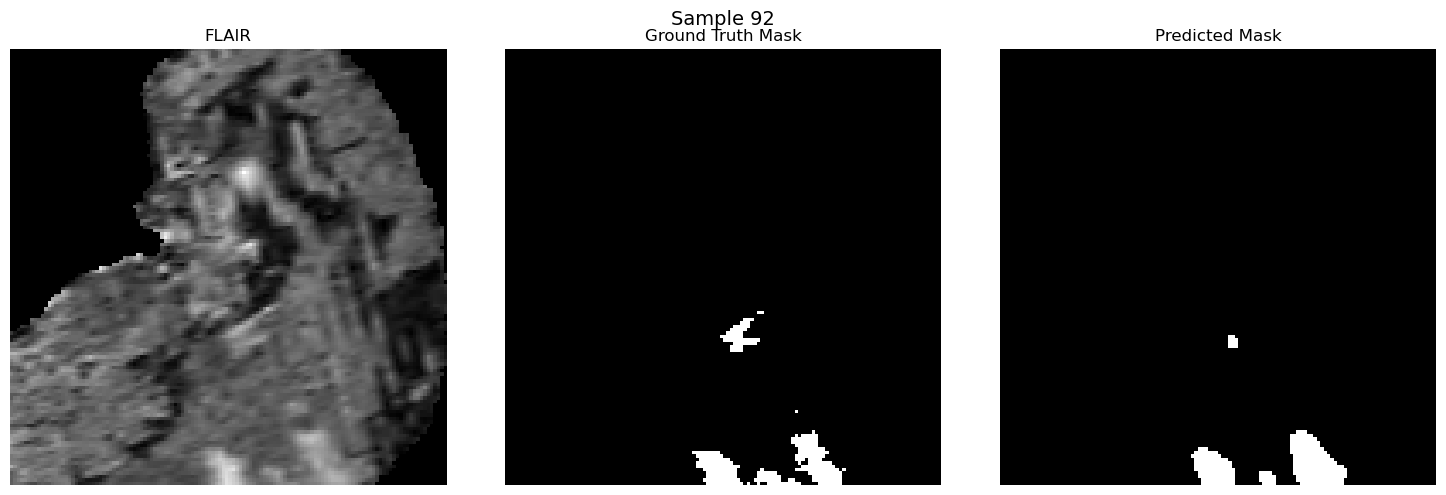

 89%|███████████████████████████████████████████████████████████████████████▋         | 93/105 [00:37<00:05,  2.25it/s]

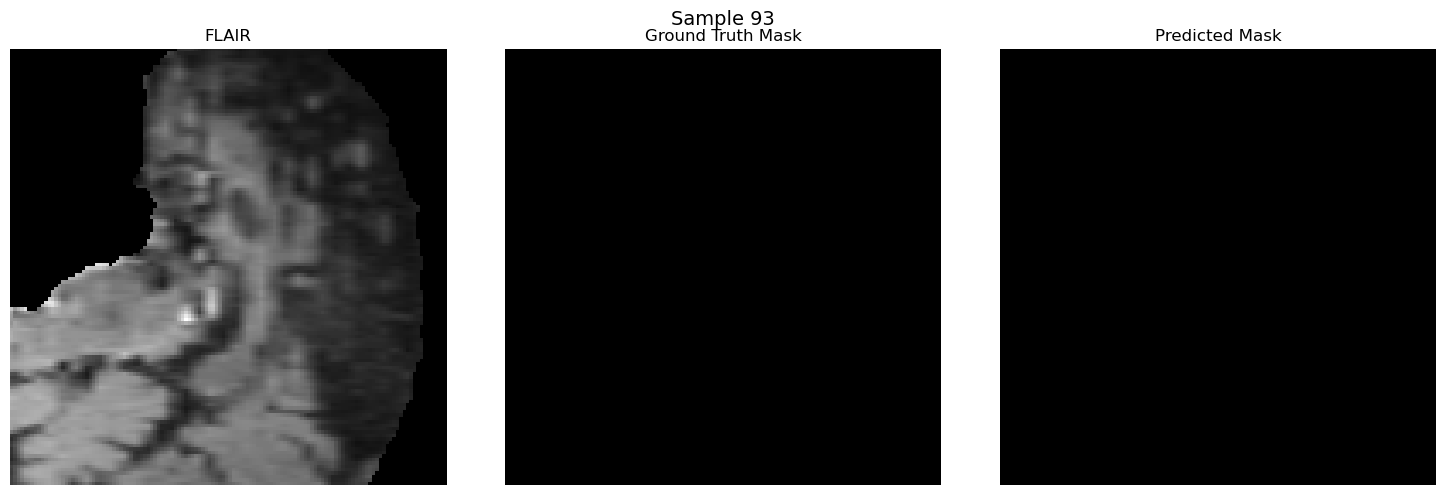

 90%|████████████████████████████████████████████████████████████████████████▌        | 94/105 [00:37<00:04,  2.23it/s]

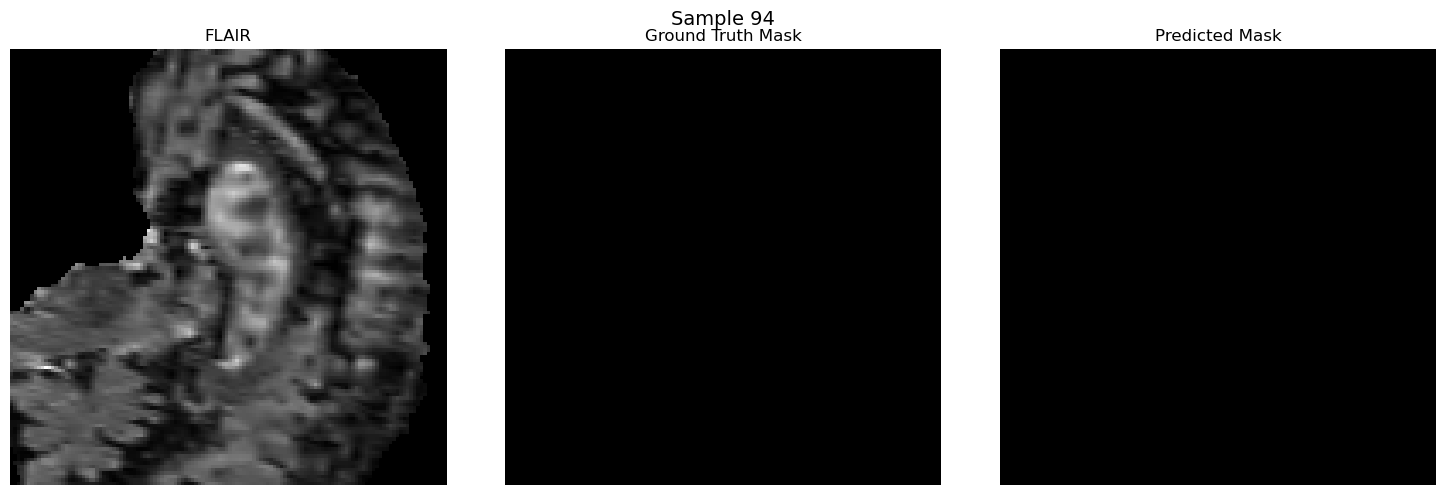

 90%|█████████████████████████████████████████████████████████████████████████▎       | 95/105 [00:38<00:04,  2.23it/s]

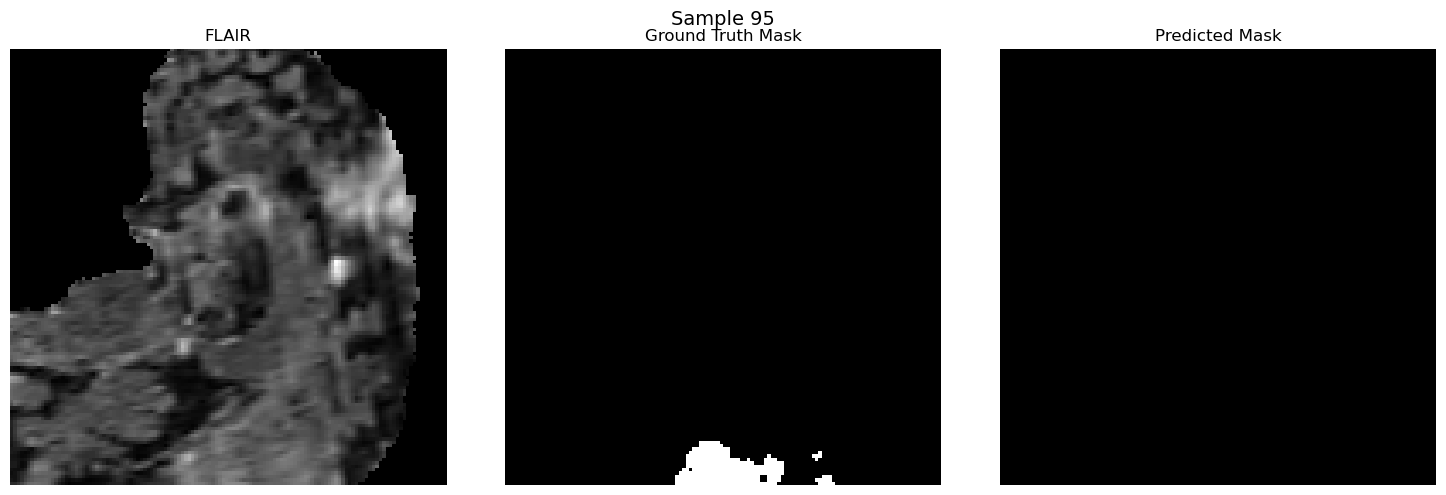

 91%|██████████████████████████████████████████████████████████████████████████       | 96/105 [00:38<00:04,  2.23it/s]

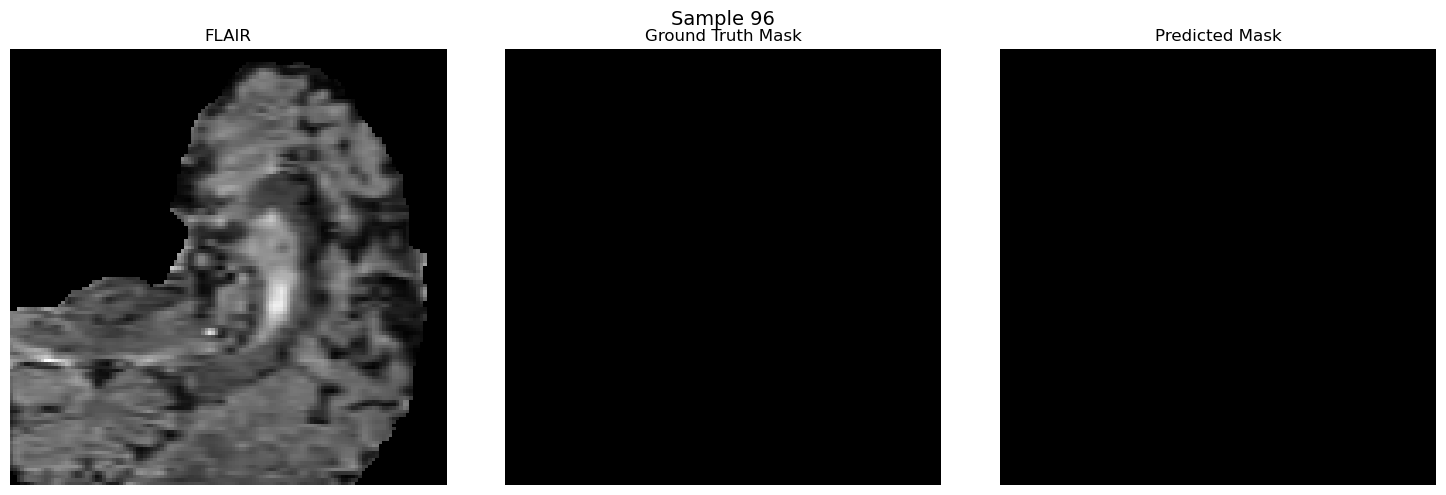

 92%|██████████████████████████████████████████████████████████████████████████▊      | 97/105 [00:39<00:03,  2.25it/s]

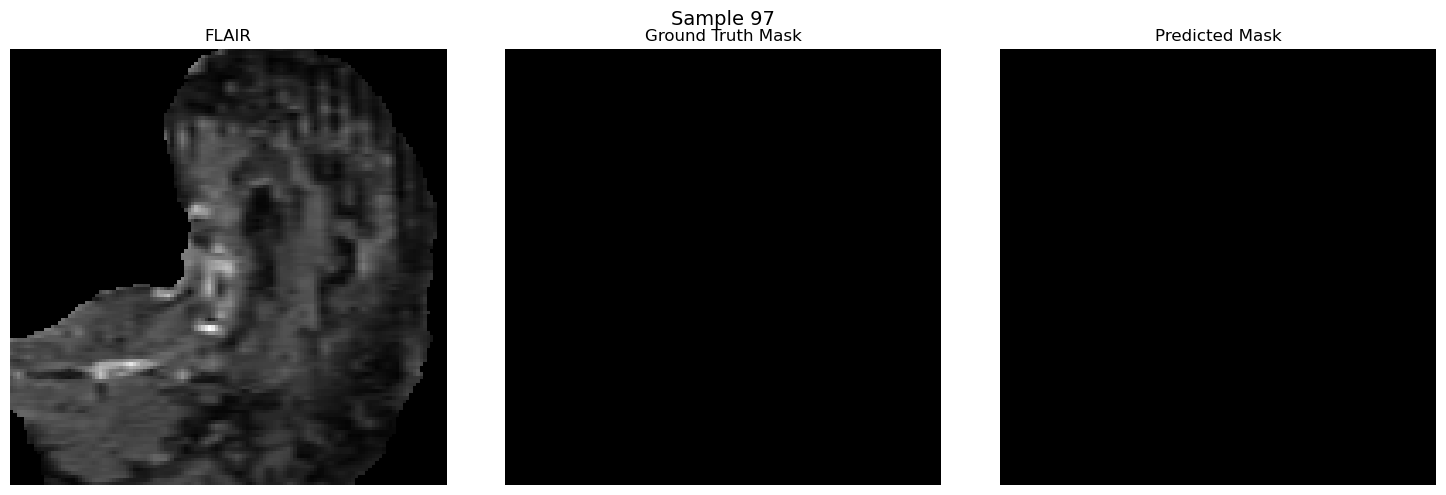

 93%|███████████████████████████████████████████████████████████████████████████▌     | 98/105 [00:39<00:03,  2.30it/s]

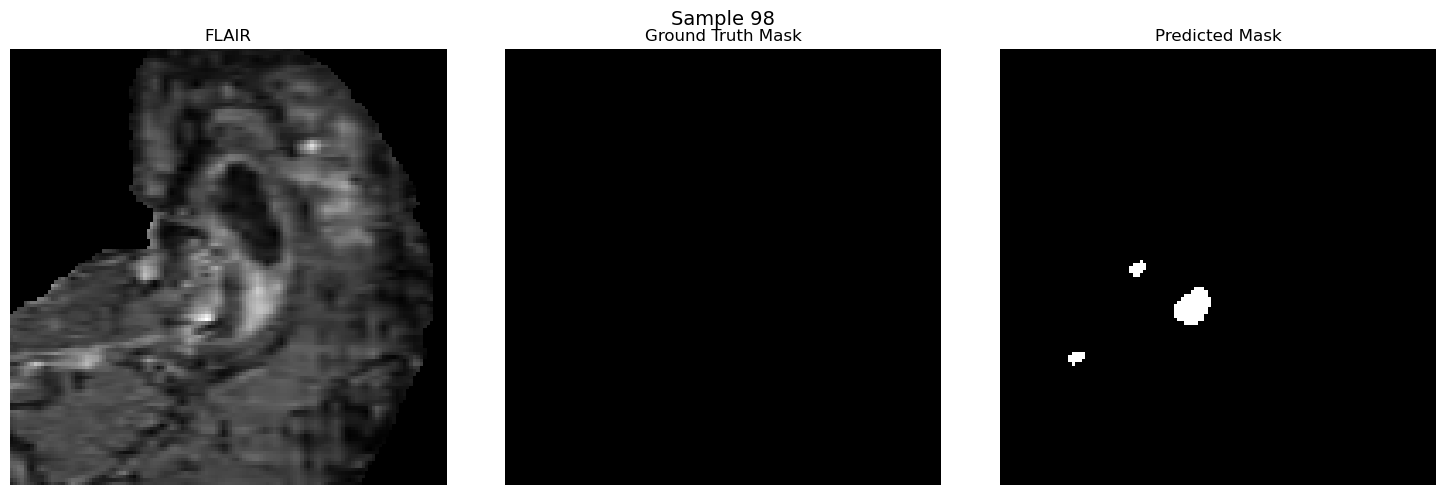

 94%|████████████████████████████████████████████████████████████████████████████▎    | 99/105 [00:40<00:02,  2.33it/s]

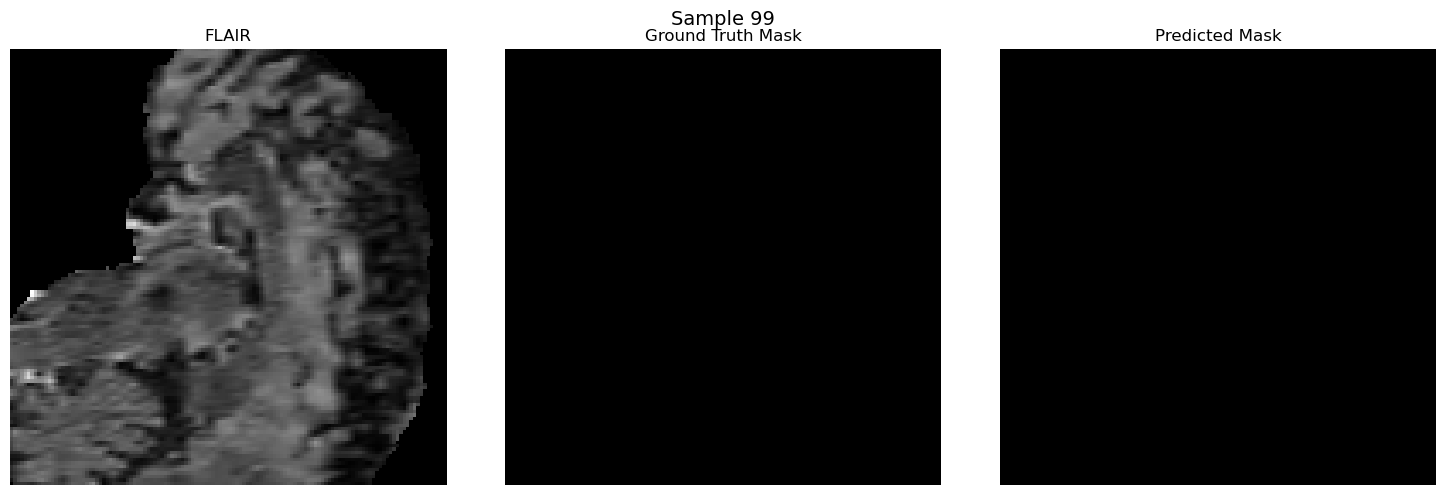

 95%|████████████████████████████████████████████████████████████████████████████▏   | 100/105 [00:40<00:02,  2.29it/s]

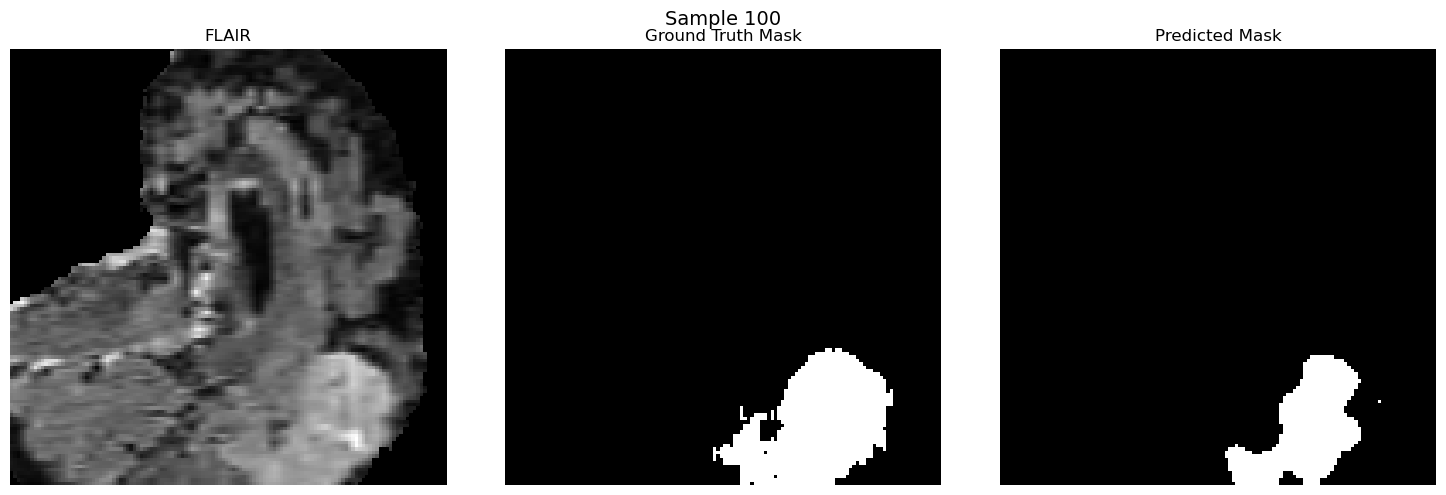

 96%|████████████████████████████████████████████████████████████████████████████▉   | 101/105 [00:40<00:01,  2.27it/s]

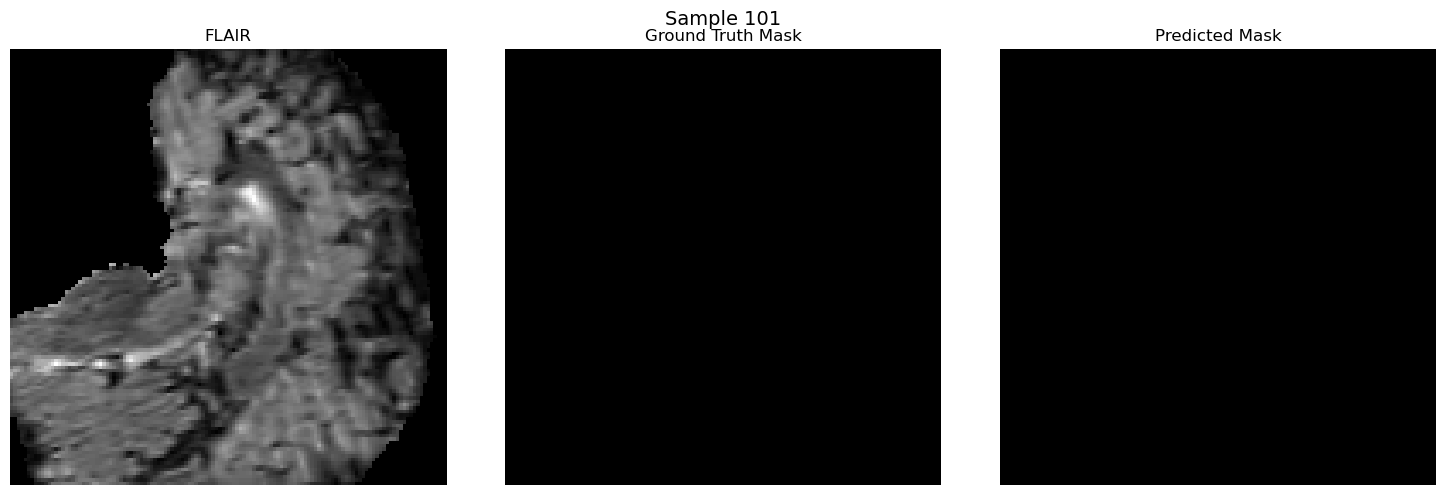

 97%|█████████████████████████████████████████████████████████████████████████████▋  | 102/105 [00:41<00:01,  2.26it/s]

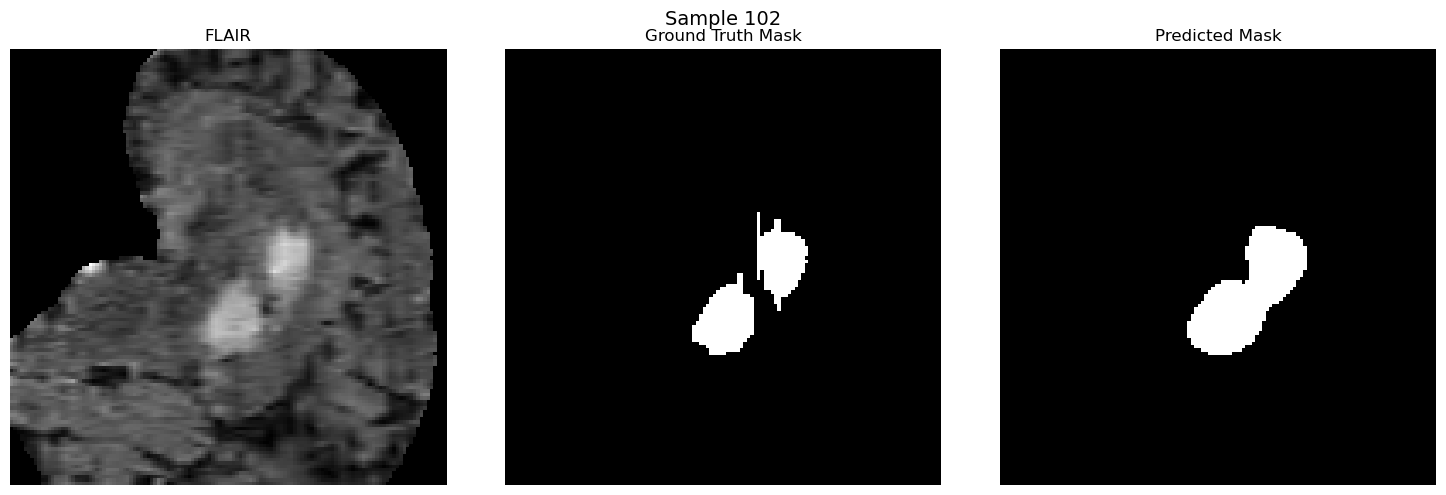

 98%|██████████████████████████████████████████████████████████████████████████████▍ | 103/105 [00:42<00:01,  1.89it/s]

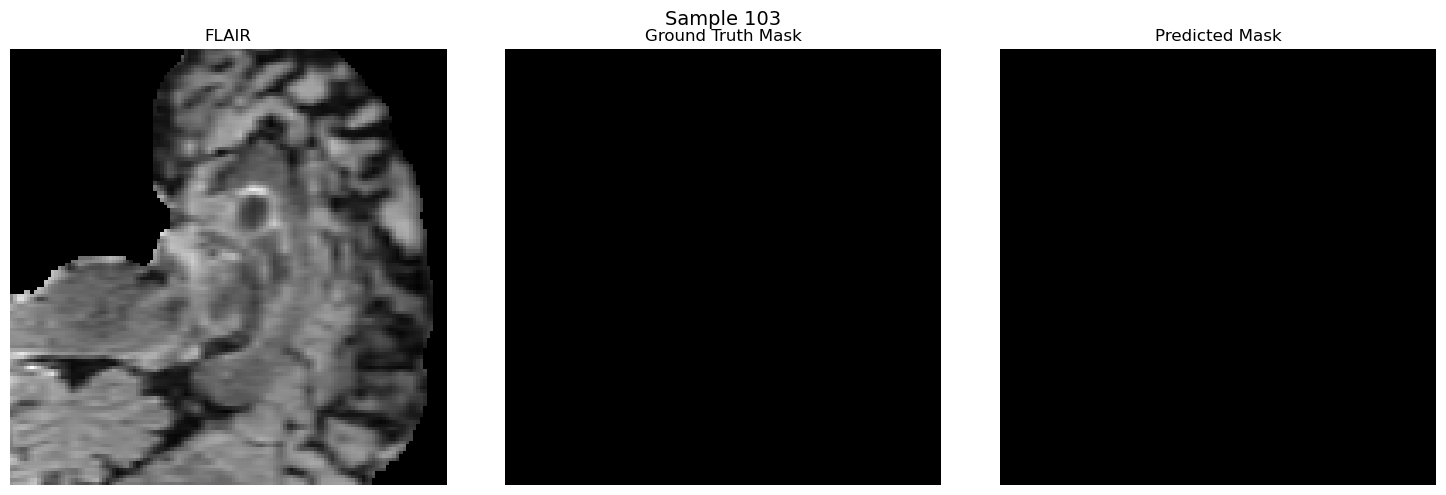

 99%|███████████████████████████████████████████████████████████████████████████████▏| 104/105 [00:42<00:00,  2.03it/s]

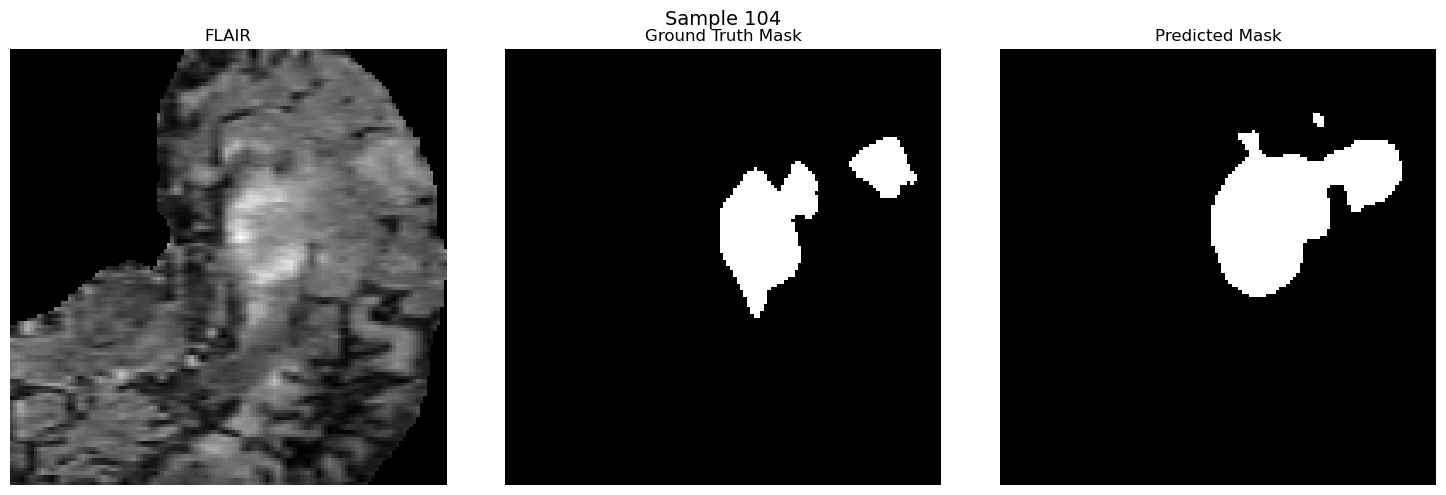

100%|████████████████████████████████████████████████████████████████████████████████| 105/105 [00:42<00:00,  2.44it/s]


In [6]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch.nn as nn
import torch.nn.functional as F

# -------------------- UNet3D (same as training) --------------------
class UNet3D(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, init_features=16):
        super(UNet3D, self).__init__()
        features = init_features
        self.encoder1 = self.contract_block(in_channels, features)
        self.encoder2 = self.contract_block(features, features * 2)
        self.encoder3 = self.contract_block(features * 2, features * 4)
        self.encoder4 = self.contract_block(features * 4, features * 8)
        self.bottleneck = self.contract_block(features * 8, features * 16, dropout=0.3)

        self.upconv4 = self.expand_block(features * 16, features * 8)
        self.decoder4 = self.contract_block(features * 16, features * 8)

        self.upconv3 = self.expand_block(features * 8, features * 4)
        self.decoder3 = self.contract_block(features * 8, features * 4)

        self.upconv2 = self.expand_block(features * 4, features * 2)
        self.decoder2 = self.contract_block(features * 4, features * 2)

        self.upconv1 = self.expand_block(features * 2, features)
        self.decoder1 = self.contract_block(features * 2, features)

        self.out_conv = nn.Conv3d(features, out_channels, kernel_size=1)

    def contract_block(self, in_channels, out_channels, dropout=0.1):
        return nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Dropout3d(dropout),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def expand_block(self, in_channels, out_channels):
        return nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

    def forward(self, x):
        c1 = self.encoder1(x); p1 = F.max_pool3d(c1, 2)
        c2 = self.encoder2(p1); p2 = F.max_pool3d(c2, 2)
        c3 = self.encoder3(p2); p3 = F.max_pool3d(c3, 2)
        c4 = self.encoder4(p3); p4 = F.max_pool3d(c4, 2)
        bn = self.bottleneck(p4)
        u4 = self.upconv4(bn)
        d4 = self.decoder4(torch.cat([u4, c4], dim=1))
        u3 = self.upconv3(d4)
        d3 = self.decoder3(torch.cat([u3, c3], dim=1))
        u2 = self.upconv2(d3)
        d2 = self.decoder2(torch.cat([u2, c2], dim=1))
        u1 = self.upconv1(d2)
        d1 = self.decoder1(torch.cat([u1, c1], dim=1))
        return self.out_conv(d1)

# -------------------- Visualizer --------------------
def visualize_prediction(image, mask, pred_mask, probs, idx):
    slice_idx = image.shape[1] // 2  # middle slice in depth

    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Sample {idx}", fontsize=14)

    plt.subplot(1, 3, 1)
    plt.imshow(image[0, slice_idx], cmap='gray')
    plt.title("FLAIR")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask[0, slice_idx], cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask[slice_idx], cmap='gray')
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# -------------------- Inference --------------------
def run_test_visualization(test_image_dir, test_mask_dir, model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = UNet3D(in_channels=3, out_channels=1).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    image_paths = sorted([os.path.join(test_image_dir, f) for f in os.listdir(test_image_dir)])
    mask_paths = sorted([os.path.join(test_mask_dir, f) for f in os.listdir(test_mask_dir)])

    for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
        try:
            image = np.load(img_path)  # shape: [128, 128, 128, 3]
            mask = np.load(mask_path)  # shape: [128, 128, 128, 4]

            if mask.ndim == 4:
                mask = np.argmax(mask, axis=-1)
            mask = (mask > 0).astype(np.uint8)

            image = np.transpose(image, (3, 0, 1, 2))  # [3, D, H, W]
            mask = np.expand_dims(mask, axis=0)       # [1, D, H, W]

            # 💥 FIXED: Explicit float32 conversion
            image_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).to(device)

            with torch.no_grad():
                output = model(image_tensor)
                probs = torch.sigmoid(output).cpu().squeeze().numpy()  # [D, H, W]
                pred_mask = (probs > 0.3).astype(np.uint8)

            visualize_prediction(image, mask, pred_mask, probs, idx)

        except Exception as e:
            print(f"❌ Error on sample {idx}: {e}")

# -------------------- Run --------------------
run_test_visualization(
    test_image_dir="BraTS2020_TrainingData/input_data_128/test/images",
    test_mask_dir="BraTS2020_TrainingData/input_data_128/test/masks",
    model_path="best_model_seg.pth"
)


In [7]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch.nn as nn
import torch.nn.functional as F

# -------------------- UNet3D Model --------------------
class UNet3D(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, init_features=16):
        super(UNet3D, self).__init__()
        features = init_features
        self.encoder1 = self.contract_block(in_channels, features)
        self.encoder2 = self.contract_block(features, features * 2)
        self.encoder3 = self.contract_block(features * 2, features * 4)
        self.encoder4 = self.contract_block(features * 4, features * 8)
        self.bottleneck = self.contract_block(features * 8, features * 16, dropout=0.3)

        self.upconv4 = self.expand_block(features * 16, features * 8)
        self.decoder4 = self.contract_block(features * 16, features * 8)

        self.upconv3 = self.expand_block(features * 8, features * 4)
        self.decoder3 = self.contract_block(features * 8, features * 4)

        self.upconv2 = self.expand_block(features * 4, features * 2)
        self.decoder2 = self.contract_block(features * 4, features * 2)

        self.upconv1 = self.expand_block(features * 2, features)
        self.decoder1 = self.contract_block(features * 2, features)

        self.out_conv = nn.Conv3d(features, out_channels, kernel_size=1)

    def contract_block(self, in_channels, out_channels, dropout=0.1):
        return nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Dropout3d(dropout),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def expand_block(self, in_channels, out_channels):
        return nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

    def forward(self, x):
        c1 = self.encoder1(x); p1 = F.max_pool3d(c1, 2)
        c2 = self.encoder2(p1); p2 = F.max_pool3d(c2, 2)
        c3 = self.encoder3(p2); p3 = F.max_pool3d(c3, 2)
        c4 = self.encoder4(p3); p4 = F.max_pool3d(c4, 2)
        bn = self.bottleneck(p4)
        u4 = self.upconv4(bn)
        d4 = self.decoder4(torch.cat([u4, c4], dim=1))
        u3 = self.upconv3(d4)
        d3 = self.decoder3(torch.cat([u3, c3], dim=1))
        u2 = self.upconv2(d3)
        d2 = self.decoder2(torch.cat([u2, c2], dim=1))
        u1 = self.upconv1(d2)
        d1 = self.decoder1(torch.cat([u1, c1], dim=1))
        return self.out_conv(d1)

# -------------------- Visualization Helper --------------------
def visualize_prediction(image, mask, pred_mask, probs, idx, save_dir):
    slice_idx = image.shape[1] // 2  # middle slice in D

    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Test Sample {idx}", fontsize=14)

    plt.subplot(1, 3, 1)
    plt.imshow(image[0, slice_idx], cmap='gray')
    plt.title("FLAIR")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask[0, slice_idx], cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask[slice_idx], cmap='gray')
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(os.path.join(save_dir, f"prediction_{idx}.png"))
    plt.close()

# -------------------- Run Inference and Save --------------------
def run_test_visualization(test_image_dir, test_mask_dir, model_path, save_dir="test_prediction_visuals"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = UNet3D(in_channels=3, out_channels=1).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    image_paths = sorted([os.path.join(test_image_dir, f) for f in os.listdir(test_image_dir) if f.endswith(".npy")])
    mask_paths = sorted([os.path.join(test_mask_dir, f) for f in os.listdir(test_mask_dir) if f.endswith(".npy")])

    for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
        try:
            image = np.load(img_path).astype(np.float32)  # [128, 128, 128, 3]
            mask = np.load(mask_path)                     # [128, 128, 128, 4] (one-hot)

            if mask.ndim == 4:
                mask = np.argmax(mask, axis=-1)           # [128, 128, 128]
            mask = (mask > 0).astype(np.uint8)
            mask = np.expand_dims(mask, axis=0)           # [1, D, H, W]

            image = np.transpose(image, (3, 0, 1, 2))      # [3, D, H, W]
            image_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).to(device)  # [1, 3, D, H, W]

            with torch.no_grad():
                output = model(image_tensor)
                probs = torch.sigmoid(output).cpu().squeeze().numpy()  # [D, H, W]
                pred_mask = (probs > 0.3).astype(np.uint8)

            visualize_prediction(image, mask, pred_mask, probs, idx, save_dir)

        except Exception as e:
            print(f"❌ Error on sample {idx}: {e}")

# -------------------- Run --------------------
run_test_visualization(
    test_image_dir="BraTS2020_TrainingData/input_data_128/test/images",
    test_mask_dir="BraTS2020_TrainingData/input_data_128/test/masks",
    model_path="best_model_seg.pth",
    save_dir="test_prediction_visuals"
)


100%|████████████████████████████████████████████████████████████████████████████████| 105/105 [00:44<00:00,  2.35it/s]


In [8]:
import numpy as np

# Dice Score per class
def dice_score_per_class(pred, true, class_id):
    pred_bin = (pred == class_id).astype(np.uint8)
    true_bin = (true == class_id).astype(np.uint8)
    
    intersection = np.sum(pred_bin * true_bin)
    denominator = np.sum(pred_bin) + np.sum(true_bin)

    return 2.0 * intersection / (denominator + 1e-8)

# IoU per class
def iou_score_per_class(pred, true, class_id):
    pred_bin = (pred == class_id).astype(np.uint8)
    true_bin = (true == class_id).astype(np.uint8)

    intersection = np.sum(pred_bin * true_bin)
    union = np.sum(pred_bin) + np.sum(true_bin) - intersection

    return intersection / (union + 1e-8)


In [9]:
def evaluate_on_test_set(test_image_dir, test_mask_dir, model_path, save_path="test_metrics.txt"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = UNet3D(in_channels=3, out_channels=1).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    image_paths = sorted([os.path.join(test_image_dir, f) for f in os.listdir(test_image_dir) if f.endswith(".npy")])
    mask_paths = sorted([os.path.join(test_mask_dir, f) for f in os.listdir(test_mask_dir) if f.endswith(".npy")])

    dice_scores = []
    iou_scores = []

    for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
        try:
            image = np.load(img_path).astype(np.float32)  # [128, 128, 128, 3]
            mask = np.load(mask_path)  # [128, 128, 128, 4] or [128, 128, 128]

            if mask.ndim == 4:  # one-hot to label
                mask = np.argmax(mask, axis=-1)
            mask = (mask > 0).astype(np.uint8)  # WT (whole tumor)

            image = np.transpose(image, (3, 0, 1, 2))  # [3, D, H, W]
            image_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).to(device)  # [1, 3, D, H, W]

            with torch.no_grad():
                output = model(image_tensor)
                probs = torch.sigmoid(output).cpu().squeeze().numpy()
                pred = (probs > 0.3).astype(np.uint8)  # [D, H, W]

            # Evaluate for class 1 (whole tumor)
            dice = dice_score_per_class(pred, mask, class_id=1)
            iou = iou_score_per_class(pred, mask, class_id=1)

            dice_scores.append(dice)
            iou_scores.append(iou)

        except Exception as e:
            print(f"❌ Error on sample {idx}: {e}")

    # Save + print
    avg_dice = np.mean(dice_scores)
    avg_iou = np.mean(iou_scores)

    with open(save_path, "w") as f:
        f.write(f"Test Samples: {len(dice_scores)}\n")
        f.write(f"Mean Dice Score (Whole Tumor): {avg_dice:.4f}\n")
        f.write(f"Mean IoU Score  (Whole Tumor): {avg_iou:.4f}\n")

    print("\n✅ Evaluation Complete:")
    print(f"• Test Samples       : {len(dice_scores)}")
    print(f"• Mean Dice (WT)     : {avg_dice:.4f}")
    print(f"• Mean IoU  (WT)     : {avg_iou:.4f}")
    print(f"• Metrics saved to   : {save_path}")


In [10]:
evaluate_on_test_set(
    test_image_dir="BraTS2020_TrainingData/input_data_128/test/images",
    test_mask_dir="BraTS2020_TrainingData/input_data_128/test/masks",
    model_path="best_model_seg.pth",
    save_path="test_metrics.txt"
)


100%|████████████████████████████████████████████████████████████████████████████████| 105/105 [00:23<00:00,  4.52it/s]


✅ Evaluation Complete:
• Test Samples       : 105
• Mean Dice (WT)     : 0.8423
• Mean IoU  (WT)     : 0.7497
• Metrics saved to   : test_metrics.txt
